<a href="https://colab.research.google.com/github/SMOULD07/Medical-image-analysis/blob/main/TP_VMI_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M2 VMI - TP : Medical image analysis
---

Garance MARTIN (adapted from TP_BIOMED Isabelle Bloch)

* Name: OULD HOCINE
* Last name: Samir
* Student ID: 213442628FC






**This assignment is graded and must be submitted by 14 November on Moodle.** You will upload a final notebook written as a report with the presentation of methods, results and comments on your observations.

## Objectives

The aim of this practical work is to experiment various segmentation methods on medical images:

* Brain MRI for corpus callosum segmentation
* Temporal MRI sequences for heart segmentation (in particular left ventricle)
* Retinopathy images for vessel segmentation (DRIVE dataset)

For each image type, you have to apply multiple segmentation methods (if adapted):
* manual threshold
* active contours
* vesselness filters
* A simple U-Net (with Pytorch + MONAI) and a small number of epochs

And evaluate them with the appropriate evaluation methods (quantitative and qualitative).





## Load data


From your Google Drive:
* Create a new directory for the practical work
* Upload the zip file of images and unzip it
* Connect your Drive to Google Colab with

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
Working_directory = "/content/drive/MyDrive/TP medical images analysis/dataTPseg/"

### Importation of useful libraries

In [4]:
import glob
from skimage.io import imread
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import AxesGrid
from skimage.measure import find_contours
from scipy.spatial.distance import dice
from skimage.transform import rescale
from scipy.io import loadmat

from scipy import ndimage as ndi
from skimage import io as skio
import skimage.morphology as morpho
from skimage.draw import line
from skimage.transform import rescale
from skimage.filters import gaussian
from skimage.segmentation import active_contour
from skimage import img_as_float

import torch
import torch.nn.functional as F
# You are encouraged to add any useful library

# Brain MRI

Here you can select medial slices of the brain of 4 different subjects. You also have manual segmentations of the corpus callosum.

In [5]:
import os

brainMRI_path = os.path.join(Working_directory, "brainMRI")

listImagesbrainMRI = [
    os.path.join(brainMRI_path, nom)
    for nom in [
        "MRIs4-seg.png",
        "MRIs1-seg.png",
        "MRIs3-seg.png",
        "MRIs2-seg.png"
    ]
]

print("There are", len(listImagesbrainMRI), "brain MRI images")
print(listImagesbrainMRI)

There are 4 brain MRI images
['/content/drive/MyDrive/TP medical images analysis/dataTPseg/brainMRI/MRIs4-seg.png', '/content/drive/MyDrive/TP medical images analysis/dataTPseg/brainMRI/MRIs1-seg.png', '/content/drive/MyDrive/TP medical images analysis/dataTPseg/brainMRI/MRIs3-seg.png', '/content/drive/MyDrive/TP medical images analysis/dataTPseg/brainMRI/MRIs2-seg.png']


/content/drive/MyDrive/TP medical images analysis/dataTPseg/brainMRI/MRIs1-seg.png
Reading image  /content/drive/MyDrive/TP medical images analysis/dataTPseg/brainMRI/MRIs1.png


Text(0.5, 1.0, 'Image with segmentation\n corpus callosum')

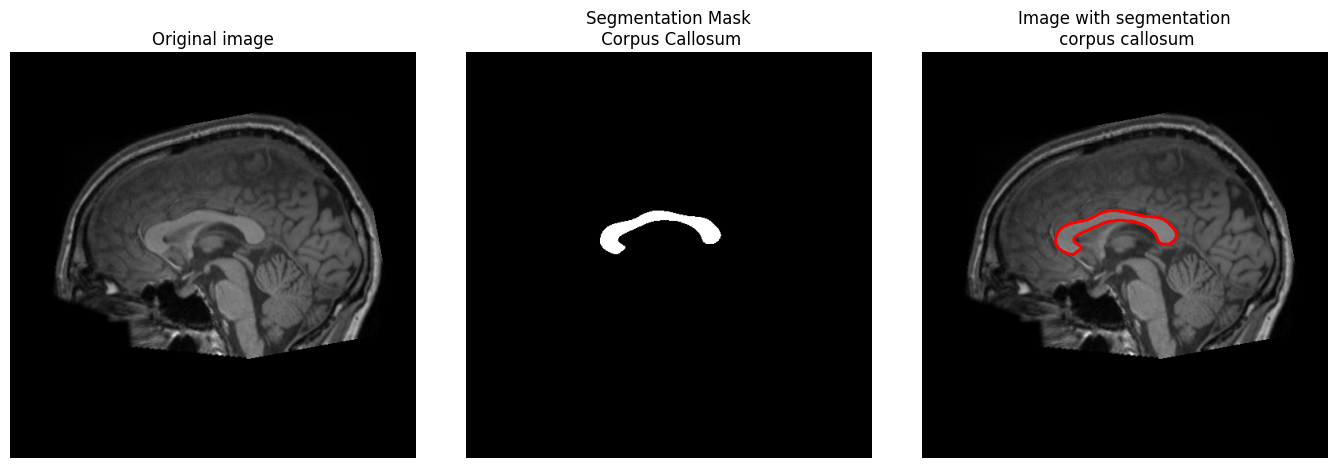

In [6]:
# Choose a figure and plot it with the ground truth segmentation
indexIm=1

# Brain MRI
filename_Segmentation = listImagesbrainMRI[indexIm]
print(filename_Segmentation)
im_Seg = imread(filename_Segmentation)
filename = filename_Segmentation[:-8] + '.png'
imG = imread(filename)

print('Reading image ', filename)

if imG.shape != im_Seg.shape:
  raise NameError('image and mask should have the same shape, problem...')

# In Im Seg we have masks of the corpus callosum
maskCC=im_Seg==255
contourMask = find_contours(maskCC, 0.5)

fig = plt.figure(figsize=(17, 7))
grid = AxesGrid(fig, 111,
                nrows_ncols = (1, 3),
                axes_pad = 0.5)
grid[0].imshow(imG, cmap='gray')
grid[0].axis('off')
grid[0].set_title("Original image")
grid[1].imshow(maskCC,cmap='gray')
grid[1].axis('off')
grid[1].set_title("Segmentation Mask\n Corpus Callosum")
grid[2].imshow(imG, cmap='gray')
for contour in contourMask:
  grid[2].plot(contour[:, 1], contour[:, 0], linewidth=2, c='r')
grid[2].axis('off')
grid[2].set_title("Image with segmentation\n corpus callosum")


# Durant cette premiére expérience , je souhaite commancer avec la technique du **seuillage manuel** qui constitura notre premiére methode de référence ( notre baseline )

### Observer l'image et son histogramme**

Le seuillage consiste à sélectionner des pixels en fonction de leur intensité Mais avant de choisir un seuil, nous devons comprendre les caractéristiques de l'image :
- L'image originale nous permet de localiser le corps calleux et d'observer son contraste avec les tissus voisins.
- L'histogramme nous indique comment les intensités des pixels sont distribuées.
- Les intensités minimale et maximale nous permettent de connaître l'échelle des valeurs utilisées.
Cela nous aidera à déterminer si un simple seuil peut isoler le corps calleux ou si d'autres structures présentent des intensités similaires.

Dimensions de l'image : (512, 512)
Type de données : uint8
Intensité minimale : 0
Intensité maximale : 255


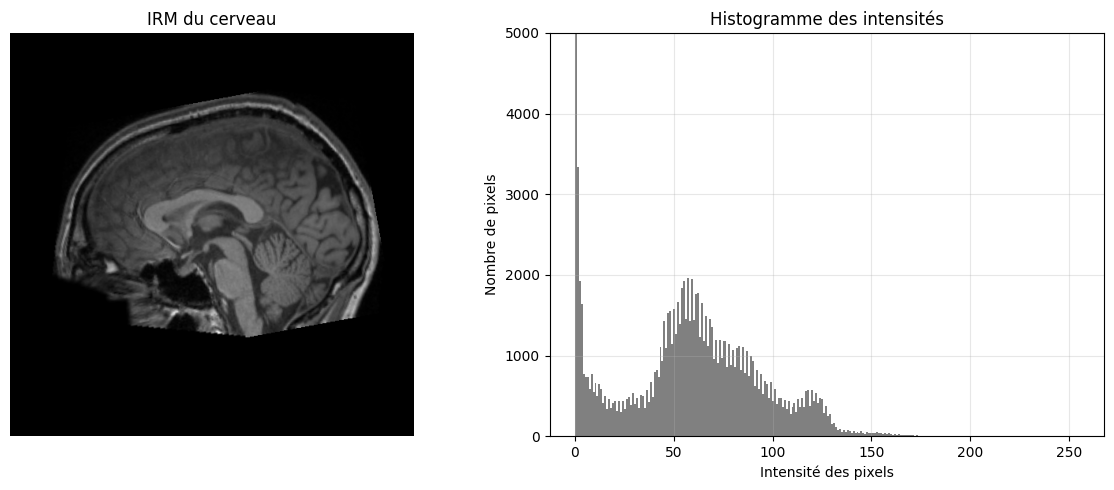

In [7]:
# Analyse de l'image IRM du cerveau

print("Dimensions de l'image :", imG.shape)
print("Type de données :", imG.dtype)
print("Intensité minimale :", imG.min())
print("Intensité maximale :", imG.max())

plt.figure(figsize=(12, 5))

# Image originale
plt.subplot(1, 2, 1)
plt.imshow(imG, cmap="gray")
plt.title("IRM du cerveau")
plt.axis("off")

# Histogramme des intensités
plt.subplot(1, 2, 2)
plt.hist(imG.ravel(), bins=256, color="gray")
plt.title("Histogramme des intensités")
plt.xlabel("Intensité des pixels")
plt.ylabel("Nombre de pixels")

# Limiter l'axe Y pour mieux observer les intensités
plt.ylim(0, 5000)

# Ajouter une grille pour faciliter la lecture
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

les caractéristiques de notre image sont les suivantes :

* **Dimensions :** 512 × 512	c.a.d l'iamge a 262144 px
* **Type:** uint8	c.a.d Chaque pixel est codé sur 8 bits
* **Intensité:** minimale	0	--> Noir
* **Intensité:**  maximale	255	--> Blanc

Apres analyse des résultats de l'histogramme on remarque les points suivants :

* un pic très important à l'intensité 0 : Cela s'explique par la présence d'une grande région noire autour du cerveau.

Ces pixels représentent le fond de l'image et non les tissus cérébraux.

* une distribution plus étalée entre environ 40 et 120 : Cette zone correspond à une partie importante des tissus visibles sur l'IRM.

Cela signifie que plusieurs structures anatomiques possèdent des intensités proches.

#### Je pense qu'il sera probablement difficile d'isoler correctement le corps calleux uniquement avec un seuil d'intensité, car d'autres tissus peuvent être aussi clairs que lui.

## **Expérimenter le seuillage manuel** :

Pour cela nous allons essayer trois seuils différents (50, 80 et 110) qui vont nous permetter d'étudier l'effet du seuil sur la segmentation.

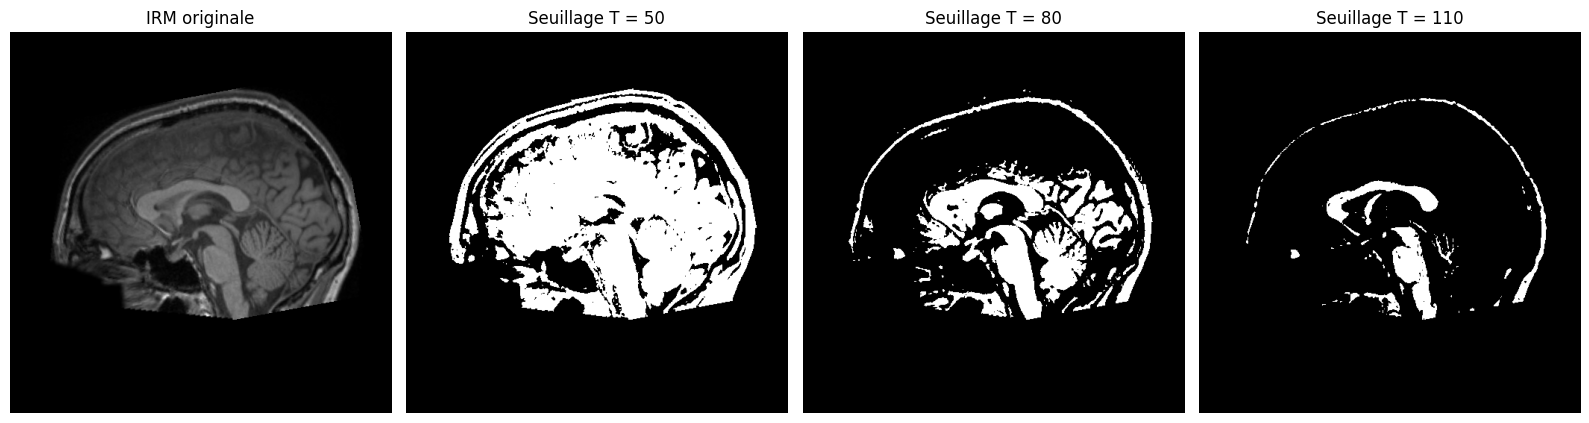

In [8]:
# Différents seuils à tester
seuils = [50, 80, 110]

plt.figure(figsize=(16, 5))

# Image originale
plt.subplot(1, 4, 1)
plt.imshow(imG, cmap="gray")
plt.title("IRM originale")
plt.axis("off")

# Application des différents seuils
for i, seuil in enumerate(seuils):

    # Création du masque binaire
    masque = imG > seuil

    # Affichage du résultat
    plt.subplot(1, 4, i + 2)
    plt.imshow(masque, cmap="gray")
    plt.title(f"Seuillage T = {seuil}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Les résultats montrent qu'un seuil faible (T = 50) entraîne une sélection excessive de tissus cérébraux. Lorsque le seuil augmente (T = 80), la segmentation devient plus sélective, mais plusieurs structures anatomiques restent présentes.

Avec T = 110, le corps calleux devient plus facilement identifiable, bien que d'autres régions, notamment le tronc cérébral et certains contours du crâne, soient également détectées.

Cette expérience met en évidence les limites du seuillage global pour segmenter une structure anatomique précise. En effet, cette méthode repose uniquement sur l'intensité des pixels et ne prend pas en compte les caractéristiques géométriques ou anatomiques du corps calleux.

*Pour cela la prochaine étape c'est de faire une comparaison avec le masque de référence pour déterminer quel seuil produit la segmentation la plus proche de la vérité terrain.*

## **Évaluation avec le Dice :**

In [9]:

reference = maskCC

# Fonction pour calculer le coefficient de Dice
def calcul_dice(prediction, reference):

    prediction = prediction.astype(bool)
    reference = reference.astype(bool)

    intersection = np.logical_and(prediction, reference).sum()

    total = prediction.sum() + reference.sum()

    if total == 0:
        return 1.0

    return 2 * intersection / total


# Seuils testés précédemment
seuils = [50, 80, 110]

# Calcul du Dice pour chaque seuil
for seuil in seuils:

    prediction = imG > seuil

    dice = calcul_dice(prediction, reference)

    print(f"Seuil T = {seuil} : Dice = {dice:.4f}")

Seuil T = 50 : Dice = 0.0758
Seuil T = 80 : Dice = 0.1703
Seuil T = 110 : Dice = 0.3791


Le coefficient de Dice permet de mesurer le recouvrement entre la segmentation obtenue et le masque de référence.

Les résultats montrent que le dice augmente avec le seuil, car moins de structures non pertinentes sont sélectionnées. Cependant, même avec T=110, le résultat reste faible.

Cela montre que **le seuillage manuel est insuffisant pour isoler précisément le corps calleux**, car plusieurs tissus présentent des intensités similaires.

# **Seuillage automatique d'Otsu :**

Cet approche a pour but de vérifier si le choix automatique d'un seuil permet d'obtenir un meilleur recouvrement avec le masque de référence (maskCC).

Seuil calculé par Otsu : 38
Score Dice d'Otsu : 0.0643


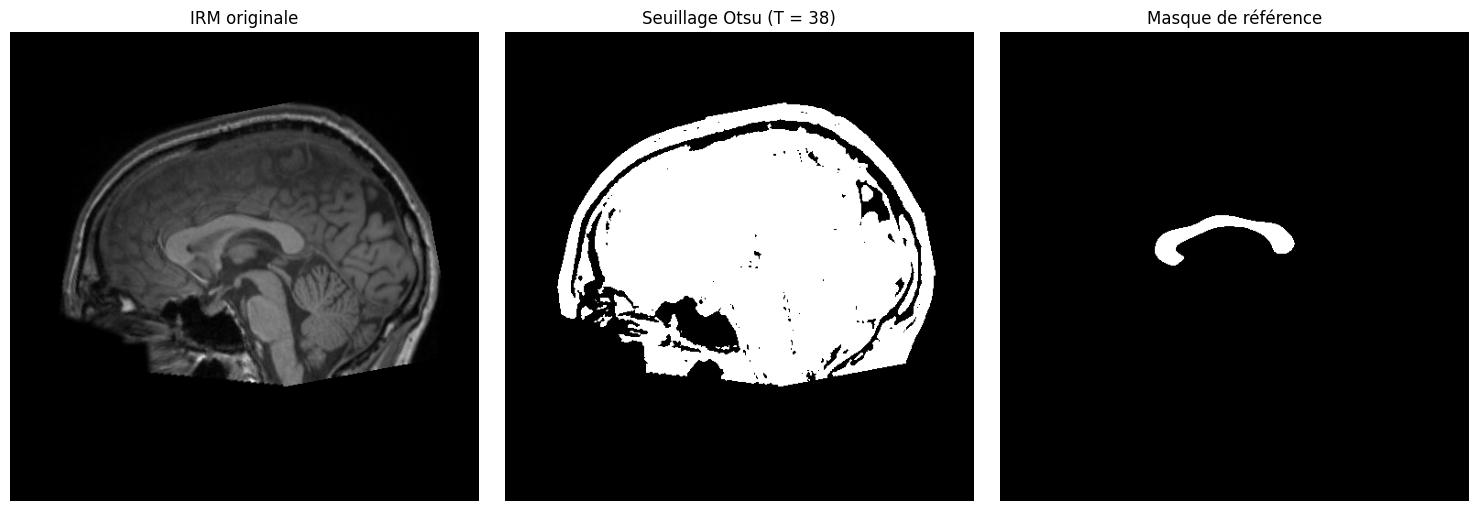

In [10]:
# =====================================================
# EXPÉRIENCE 2 : SEUILLAGE AUTOMATIQUE D'OTSU
# =====================================================
from skimage.filters import threshold_otsu

# Calcul automatique du seuil d'Otsu
seuil_otsu = threshold_otsu(imG)

# Segmentation binaire
masque_otsu = imG > seuil_otsu

# Évaluation avec le Dice
dice_otsu = calcul_dice(masque_otsu, maskCC)

print(f"Seuil calculé par Otsu : {seuil_otsu}")
print(f"Score Dice d'Otsu : {dice_otsu:.4f}")

# Visualisation des résultats
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imG, cmap="gray")
plt.title("IRM originale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(masque_otsu, cmap="gray")
plt.title(f"Seuillage Otsu (T = {seuil_otsu})")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(maskCC, cmap="gray")
plt.title("Masque de référence")
plt.axis("off")

plt.tight_layout()
plt.show()

Otsu cherche à séparer les intensités de l'image en deux classes, sans connaître la position ni la forme du corps calleux.

Le fond noir, très présent dans notre IRM, peut également influencer le choix du seuil. C'est pour ca on obtient des résultats nettement moins bon ( tres bas) car il sélectionne de nombreuses structures cérébrales en plus du corps calleux.

**Otsu est peu adapté à cette segmentation, car il se base uniquement sur la distribution des intensités, sans tenir compte de la structure anatomique recherchée.**

# **Contours actifs classiques (Snakes):**

cette méthode fait évoluer une courbe initiale en minimisant l'énergie qui combine la régularité du contour et son attraction vers les transitions d'intensité de l'image.

L'idée est que nous placons un contour initial près du corps calleux, puis l'algorithme tente de l'ajuster automatiquement à ses limites.

Dice du Snake : 0.2689


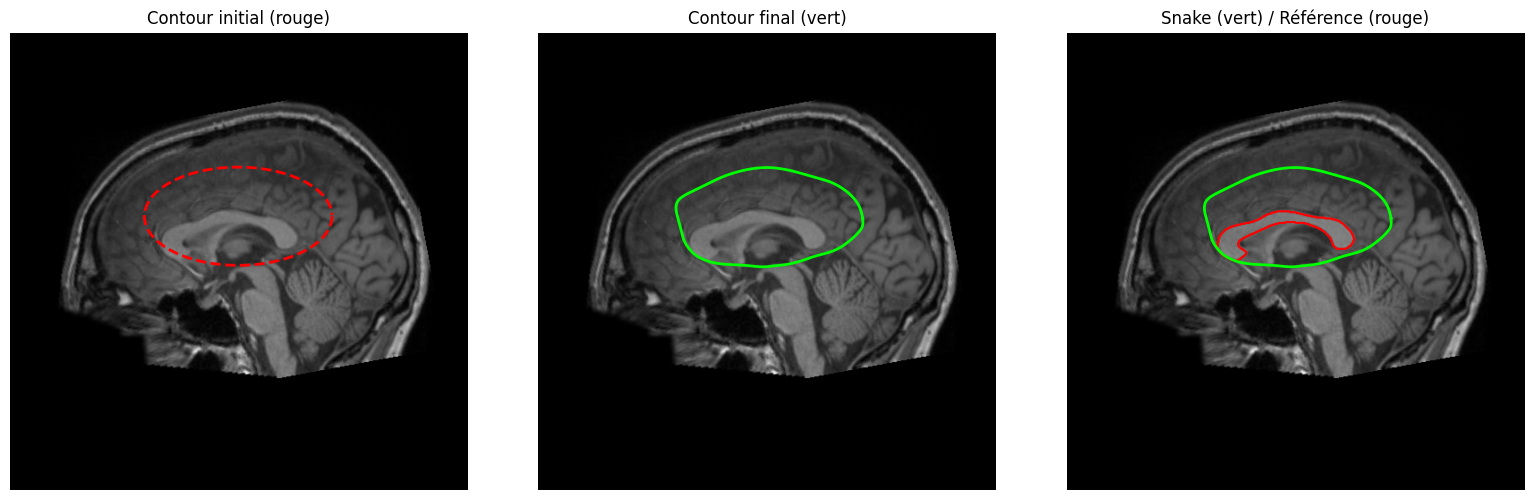

In [11]:
# =====================================================
# EXPÉRIENCE 3 : CONTOURS ACTIFS CLASSIQUES (SNAKE)
# Dataset : IRM cérébrale
# =====================================================

from skimage.draw import polygon2mask


# 1. Prétraitement : réduction du bruit
image = img_as_float(imG)
image_lissee = gaussian(image, sigma=2)

# 2. Initialisation du contour elliptique
t = np.linspace(0, 2*np.pi, 300, endpoint=False)

centre_x, centre_y = 255, 205
rayon_x, rayon_y = 105, 55

# Coordonnées (ligne, colonne)
init = np.array([
    centre_y + rayon_y * np.sin(t),
    centre_x + rayon_x * np.cos(t)
]).T

# 3. Application du Snake
snake = active_contour(
    image_lissee,
    init,
    alpha=0.01,
    beta=1,
    gamma=0.01,
    w_line=0,
    w_edge=1,
    max_num_iter=1500,
    boundary_condition='periodic'
)

# 4. Conversion du contour en masque binaire
masque_snake = polygon2mask(imG.shape, snake)

# 5. Évaluation quantitative
dice_snake = calcul_dice(masque_snake, maskCC)

print(f"Dice du Snake : {dice_snake:.4f}")

# 6. Visualisation
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(imG, cmap='gray')
axes[0].plot(init[:, 1], init[:, 0], 'r--', linewidth=2)
axes[0].set_title("Contour initial (rouge)")

axes[1].imshow(imG, cmap='gray')
axes[1].plot(snake[:, 1], snake[:, 0], 'lime', linewidth=2)
axes[1].set_title("Contour final (vert)")

axes[2].imshow(imG, cmap='gray')
axes[2].contour(maskCC, levels=[0.5], colors='red')
axes[2].plot(snake[:, 1], snake[:, 0], 'lime', linewidth=2)
axes[2].set_title("Snake (vert) / Référence (rouge)")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


Le premier Snake, initialisé avec une grande ellipse, obtient un **Dice de 0,2689**, inférieur au meilleur seuillage manuel (0,3791).

Visuellement, le contour final englobe une région trop importante et ne suit pas correctement la forme du corps calleux.

Ce résultat met en évidence la sensibilité des contours actifs à leur initialisation et aux paramètres de régularisation. Nous allons donc tester une ellipse plus petite et différentes valeurs de rigidité afin d'étudier leur influence.

Snake beta = 1   : Dice = 0.2986
Snake beta = 0.1 : Dice = 0.3887


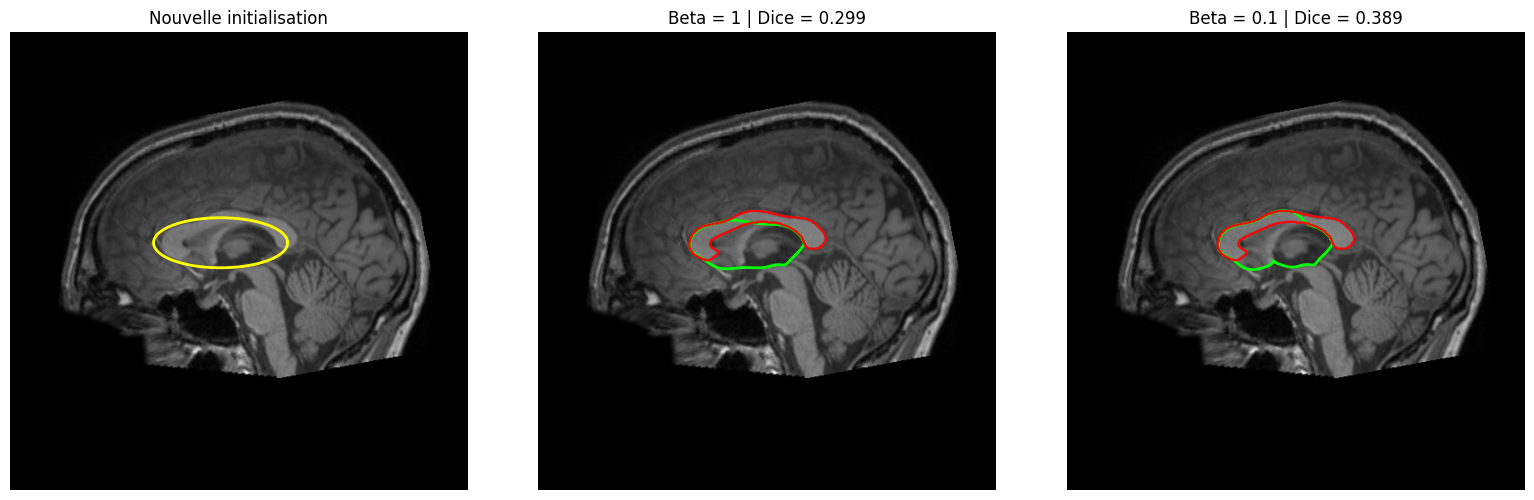

In [12]:

# 1. Nouvelle initialisation : ellipse plus petite
t = np.linspace(0, 2*np.pi, 300, endpoint=False)

centre_x, centre_y = 235, 235
rayon_x, rayon_y = 75, 28

init2 = np.array([
    centre_y + rayon_y * np.sin(t),
    centre_x + rayon_x * np.cos(t)
]).T

# 2. Snake avec beta = 1
snake_beta1 = active_contour(
    image_lissee,
    init2,
    alpha=0.01,
    beta=1,
    gamma=0.01,
    w_line=0,
    w_edge=1,
    max_num_iter=1500,
    boundary_condition='periodic'
)

# 3. Snake avec beta = 0.1
snake_beta2 = active_contour(
    image_lissee,
    init2,
    alpha=0.01,
    beta=0.1,
    gamma=0.01,
    w_line=0,
    w_edge=1,
    max_num_iter=1500,
    boundary_condition='periodic'
)

# 4. Conversion des contours en masques
masque_beta1 = polygon2mask(imG.shape, snake_beta1)
masque_beta2 = polygon2mask(imG.shape, snake_beta2)

# 5. Évaluation avec le Dice
dice_beta1 = calcul_dice(masque_beta1, maskCC)
dice_beta2 = calcul_dice(masque_beta2, maskCC)

print(f"Snake beta = 1   : Dice = {dice_beta1:.4f}")
print(f"Snake beta = 0.1 : Dice = {dice_beta2:.4f}")

# 6. Visualisation comparative
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(imG, cmap="gray")
axes[0].plot(init2[:, 1], init2[:, 0], "yellow", linewidth=2)
axes[0].set_title("Nouvelle initialisation")

axes[1].imshow(imG, cmap="gray")
axes[1].plot(snake_beta1[:, 1], snake_beta1[:, 0], "lime", linewidth=2)
axes[1].contour(maskCC, levels=[0.5], colors="red")
axes[1].set_title(f"Beta = 1 | Dice = {dice_beta1:.3f}")

axes[2].imshow(imG, cmap="gray")
axes[2].plot(snake_beta2[:, 1], snake_beta2[:, 0], "lime", linewidth=2)
axes[2].contour(maskCC, levels=[0.5], colors="red")
axes[2].set_title(f"Beta = 0.1 | Dice = {dice_beta2:.3f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Cette fois, nous avons testé une ellipse plus petite et mieux positionnée autour du corps calleux, puis comparé deux valeurs de rigidité : beta = 1 et beta = 0,1.

Nous observant que la nouvelle initialisation améliore le Dice de 0,2689 à 0,2986 pour beta = 1. En réduisant la rigidité à beta = 0,1, le Dice atteint 0,3887, ce qui dépasse légèrement le meilleur seuillage manuel (0,3791 pour T = 110), soit une amélioration de 0,0096 point de Dice.

* Une initialisation plus précise et une rigidité plus faible permettent au Snake de mieux suivre le corps calleux. Cependant, l'amélioration par rapport au seuillage manuel reste faible et la segmentation demeure imparfaite.

Une autre observation importante est que le Snake (beta = 0,1) obtient un Dice légèrement supérieur au meilleur seuillage manuel (**0,3887 contre 0,3791**). Cependant, visuellement, le Snake manque certaines parties du corps calleux, tandis que le seuillage manuel conserve davantage la structure, mais avec de nombreux faux positifs.

Cela montre que **le Dice seul ne suffit pas à évaluer la qualité anatomique d'une segmentation**. Il est donc intéressant de compléter l'évaluation par la précision, le rappel et la distance de Hausdorff.

# **les contours actifs géodésiques (MorphGAC) :**

Dice du contour géodésique : 0.3866


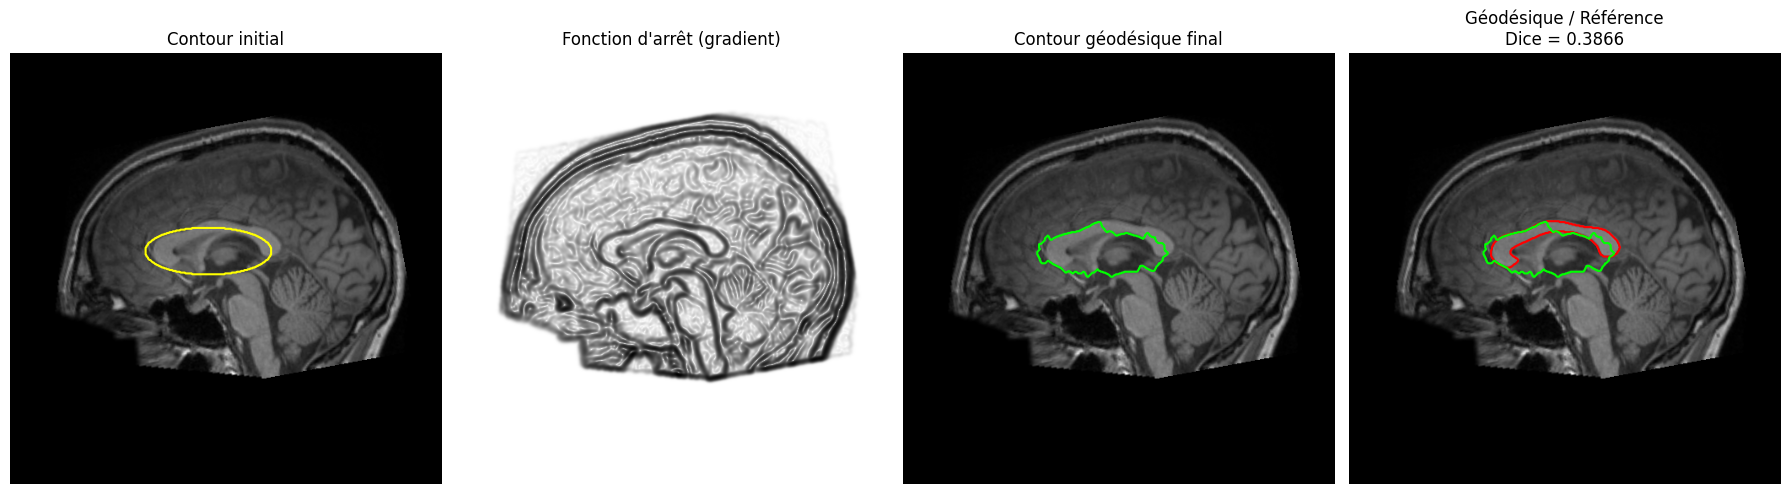

In [13]:
from skimage.segmentation import (
    morphological_geodesic_active_contour,
    inverse_gaussian_gradient
)
from skimage.draw import ellipse

# 1. Normalisation de l'image
image = imG.astype(float) / 255.0

# 2. Calcul de la fonction d'arrêt basée sur le gradient
gimage = inverse_gaussian_gradient(
    image,
    alpha=100,
    sigma=2
)

# 3. Initialisation elliptique
# Même position et dimensions que notre deuxième Snake
init_gac = np.zeros(imG.shape, dtype=np.int8)

rr, cc = ellipse(
    235, 235, 28, 75,
    shape=imG.shape
)

init_gac[rr, cc] = 1

# 4. Application du contour actif géodésique
masque_gac = morphological_geodesic_active_contour(
    gimage,
    num_iter=150,
    init_level_set=init_gac,
    smoothing=1,
    threshold='auto',
    balloon=0
)

# 5. Évaluation avec le Dice
dice_gac = calcul_dice(masque_gac, maskCC)

print(f"Dice du contour géodésique : {dice_gac:.4f}")

# 6. Visualisation des résultats
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Image originale et contour initial
axes[0].imshow(imG, cmap="gray")
axes[0].contour(init_gac, levels=[0.5], colors="yellow")
axes[0].set_title("Contour initial")

# Fonction d'arrêt basée sur le gradient
axes[1].imshow(gimage, cmap="gray")
axes[1].set_title("Fonction d'arrêt (gradient)")

# Contour final
axes[2].imshow(imG, cmap="gray")
axes[2].contour(masque_gac, levels=[0.5], colors="lime")
axes[2].set_title("Contour géodésique final")

# Comparaison avec la référence
axes[3].imshow(imG, cmap="gray")
axes[3].contour(maskCC, levels=[0.5], colors="red")
axes[3].contour(masque_gac, levels=[0.5], colors="lime")
axes[3].set_title(f"Géodésique / Référence\nDice = {dice_gac:.4f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Nous avons appliqué un contour actif géodésique en utilisant une fonction d'arrêt basée sur le gradient de l'image. Cette fonction met en évidence les transitions d'intensité permettant de guider l'évolution du contour.

Le Dice obtenu est de **0,3866**, très proche de celui du meilleur Snake classique (0,3887).

Visuellement, le contour suit certaines frontières, mais reste irrégulier et ne couvre pas correctement tout le corps calleux.

**Nous en déduisons que le gradient seul ne suffit pas à identifier les bonnes frontières anatomiques.** L'initialisation et les paramètres d'évolution jouent également un rôle important.

# **Filtre Vesselness:**

Durant ce que j'ai compris dans le cours le filtre de Frangi est une méthode permettant de mettre en évidence les structures fines et allongées.

Le corps calleux possède une forme courbée et allongée. Nous allons donc tester si le filtre de Frangi peut le mettre en évidence.

Frangi - Percentile 90 : Dice = 0.0435
Frangi - Percentile 95 : Dice = 0.0121


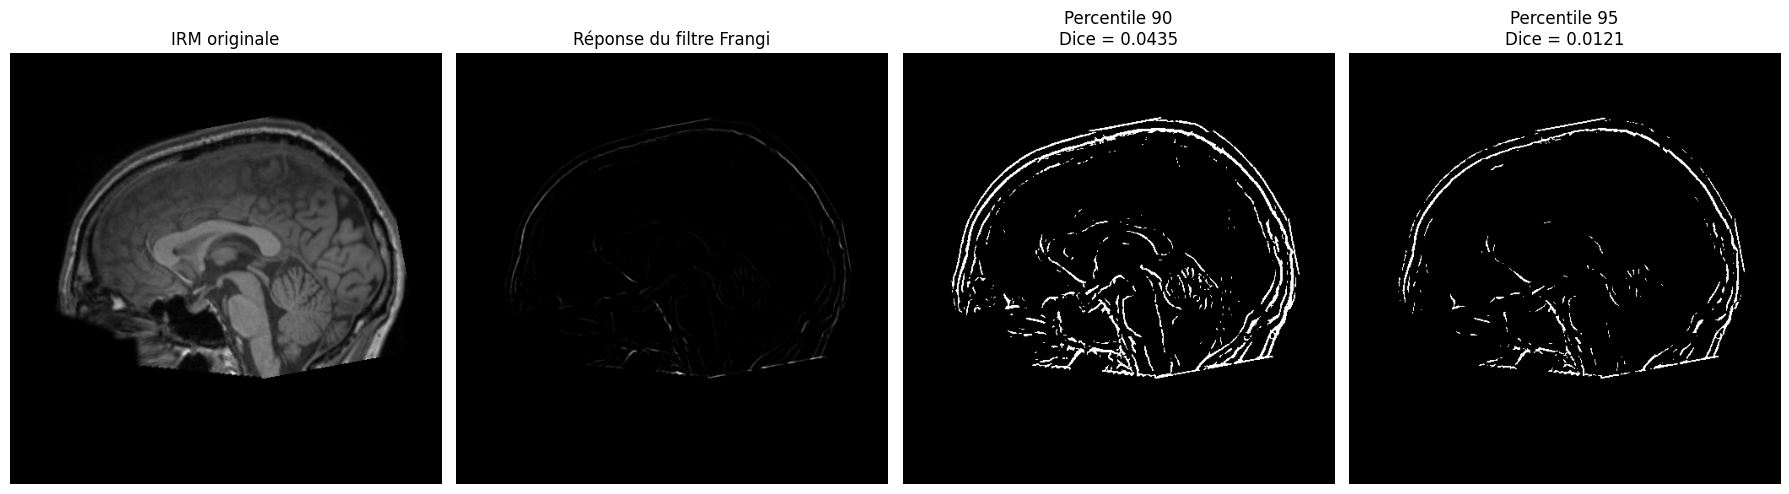

In [14]:
# =====================================================
# EXPÉRIENCE 5 : FILTRE DE FRANGI (VESSELNESS)
# Dataset : IRM cérébrale
# =====================================================
from skimage.filters import frangi

# 1. Normalisation de l'image
image = imG.astype(float) / 255.0

# 2. Application du filtre de Frangi
image_frangi = frangi(
    image,
    sigmas=range(1, 6),
    black_ridges=False
)

# 3. Seuillage de la réponse de Frangi
# On teste deux seuils exploratoires
reponses = image_frangi[image_frangi > 0]

seuil_90 = np.percentile(reponses, 90)
seuil_95 = np.percentile(reponses, 95)

masque_90 = image_frangi > seuil_90
masque_95 = image_frangi > seuil_95

# 4. Évaluation avec Dice
dice_90 = calcul_dice(masque_90, maskCC)
dice_95 = calcul_dice(masque_95, maskCC)

print(f"Frangi - Percentile 90 : Dice = {dice_90:.4f}")
print(f"Frangi - Percentile 95 : Dice = {dice_95:.4f}")

# 5. Visualisation
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(imG, cmap="gray")
axes[0].set_title("IRM originale")

axes[1].imshow(image_frangi, cmap="gray")
axes[1].set_title("Réponse du filtre Frangi")

axes[2].imshow(masque_90, cmap="gray")
axes[2].set_title(f"Percentile 90\nDice = {dice_90:.4f}")

axes[3].imshow(masque_95, cmap="gray")
axes[3].set_title(f"Percentile 95\nDice = {dice_95:.4f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Duant cette expérience nous avons tilisé sigmas = 1 à 5 pour détecter les structures à différentes échelles et black_ridges=False pour rechercher les structures claires sur fond sombre. Ces valeurs sont choisies de manière exploratoire, sans optimisation préalable. Nous avons ensuite testé deux seuils, correspondant aux percentiles 90 et 95 des réponses positives, afin d'étudier leur influence sur la segmentation.

Nous observant que le filtre met surtout en évidence les contours du crâne et d'autres structures, mais détecte mal le corps calleux. Avec le percentile 90, le Dice est de 0,0435. En augmentant le seuil au percentile 95, nous conservons moins de pixels, y compris dans le corps calleux, et le Dice diminue à 0,0121.

On peut donc dire que Avec ces paramètres, Frangi n'est pas adapté à la segmentation du corps calleux.

# **Segmentation avec U-Net:**

Apres avoir testé des méthodes classiques qui utilisent les intensités, les gradients ou la géométrie des structures.

Cette fois, nous allons tester une méthode d'apprentissage profond : U-Net

Notre jeu de données contient 4 images IRM cérébrales avec leurs masques de référence.Ce jeu de données est extrémement petit pour entrainer un modéle mais le but est de comprendre le fonctionnement de U-Net.

nous allons séparer les données :
- 3 images pour l'entraînement.
- 1 image pour le test, celle que nous avons utilisée pour les méthodes précédentes.

### Préparation des données :

In [15]:

# 1. Chargement des images et masques
images_brain = []
masques_brain = []

for fichier_seg in listImagesbrainMRI:

    masque = imread(fichier_seg) == 255
    fichier_image = fichier_seg[:-8] + ".png"
    image = imread(fichier_image)

    assert image.shape == masque.shape

    images_brain.append(image)
    masques_brain.append(masque)

print("Nombre d'images chargées :", len(images_brain))

# Afficher les dimensions originales
for i, image in enumerate(images_brain):
    print(f"IRM {i} : {image.shape}, type : {image.dtype}")


# 2. Séparation entraînement / test
# MRIs1 est utilisée pour le test (comme dans les méthodes classiques)

test_index = 1
train_indices = [0, 2, 3]

# Vérifier qu'aucune image de test n'est utilisée pour l'entraînement
assert test_index not in train_indices

# Vérifier que l'image de test correspond bien à imG
print(
    "Image de test identique à imG :",
    np.array_equal(images_brain[test_index], imG)
)

assert np.array_equal(images_brain[test_index], imG), \
    "L'image de test ne correspond pas à imG !"


# 3. Préparation des images sans redimensionnement
def preparer_donnees(indices):

    X, Y = [], []

    for i in indices:

        # Image originale
        image_originale = images_brain[i]

        # Conversion en float32
        image = image_originale.astype(np.float32)

        # Normalisation automatique selon le type :
        # uint8  -> division par 255
        # uint16 -> division par 65535
        max_val = np.iinfo(image_originale.dtype).max
        image = image / max_val

        # Masque binaire
        masque = masques_brain[i].astype(np.float32)

        # Conversion en tenseurs PyTorch
        image = torch.from_numpy(image)[None, None, :, :]
        masque = torch.from_numpy(masque)[None, None, :, :]

        X.append(image)
        Y.append(masque)

    return X, Y


# 4. Préparation des ensembles
X_train_original, Y_train_original = preparer_donnees(train_indices)
X_test_original, Y_test_original = preparer_donnees([test_index])


# 5. Vérifications
print("\nImages d'entraînement :", len(X_train_original))
print("Images de test :", len(X_test_original))

print("\nVérification de la normalisation :")

for i, image in enumerate(X_train_original):
    print(
        f"Train {i} : min={image.min().item():.4f}, "
        f"max={image.max().item():.4f}"
    )

print(
    f"Test : min={X_test_original[0].min().item():.4f}, "
    f"max={X_test_original[0].max().item():.4f}"
)

print("\nPréparation terminée avec succès !")


Nombre d'images chargées : 4
IRM 0 : (512, 512), type : uint8
IRM 1 : (512, 512), type : uint8
IRM 2 : (320, 320), type : uint16
IRM 3 : (256, 256), type : uint16
Image de test identique à imG : True

Images d'entraînement : 3
Images de test : 1

Vérification de la normalisation :
Train 0 : min=0.0000, max=1.0000
Train 1 : min=0.0000, max=1.0000
Train 2 : min=0.0000, max=1.0000
Test : min=0.0000, max=1.0000

Préparation terminée avec succès !


### Redimension des images :

Nous allons tester deux résolutions : 128 × 128 et 256 × 256 pixels, afin d'étudier leur influence sur les performances du U-Net.

La résolution 128 × 128 permet de réduire le coût de calcul, tandis que 256 × 256 conserve davantage de détails anatomiques.

L'objectif est de comparer les scores Dice obtenus pour déterminer si une meilleure résolution améliore la segmentation du corps calleux.

In [16]:
# =====================================================
# EXPÉRIENCE 6.2 : REDIMENSIONNEMENT DES DONNÉES
# =====================================================

import torch.nn.functional as F

def redimensionner_donnees(X, Y, taille):

    images = []
    masques = []

    for image, masque in zip(X, Y):

        # Redimensionnement de l'image
        image_resized = F.interpolate(
            image,
            size=(taille, taille),
            mode="bilinear",
            align_corners=False
        )

        # Redimensionnement du masque
        masque_resized = F.interpolate(
            masque,
            size=(taille, taille),
            mode="nearest"
        )

        images.append(image_resized)
        masques.append(masque_resized)

    return torch.cat(images, dim=0), torch.cat(masques, dim=0)


# Résolution 128 x 128
X_train_128, Y_train_128 = redimensionner_donnees(
    X_train_original, Y_train_original, 128
)

X_test_128, Y_test_128 = redimensionner_donnees(
    X_test_original, Y_test_original, 128
)

# Résolution 256 x 256
X_train_256, Y_train_256 = redimensionner_donnees(
    X_train_original, Y_train_original, 256
)

X_test_256, Y_test_256 = redimensionner_donnees(
    X_test_original, Y_test_original, 256
)

# Vérification
print("Résolution 128 x 128")
print("Train :", X_train_128.shape)
print("Test  :", X_test_128.shape)

print("\nRésolution 256 x 256")
print("Train :", X_train_256.shape)
print("Test  :", X_test_256.shape)

Résolution 128 x 128
Train : torch.Size([3, 1, 128, 128])
Test  : torch.Size([1, 1, 128, 128])

Résolution 256 x 256
Train : torch.Size([3, 1, 256, 256])
Test  : torch.Size([1, 1, 256, 256])


### Construction de l'architecture de notre U-Net :

In [17]:

import torch.nn as nn

# Bloc de deux convolutions
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


# Architecture U-Net simplifiée
class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encodeur
        self.enc1 = DoubleConv(1, 16)
        self.enc2 = DoubleConv(16, 32)

        self.pool = nn.MaxPool2d(2)

        # Partie centrale
        self.bottleneck = DoubleConv(32, 64)

        # Décodeur
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)

        # Prédiction du masque
        self.final = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):

        # Encodeur
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))

        # Centre
        b = self.bottleneck(self.pool(e2))

        # Décodeur + connexions
        d2 = self.up2(b)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.final(d1)


# Vérification de l'architecture
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

modele = SmallUNet().to(device)

print("Appareil utilisé :", device)
print("Nombre de paramètres :",
      sum(p.numel() for p in modele.parameters()))

Appareil utilisé : cpu
Nombre de paramètres : 116753


### Entraînement à 128 × 128 :

Epoch 10/60 - Loss : 1.6074
Epoch 20/60 - Loss : 1.1853
Epoch 30/60 - Loss : 1.0815
Epoch 40/60 - Loss : 1.0563
Epoch 50/60 - Loss : 1.0424
Epoch 60/60 - Loss : 1.0302


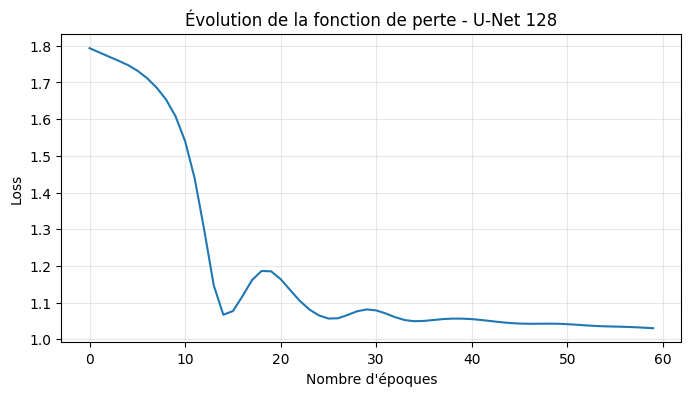

In [18]:


# Reproductibilité
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Nouvelle initialisation du modèle
modele_128 = SmallUNet().to(device)

# Données d'entraînement
X = X_train_128.to(device)
Y = Y_train_128.to(device)

# Fonction de perte BCE + Dice
def fonction_perte(prediction, cible):

    bce = F.binary_cross_entropy_with_logits(
        prediction, cible
    )

    proba = torch.sigmoid(prediction)

    intersection = (proba * cible).sum(dim=(1, 2, 3))
    total = proba.sum(dim=(1, 2, 3)) + cible.sum(dim=(1, 2, 3))

    dice_loss = 1 - ((2 * intersection + 1) / (total + 1)).mean()

    return bce + dice_loss


# Optimiseur
optimiseur = torch.optim.Adam(
    modele_128.parameters(),
    lr=0.001
)

# Entraînement
nb_epochs = 60
historique_loss_128 = []

modele_128.train()

for epoch in range(nb_epochs):

    optimiseur.zero_grad()

    prediction = modele_128(X)

    loss = fonction_perte(prediction, Y)

    loss.backward()
    optimiseur.step()

    historique_loss_128.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{nb_epochs} "
            f"- Loss : {loss.item():.4f}"
        )


# Visualisation de la perte
plt.figure(figsize=(8, 4))
plt.plot(historique_loss_128)
plt.xlabel("Nombre d'époques")
plt.ylabel("Loss")
plt.title("Évolution de la fonction de perte - U-Net 128")
plt.grid(alpha=0.3)
plt.show()

Nous avons entraîné notre modèle U-Net pendant 60 époques avec l'optimiseur Adam et une fonction de perte qui combine BCE et Dice Loss.

D'après le graphique, on remarque que la Loss diminue globalement, en passant d'environ **1,79 au début à 1,03 à la fin de l'entraînement**. La diminution est assez rapide pendant les 15 premières époques. Ensuite, on observe une petite remontée vers l'époque 18, suivie de quelques variations.

À partir de l'époque 35, la Loss commence à se stabiliser autour de 1,05, puis diminue légèrement jusqu'à 1,03.

Ces résultats montrent que le modèle apprend progressivement sur les images d'entraînement. Cependant, comme nous avons utilisé seulement trois images pour l'entraînement, cela reste insuffisant pour garantir de bons résultats sur une nouvelle image.

Il faudra donc regarder le score Dice sur l'image de test pour savoir si le modèle arrive réellement à bien segmenter le corps calleux.

### Prédiction et évaluation du U-Net :

Dice U-Net 128x128 : 0.0000


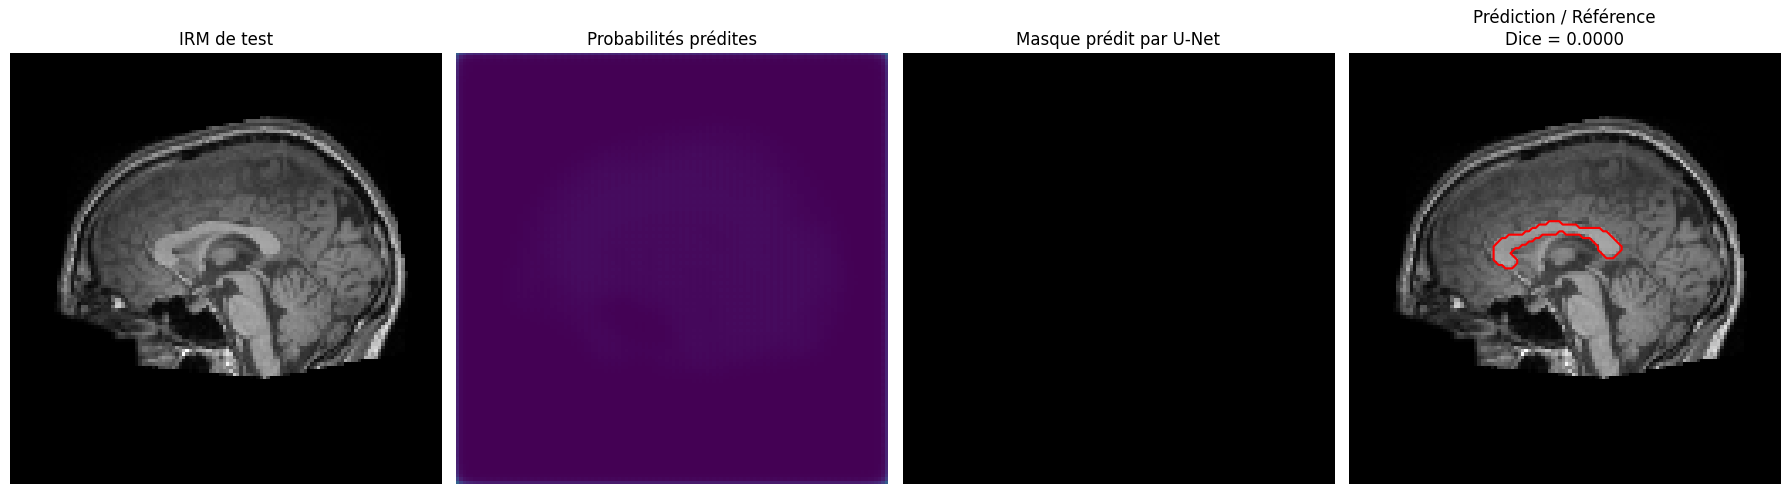

In [19]:

# 1. Passer le modèle en mode évaluation
modele_128.eval()

# 2. Prédiction sur l'image de test
with torch.no_grad():

    X = X_test_128.to(device)

    # Sortie brute du réseau
    logits = modele_128(X)

    # Conversion en probabilités entre 0 et 1
    probabilites = torch.sigmoid(logits)

    # Seuillage pour obtenir un masque binaire
    prediction = probabilites > 0.5

# 3. Conversion en tableaux NumPy
image_test = X_test_128[0, 0].cpu().numpy()
masque_reference = Y_test_128[0, 0].cpu().numpy() > 0.5
masque_prediction = prediction[0, 0].cpu().numpy()
carte_proba = probabilites[0, 0].cpu().numpy()

# 4. Calcul du Dice
dice_unet_128 = calcul_dice(
    masque_prediction,
    masque_reference
)

print(f"Dice U-Net 128x128 : {dice_unet_128:.4f}")

# 5. Affichage des résultats
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image_test, cmap="gray")
axes[0].set_title("IRM de test")

axes[1].imshow(carte_proba, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Probabilités prédites")

axes[2].imshow(masque_prediction, cmap="gray")
axes[2].set_title("Masque prédit par U-Net")

axes[3].imshow(image_test, cmap="gray")
axes[3].contour(
    masque_reference,
    levels=[0.5],
    colors="red"
)
axes[3].contour(
    masque_prediction,
    levels=[0.5],
    colors="lime"
)
axes[3].set_title(
    f"Prédiction / Référence\nDice = {dice_unet_128:.4f}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Malgré la diminution de la Loss pendant l'entraînement, le U-Net obtient un **Dice de 0** sur l'image de test.

Visuellement, le masque prédit est entièrement noir : le réseau ne détecte aucun pixel du corps calleux avec un seuil de 0,5.

Ce résultat peut s'expliquer par le très faible nombre d'images d'entraînement (3), le déséquilibre entre le corps calleux et le fond, ainsi que la perte de détails liée au redimensionnement.

**Nous constatons donc qu'une Loss décroissante ne garantit pas une bonne segmentation sur une image non utilisée pendant l'entraînement.**

### Entraînement du U-Net (256 × 256) :

Epoch 10/60 - Loss : 1.6053
Epoch 20/60 - Loss : 1.1825
Epoch 30/60 - Loss : 1.0768
Epoch 40/60 - Loss : 1.0516
Epoch 50/60 - Loss : 1.0360
Epoch 60/60 - Loss : 1.0233


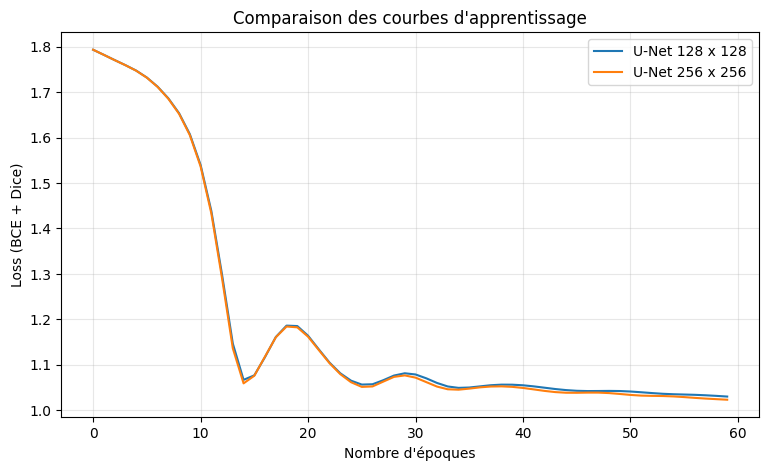

In [20]:

# 1. Reproductibilité
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 2. Initialisation d'un nouveau modèle
modele_256 = SmallUNet().to(device)

# 3. Données d'entraînement en 256 x 256
X = X_train_256.to(device)
Y = Y_train_256.to(device)

# 4. Optimiseur identique au modèle 128
optimiseur_256 = torch.optim.Adam(
    modele_256.parameters(),
    lr=0.001
)

# 5. Entraînement
nb_epochs = 60
historique_loss_256 = []

modele_256.train()

for epoch in range(nb_epochs):

    optimiseur_256.zero_grad()

    prediction = modele_256(X)

    # Même fonction de perte : BCE + Dice Loss
    loss = fonction_perte(prediction, Y)

    loss.backward()
    optimiseur_256.step()

    historique_loss_256.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{nb_epochs} "
            f"- Loss : {loss.item():.4f}"
        )

# 6. Comparaison des courbes d'apprentissage
plt.figure(figsize=(9, 5))

plt.plot(historique_loss_128, label="U-Net 128 x 128")
plt.plot(historique_loss_256, label="U-Net 256 x 256")

plt.xlabel("Nombre d'époques")
plt.ylabel("Loss (BCE + Dice)")
plt.title("Comparaison des courbes d'apprentissage")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Évaluation du U-Net (256 × 256) :

Dice U-Net 128 x 128 : 0.0000
Dice U-Net 256 x 256 : 0.0000
Probabilités min / max / moyenne : 0.0020 0.3782 0.0190


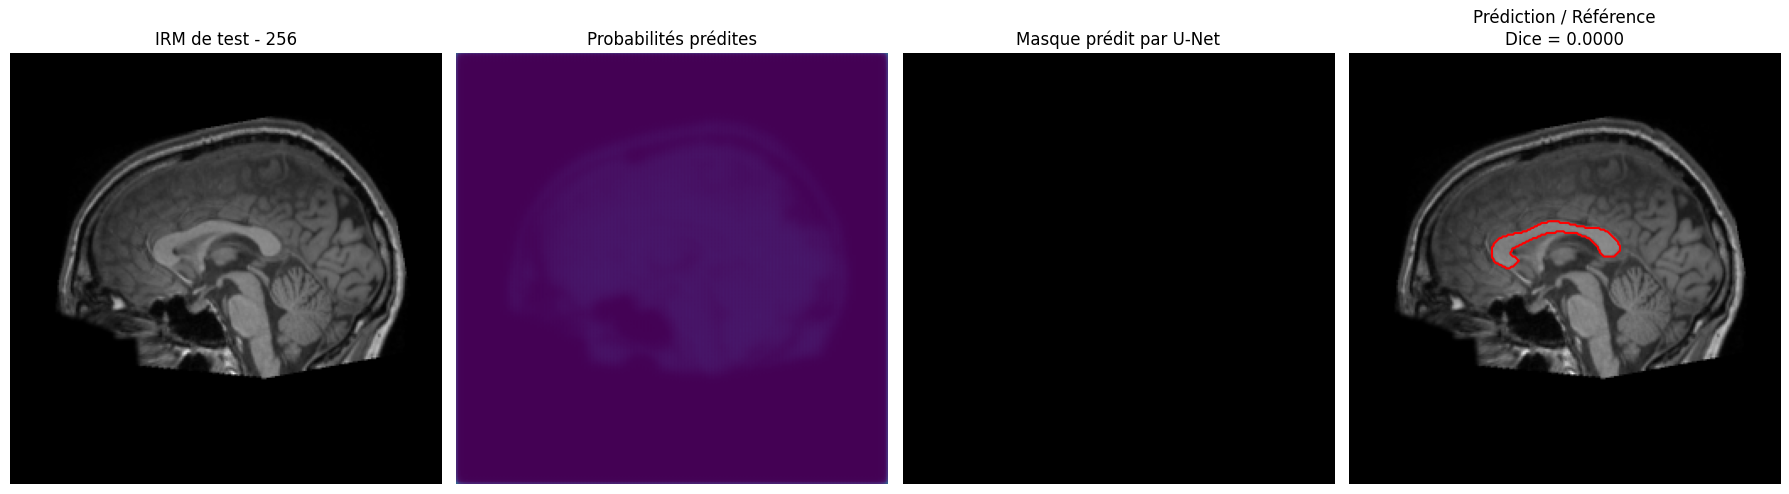

In [21]:

# 1. Mode évaluation
modele_256.eval()

# 2. Prédiction sur l'image de test
with torch.no_grad():

    X = X_test_256.to(device)

    logits = modele_256(X)

    probabilites_256 = torch.sigmoid(logits)

    prediction_256 = probabilites_256 > 0.5

# 3. Conversion en NumPy
image_test_256 = X_test_256[0, 0].cpu().numpy()

masque_reference_256 = (
    Y_test_256[0, 0].cpu().numpy() > 0.5
)

masque_prediction_256 = (
    prediction_256[0, 0].cpu().numpy()
)

carte_proba_256 = (
    probabilites_256[0, 0].cpu().numpy()
)

# 4. Calcul du Dice à la résolution 256
dice_unet_256 = calcul_dice(
    masque_prediction_256,
    masque_reference_256
)

print(f"Dice U-Net 128 x 128 : {dice_unet_128:.4f}")
print(f"Dice U-Net 256 x 256 : {dice_unet_256:.4f}")

print(
    "Probabilités min / max / moyenne :",
    f"{carte_proba_256.min():.4f}",
    f"{carte_proba_256.max():.4f}",
    f"{carte_proba_256.mean():.4f}"
)

# 5. Visualisation
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image_test_256, cmap="gray")
axes[0].set_title("IRM de test - 256")

axes[1].imshow(
    carte_proba_256,
    cmap="viridis",
    vmin=0,
    vmax=1
)
axes[1].set_title("Probabilités prédites")

axes[2].imshow(masque_prediction_256, cmap="gray")
axes[2].set_title("Masque prédit par U-Net")

axes[3].imshow(image_test_256, cmap="gray")

axes[3].contour(
    masque_reference_256,
    levels=[0.5],
    colors="red"
)

# Affichage du contour prédit uniquement s'il existe
if masque_prediction_256.any():
    axes[3].contour(
        masque_prediction_256,
        levels=[0.5],
        colors="lime"
    )

axes[3].set_title(
    f"Prédiction / Référence\nDice = {dice_unet_256:.4f}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Les deux modèles présentent une diminution de la Loss pendant l'entraînement. Cependant, ils obtiennent tous les deux un **Dice de 0** sur l'image de test, avec des masques entièrement noirs.

**Conclusion :** Augmenter la résolution n'a pas amélioré la segmentation. Ces résultats peuvent s'expliquer par le faible nombre d'images et le déséquilibre des classes. Une Loss décroissante ne garantit donc pas une bonne segmentation sur une nouvelle image.

## **Bilan 01 :**


Nous avons testé plusieurs méthodes pour segmenter le corps calleux : seuillage manuel, Otsu, Snake classique, contours actifs géodésiques, Frangi et U-Net.

**Observations :** Le Snake classique (Dice = 0,3887) et les contours actifs géodésiques (Dice = 0,3866) donnent les meilleurs résultats, suivis du seuillage manuel (0,3791). Otsu et Frangi obtiennent des scores très faibles, tandis que les deux U-Net ne détectent pas le corps calleux sur l'image de test.

**Conclusion :** Les méthodes utilisant les contours semblent plus adaptées à cette structure dans nos expériences. Cependant, les segmentations restent imparfaites et le Dice seul ne reflète pas toutes les erreurs anatomiques.

**Prochaine étape :** Nous allons compléter cette comparaison avec la précision, le rappel et la distance de Hausdorff pour mieux comprendre les différences entre les méthodes avant de passer au dataset cardiaque.

### évaluation comparative des méthodes sur l'IRM cérébral :

#### Comparaison des méthodes :

In [22]:
# =====================================================
# EXPÉRIENCE 7 : COMPARAISON DES MÉTRIQUES
# Dataset : IRM cérébrale
# =====================================================

import numpy as np
import pandas as pd
from scipy.ndimage import binary_erosion, distance_transform_edt
from skimage.transform import resize

# 1. Masque de référence
reference = maskCC.astype(bool)

# 2. Fonction de redimensionnement pour les U-Net
def remettre_taille_originale(masque):
    return resize(
        masque.astype(float),
        reference.shape,
        order=0,
        preserve_range=True,
        anti_aliasing=False
    ) > 0.5


# 3. Métriques d'évaluation
def calcul_metriques(prediction, reference):

    P = prediction.astype(bool)
    R = reference.astype(bool)

    VP = np.logical_and(P, R).sum()
    FP = np.logical_and(P, ~R).sum()
    FN = np.logical_and(~P, R).sum()

    # Dice
    dice = 2 * VP / (2 * VP + FP + FN) if (2 * VP + FP + FN) > 0 else 1.0

    # Précision
    precision = VP / (VP + FP) if (VP + FP) > 0 else 0.0

    # Rappel
    rappel = VP / (VP + FN) if (VP + FN) > 0 else 0.0

    # Distance de Hausdorff sur les contours
    if not P.any() or not R.any():
        hausdorff = np.nan
    else:
        contour_P = P & ~binary_erosion(P)
        contour_R = R & ~binary_erosion(R)

        dist_R = distance_transform_edt(~contour_R)
        dist_P = distance_transform_edt(~contour_P)

        hausdorff = max(
            dist_R[contour_P].max(),
            dist_P[contour_R].max()
        )

    return dice, precision, rappel, hausdorff


# 4. Récupération des différentes segmentations
methodes = {
    "Seuillage manuel T=110": imG > 110,
    "Otsu": masque_otsu,
    "Snake classique beta=0.1": masque_beta2,
    "Contour géodésique": masque_gac,
    "Frangi percentile 90": masque_90,
    "U-Net 128": remettre_taille_originale(masque_prediction),
    "U-Net 256": remettre_taille_originale(masque_prediction_256)
}

# 5. Calcul des métriques
resultats_evaluation = []

for nom, masque in methodes.items():

    dice, precision, rappel, hd = calcul_metriques(
        masque, reference
    )

    resultats_evaluation.append({
        "Méthode": nom,
        "Dice": dice,
        "Précision": precision,
        "Rappel": rappel,
        "Hausdorff (pixels)": hd
    })

# 6. Tableau comparatif
df = pd.DataFrame(resultats_evaluation)

print("COMPARAISON DES MÉTHODES - IRM CÉRÉBRALE")
display(df.round(4))

COMPARAISON DES MÉTHODES - IRM CÉRÉBRALE


,Méthode,Dice,Précision,Rappel,Hausdorff (pixels)
0,Seuillage manuel T=110,0.3791,0.2421,0.8731,169.7999
1,Otsu,0.0643,0.0332,1.0000,171.8400
2,Snake classique beta=0.1,0.3887,0.2873,0.6007,50.3587
3,Contour géodésique,0.3866,0.2779,0.6351,52.3450
4,Frangi percentile 90,0.0435,0.0278,0.0993,172.5399
5,U-Net 128,0.0000,0.0000,0.0000,NaN
6,U-Net 256,0.0000,0.0000,0.0000,NaN



Avec ces résultats, on remarque que **le Dice seul ne suffit pas pour évaluer une segmentation**.

Le seuillage manuel détecte une grande partie du corps calleux (rappel = 0,8731), mais il sélectionne aussi beaucoup d'autres régions, ce qui explique sa faible précision (0,2421).

Le Snake obtient un meilleur Dice (0,3887) et une distance de Hausdorff plus faible (50,36 pixels). Par contre, son rappel de 0,6007 montre qu'il manque certaines parties du corps calleux.

**On peut donc en déduire que le Snake donne globalement de meilleurs résultats dans nos tests, mais qu'aucune méthode ne segmente parfaitement le corps calleux.** Cela montre aussi pourquoi il est important de comparer plusieurs métriques et pas seulement le Dice.

# MRI heart

The last section is about MRI sequences of the heart. Your goal is to segment the left ventricule. Be careful, the segmentation is not a maks but a series of points (landmarks). To obtain a binary mask, you should first interpolate the points (using for instance a spline).


In [23]:
MRIheart_path = Working_directory + 'MRIheart/'


In [24]:
data=loadmat(MRIheart_path + 'dataMRIheart.mat')
data=data['data']
seg=loadmat(MRIheart_path + 'segMRIheart.mat')
seg=seg['seg']

print('MRI volume of the heart composed of', data.shape[2], 'slices along the z axis and', data.shape[3],
'temporal frames. Each slice is an image ', data.shape[0], ' x ',  data.shape[1])
print('For each slice and at each time frame we have a manual segmentation composed of',seg[4,4].shape[0] , '2D landmarks')

print('Be careful, some slices do not have the left ventricle and the manual segmentation is not simply empty but it contains the value:', seg[0,0] )

MRI volume of the heart composed of 11 slices along the z axis and 20 temporal frames. Each slice is an image  256  x  256
For each slice and at each time frame we have a manual segmentation composed of 65 2D landmarks
Be careful, some slices do not have the left ventricle and the manual segmentation is not simply empty but it contains the value: [[-99999]]


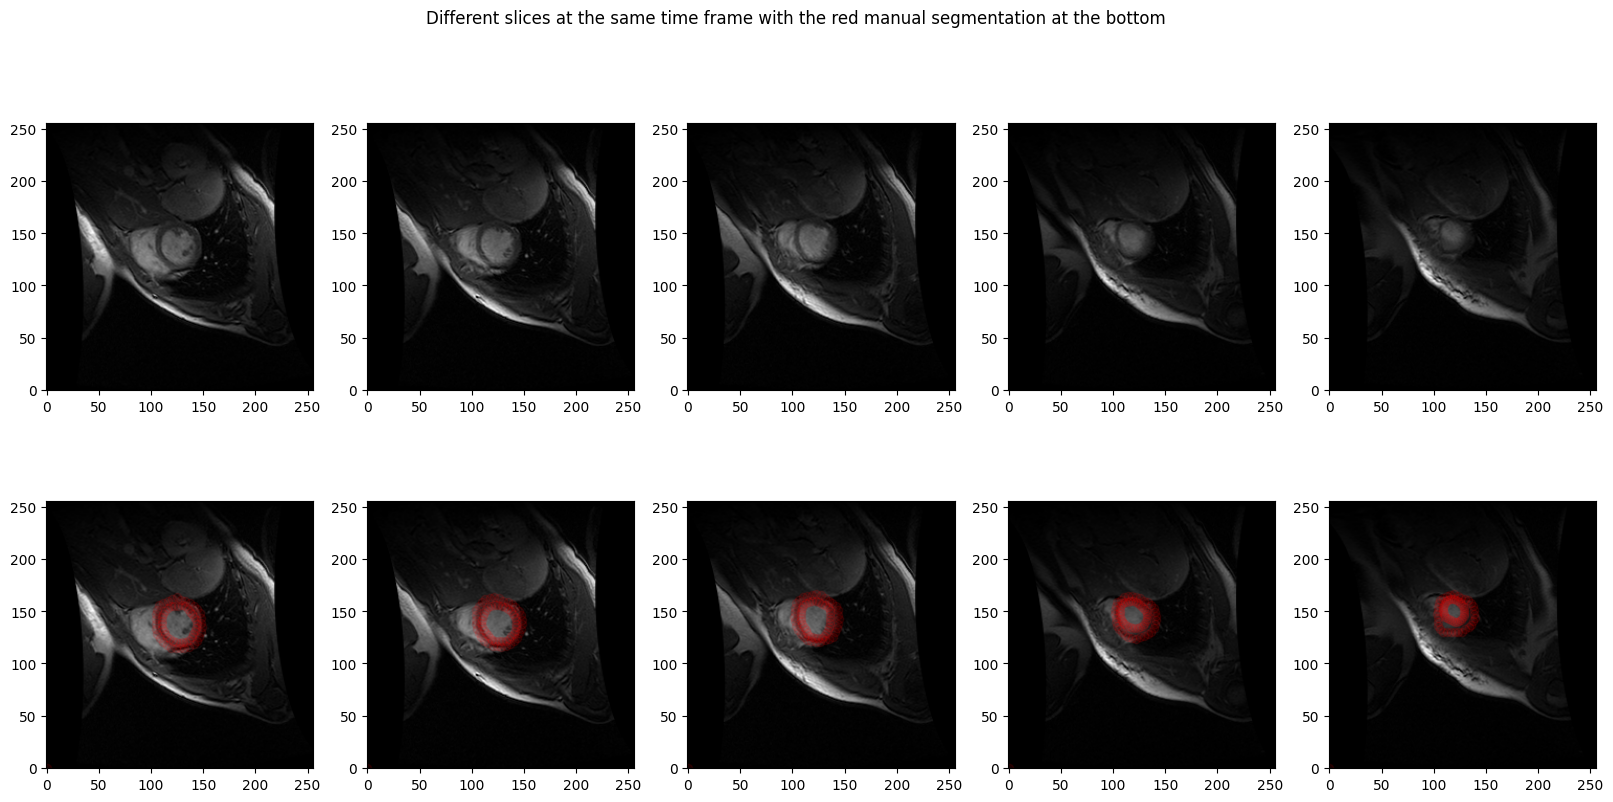

In [25]:
plt.figure(figsize=(20, 9))
plt.suptitle('Different slices at the same time frame with the red manual segmentation at the bottom')
plt.subplot(2, 5, 1)
plt.imshow(data[:,:,4,1],cmap="gray")
plt.gca().invert_yaxis()

plt.subplot(2, 5, 2)
plt.imshow(data[:,:,5,1],cmap="gray")
plt.gca().invert_yaxis()

plt.subplot(2, 5, 3)
plt.imshow(data[:,:,6,1],cmap="gray")
plt.gca().invert_yaxis()

plt.subplot(2, 5, 4)
plt.imshow(data[:,:,7,1],cmap="gray")
plt.gca().invert_yaxis()

plt.subplot(2, 5, 5)
plt.imshow(data[:,:,8,1],cmap="gray")
plt.gca().invert_yaxis()

plt.subplot(2, 5, 6)
plt.imshow(data[:,:,4,1],cmap="gray")
plt.gca().invert_yaxis()
plt.scatter(seg[4,1][:,0], seg[4,1][:,1], c='r',alpha=0.1)

plt.subplot(2, 5, 7)
plt.imshow(data[:,:,5,1],cmap="gray")
plt.gca().invert_yaxis()
plt.scatter(seg[5,1][:,0], seg[5,1][:,1], c='r',alpha=0.1)

plt.subplot(2, 5, 8)
plt.imshow(data[:,:,6,1],cmap="gray")
plt.gca().invert_yaxis()
plt.scatter(seg[6,1][:,0], seg[6,1][:,1], c='r',alpha=0.1)

plt.subplot(2, 5, 9)
plt.imshow(data[:,:,7,1],cmap="gray")
plt.gca().invert_yaxis()
plt.scatter(seg[7,1][:,0], seg[7,1][:,1], c='r',alpha=0.1)

plt.subplot(2, 5, 10)
plt.imshow(data[:,:,8,1],cmap="gray")
plt.gca().invert_yaxis()
plt.scatter(seg[8,1][:,0], seg[8,1][:,1], c='r',alpha=0.1)

##**Construire le masque de référence du ventricule gauche :**

Avant de tester le seuillage, Otsu ou les Snakes, nous devons transformer les points d'annotation en un masque binaire.

Sur l'image ci-haut, on voit que les points rouges dessinent approximativement un anneau autour du ventricule. Nous allons utiliser une interpolation par spline pour relier ces points.

Dans un premier temps il est important de savoir si les points correspondent à un seul contour ou à deux contours distincts, par exemple le contour interne et externe du myocarde.

Cela déterminera comment construire correctement notre masque de référence.

Dimensions de l'image : (256, 256)
Dimensions des annotations : (65, 2)
Nombre de points : 65
Premiers points :
[[124.07803815 120.0887356 ]
 [120.8748656  121.38949116]
 [117.83726989 123.01073047]
 [114.87632694 124.80072933]
 [113.1590491  127.65290147]]


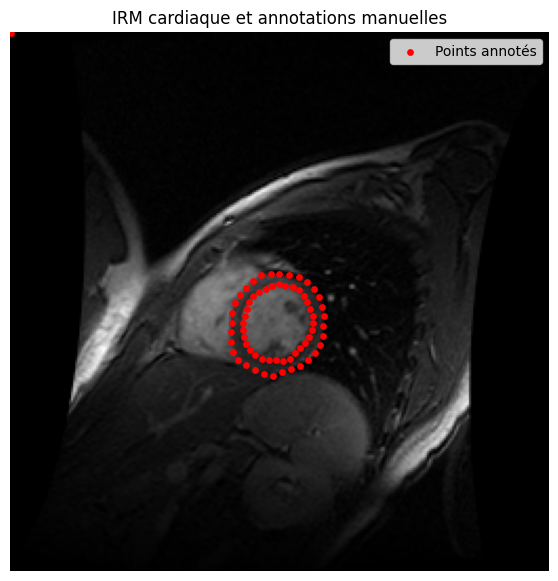

In [26]:
# =====================================================
# EXPÉRIENCE 1 : EXPLORATION DES ANNOTATIONS CARDIAQUES
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

# Choix d'une coupe et d'un instant
z = 4
t = 1

# Récupération de l'image et de ses annotations
image_coeur = data[:, :, z, t]
points = np.asarray(seg[z, t])

print("Dimensions de l'image :", image_coeur.shape)
print("Dimensions des annotations :", points.shape)
print("Nombre de points :", len(points))
print("Premiers points :")
print(points[:5])

# Visualisation
plt.figure(figsize=(7, 7))

plt.imshow(image_coeur, cmap="gray")

plt.scatter(
    points[:, 0],
    points[:, 1],
    c="red",
    s=15,
    label="Points annotés"
)

plt.title("IRM cardiaque et annotations manuelles")
plt.legend()
plt.axis("off")
plt.show()

On remarque la présence d'un points rouge en haut a gauche de cette image, ce dernier est isolé donc il faudra bien vérifier s'il correspond à une valeur particulière dans les annotations.

Pour répondre a la question il faut comprendre l'organisation de ces 65 points!

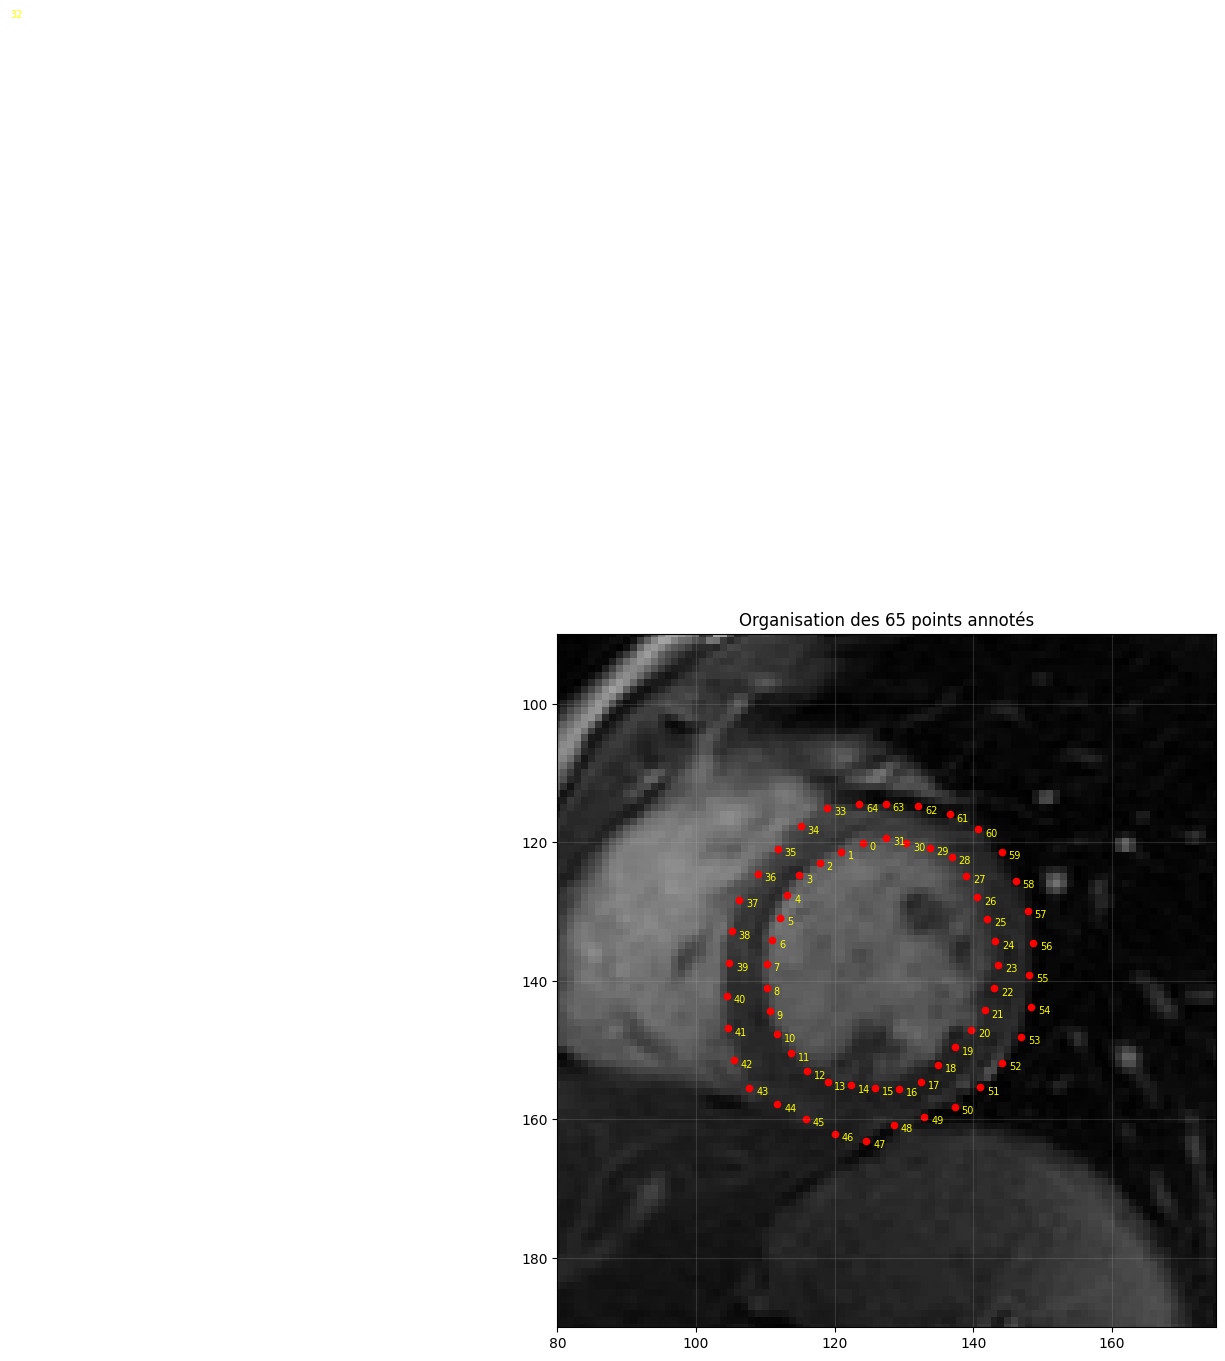

Points proches de l'origine :
[32]

Plus grandes distances entre points consécutifs :
Points 31 → 32 : 174.64 pixels
Points 32 → 33 : 165.44 pixels
Points 39 → 40 : 4.70 pixels
Points 61 → 62 : 4.69 pixels
Points 41 → 42 : 4.68 pixels


In [27]:
# =====================================================
# EXPÉRIENCE 2 : ORGANISATION DES POINTS D'ANNOTATION
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

# Visualisation des points avec leurs indices
plt.figure(figsize=(9, 9))
plt.imshow(image_coeur, cmap="gray")

plt.scatter(points[:, 0], points[:, 1],
            c="red", s=20)

for i, (x, y) in enumerate(points):
    plt.text(x + 1, y + 1, str(i),
             fontsize=7, color="yellow")

plt.title("Organisation des 65 points annotés")
plt.xlim(80, 175)
plt.ylim(190, 90)
plt.grid(alpha=0.2)
plt.show()

# Recherche de points particuliers
print("Points proches de l'origine :")
print(np.where(np.all(np.isclose(points, 0), axis=1))[0])

# Distances entre deux points consécutifs
distances = np.linalg.norm(
    np.diff(points, axis=0), axis=1
)

print("\nPlus grandes distances entre points consécutifs :")

for i in np.argsort(distances)[-5:][::-1]:
    print(f"Points {i} → {i+1} : {distances[i]:.2f} pixels")

Nous avons affiché les 65 points avec leurs indices pour comprendre leur organisation. On observe que les points 0 à 31 forment le contour intérieur du ventricule gauche

Le point 32 semble être un point particulier. Il peut correspondre à une erreur ou à un point ajouté pour séparer les deux contours. Nous avons donc choisi de l’exclure lors de l’interpolation.

Nous allons donc interpoler séparément les deux contours à l'aide de splines pour construire les masques binaires de référence, nécessaires à l'évaluation de nos futures segmentations.

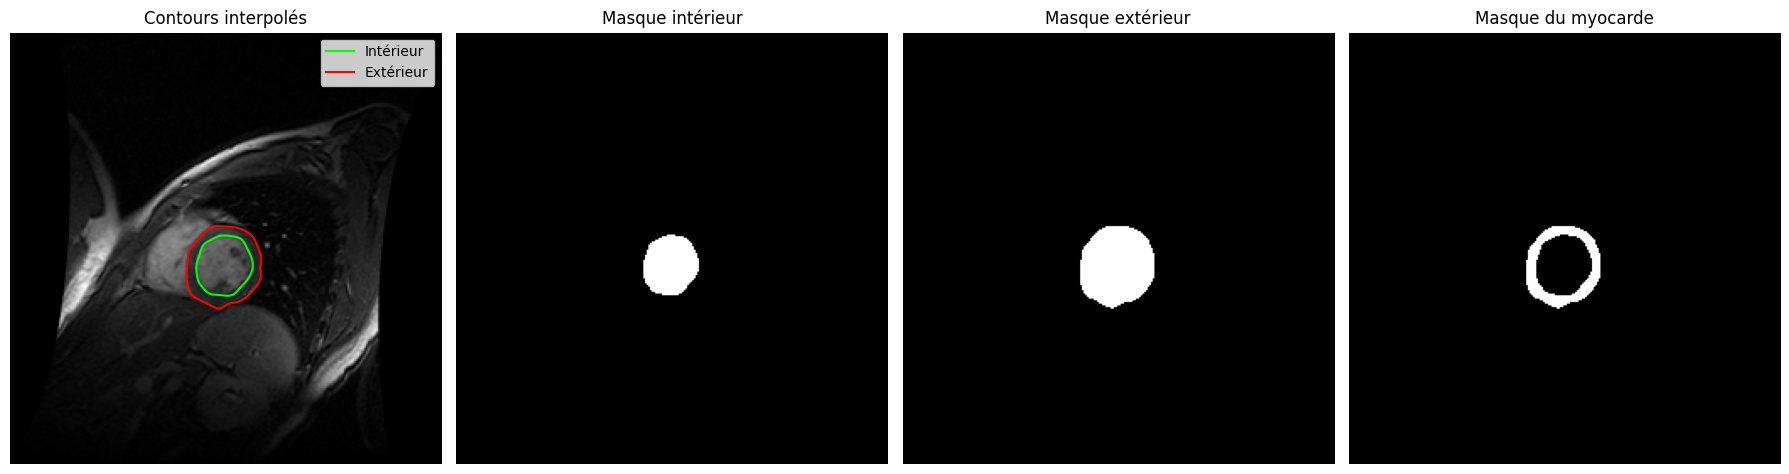

Pixels du masque intérieur : 942
Pixels du masque extérieur : 1712
Pixels du myocarde : 770


In [28]:

from scipy.interpolate import splprep, splev
from skimage.draw import polygon2mask

# 1. Séparation des deux contours
points_interieurs = points[:32]
points_exterieurs = points[33:65]

# Le point 32 est volontairement exclu

# 2. Fonction d'interpolation par spline fermée
def interpolation_spline(pts, nb_points=300):

    x = pts[:, 0]
    y = pts[:, 1]

    # Spline périodique pour obtenir un contour fermé
    tck, u = splprep([x, y], s=0, per=True)

    # Création de 300 points interpolés
    u_nouveau = np.linspace(0, 1, nb_points, endpoint=False)

    x_interp, y_interp = splev(u_nouveau, tck)

    return np.column_stack((x_interp, y_interp))


# 3. Interpolation des contours
contour_interieur = interpolation_spline(points_interieurs)
contour_exterieur = interpolation_spline(points_exterieurs)

# 4. Création des masques binaires
# polygon2mask utilise les coordonnées (ligne, colonne)

masque_interieur = polygon2mask(
    image_coeur.shape,
    contour_interieur[:, [1, 0]]
)

masque_exterieur = polygon2mask(
    image_coeur.shape,
    contour_exterieur[:, [1, 0]]
)

# 5. Masque du myocarde (région entre les deux contours)
masque_myocarde = masque_exterieur & ~masque_interieur

# 6. Visualisation
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image_coeur, cmap="gray")
axes[0].plot(
    contour_interieur[:, 0],
    contour_interieur[:, 1],
    "lime",
    label="Intérieur"
)
axes[0].plot(
    contour_exterieur[:, 0],
    contour_exterieur[:, 1],
    "red",
    label="Extérieur"
)
axes[0].set_title("Contours interpolés")
axes[0].legend()

axes[1].imshow(masque_interieur, cmap="gray")
axes[1].set_title("Masque intérieur")

axes[2].imshow(masque_exterieur, cmap="gray")
axes[2].set_title("Masque extérieur")

axes[3].imshow(masque_myocarde, cmap="gray")
axes[3].set_title("Masque du myocarde")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Pixels du masque intérieur :", masque_interieur.sum())
print("Pixels du masque extérieur :", masque_exterieur.sum())
print("Pixels du myocarde :", masque_myocarde.sum())

Nous avons utilisé des **splines fermées** pour relier les points annotés et obtenir deux contours réguliers, en excluant le point 32.

Les résultats montrent que les contours interpolés suivent bien les annotations du ventricule gauche. Nous avons ensuite créé trois masques binaires : le masque intérieur (**942 pixels**), le masque extérieur (**1712 pixels**) et celui du myocarde (**770 pixels**), obtenu par la différence entre les deux masques.

**Conclusion :** L'interpolation nous a permis de transformer les annotations en masques binaires, que nous pourrons maintenant utiliser comme références pour évaluer nos méthodes de segmentation.

## Seuillage manuel du ventricule gauche :

Type : uint16
Intensité minimale : 0
Intensité maximale : 1013


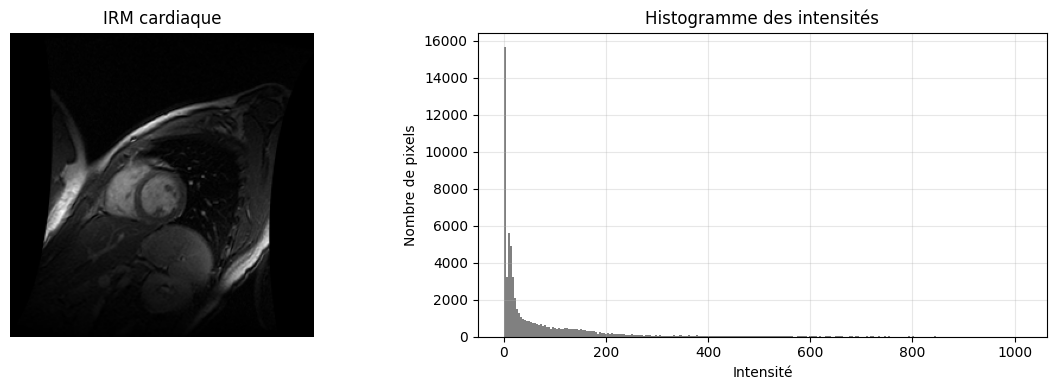

In [29]:
# =====================================================
# EXPÉRIENCE 4 : SEUILLAGE MANUEL - IRM CARDIAQUE
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

# 1. Vérification des intensités
print("Type :", image_coeur.dtype)
print("Intensité minimale :", image_coeur.min())
print("Intensité maximale :", image_coeur.max())

# 2. Histogramme de l'image
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_coeur, cmap="gray")
plt.title("IRM cardiaque")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.hist(image_coeur.ravel(), bins=256, color="gray")
plt.title("Histogramme des intensités")
plt.xlabel("Intensité")
plt.ylabel("Nombre de pixels")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Expérience 4 — Analyse de l'IRM cardiaque

Nous avons affiché l'IRM cardiaque et son histogramme pour analyser la distribution des intensités avant d'appliquer le seuillage manuel.
On remarque un **pic important près de 0**, correspondant principalement au fond sombre de l'image. Les intensités vont de **0 à 1013**, mais la majorité des pixels possède une intensité relativement faible.

Nous allons donc tester trois seuils (**50, 150 et 300**), choisis de manière exploratoire, pour voir lequel permet de mieux isoler la cavité du ventricule gauche.

## **Seuillage manuel de l'IRM cardiaque**

Seuil T = 50 : Dice = 0.0768
Seuil T = 150 : Dice = 0.1629
Seuil T = 300 : Dice = 0.2610


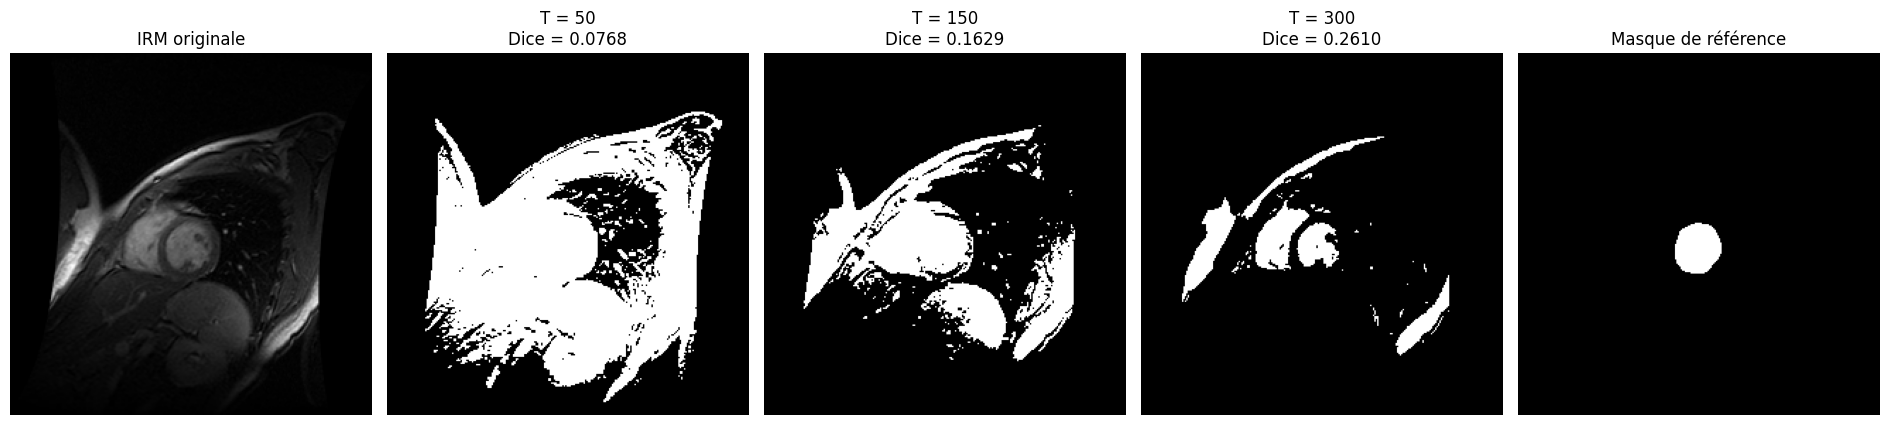

In [30]:

seuils = [50, 150, 300]

# 2. Masque de référence : cavité du ventricule gauche
reference_coeur = masque_interieur.astype(bool)

# 3. Visualisation des résultats
fig, axes = plt.subplots(1, 5, figsize=(19, 5))

axes[0].imshow(image_coeur, cmap="gray")
axes[0].set_title("IRM originale")

for i, seuil in enumerate(seuils):

    # Application du seuillage
    masque = image_coeur > seuil

    # Calcul du Dice
    dice = calcul_dice(masque, reference_coeur)

    # Affichage
    axes[i + 1].imshow(masque, cmap="gray")
    axes[i + 1].set_title(
        f"T = {seuil}\nDice = {dice:.4f}"
    )

    print(f"Seuil T = {seuil} : Dice = {dice:.4f}")

# 4. Masque de référence
axes[4].imshow(reference_coeur, cmap="gray")
axes[4].set_title("Masque de référence")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Avec T = 50, une grande partie de l'image est sélectionnée (Dice = 0,0768). En augmentant le seuil à 150 puis à 300, moins de régions sont détectées et le Dice augmente progressivement (0,1629 puis 0,2610).

Conclusion : Le seuil T = 300 donne le meilleur résultat parmi ceux testés. Cependant, d'autres structures restent détectées et une partie du ventricule n'est pas conservée. Le seuillage manuel seul reste donc insuffisant pour obtenir une segmentation précise.

## **Seuillage automatique d'Otsu**

Seuil calculé par Otsu : 228
Dice obtenu avec Otsu : 0.2389


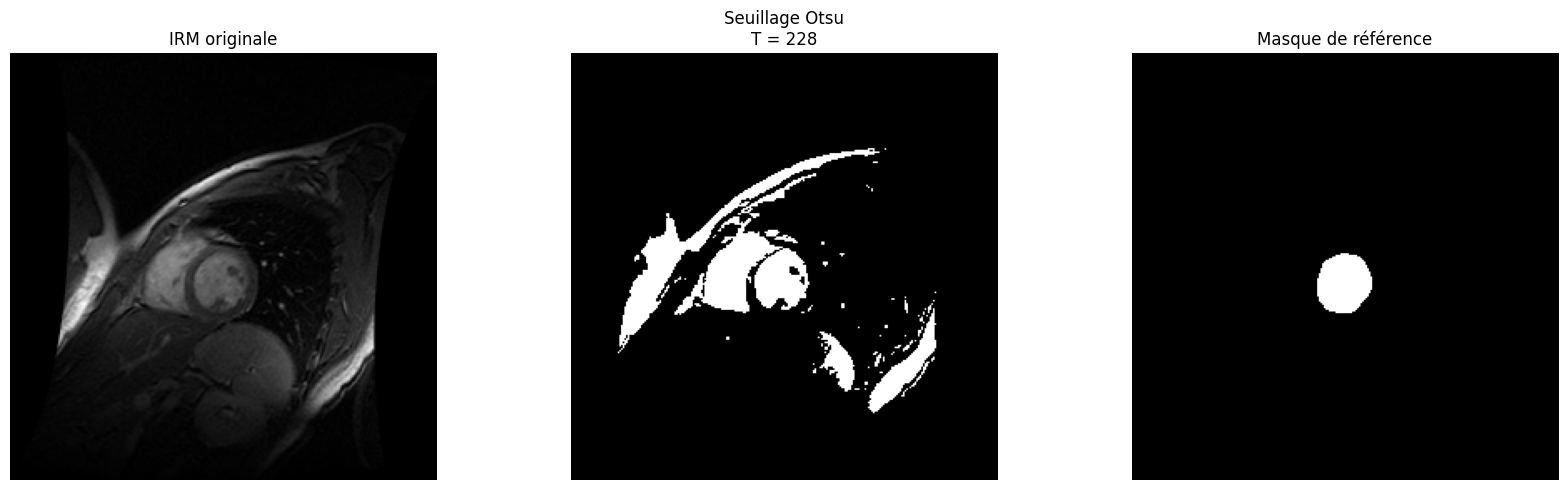

In [31]:

# 1. Calcul automatique du seuil d'Otsu
seuil_otsu_coeur = threshold_otsu(image_coeur)

# 2. Application du seuillage
masque_otsu_coeur = image_coeur > seuil_otsu_coeur

# 3. Évaluation avec le Dice
dice_otsu_coeur = calcul_dice(
    masque_otsu_coeur,
    reference_coeur
)

print(f"Seuil calculé par Otsu : {seuil_otsu_coeur}")
print(f"Dice obtenu avec Otsu : {dice_otsu_coeur:.4f}")

# 4. Visualisation des résultats
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].imshow(image_coeur, cmap="gray")
axes[0].set_title("IRM originale")

axes[1].imshow(masque_otsu_coeur, cmap="gray")
axes[1].set_title(
    f"Seuillage Otsu\nT = {seuil_otsu_coeur}"
)

axes[2].imshow(reference_coeur, cmap="gray")
axes[2].set_title("Masque de référence")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Otsu donne un résultat proche du seuillage manuel, mais il ne permet pas non plus d'isoler correctement le ventricule gauche. Cela s'explique par le fait qu'il utilise uniquement les intensités, sans tenir compte de la position ou de la forme du ventricule.

## **Les contours actifs classiques (Snake) :**

Snake beta = 1 : Dice = 0.8899
Snake beta = 0.1 : Dice = 0.8797


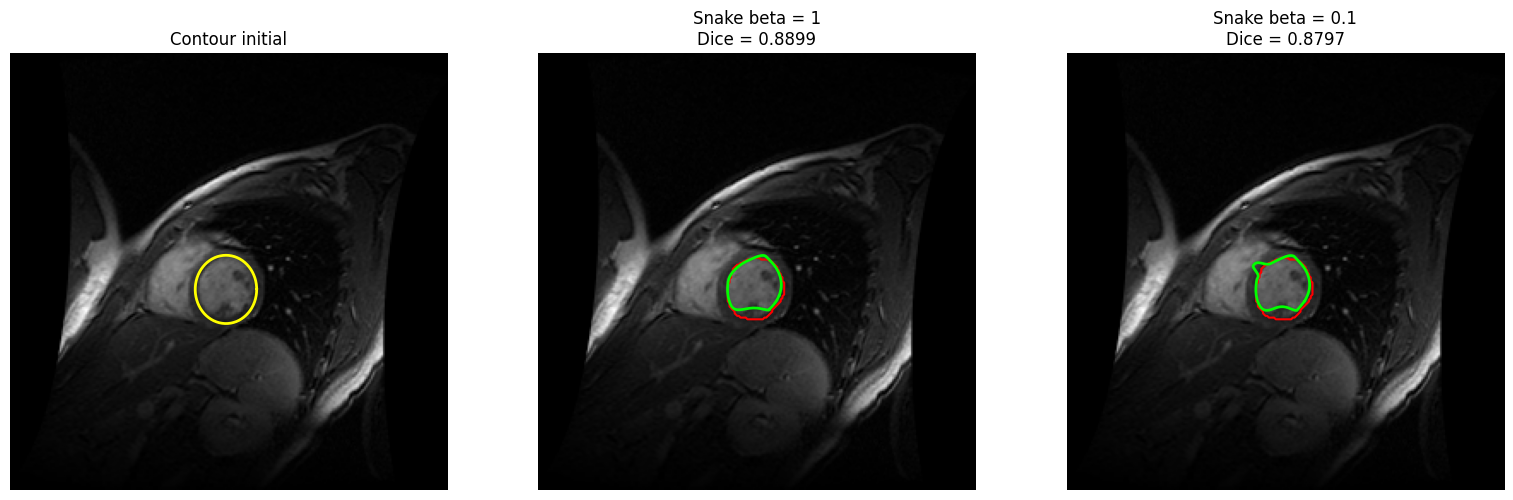

In [32]:

# 1. Normalisation et lissage de l'image
image_normalisee = image_coeur.astype(float) / image_coeur.max()
image_lissee_coeur = gaussian(image_normalisee, sigma=2)

# 2. Initialisation d'un contour circulaire
t = np.linspace(0, 2*np.pi, 200, endpoint=False)

# Coordonnées estimées visuellement sur l'IRM
centre_x, centre_y = 126, 138
rayon_x, rayon_y = 18, 20

# Format (ligne, colonne) pour scikit-image
init_coeur = np.array([
    centre_y + rayon_y * np.sin(t),
    centre_x + rayon_x * np.cos(t)
]).T

# 3. Comparaison de deux valeurs de rigidité
betas = [1, 0.1]

resultats_snake_coeur = {}

for beta in betas:

    snake = active_contour(
        image_lissee_coeur,
        init_coeur,
        alpha=0.01,
        beta=beta,
        gamma=0.01,
        w_line=0,
        w_edge=1,
        max_num_iter=1500,
        boundary_condition="periodic"
    )

    # Conversion du contour en masque binaire
    masque = polygon2mask(image_coeur.shape, snake)

    # Calcul du Dice
    dice = calcul_dice(masque, reference_coeur)

    resultats_snake_coeur[beta] = {
        "contour": snake,
        "masque": masque,
        "dice": dice
    }

    print(f"Snake beta = {beta} : Dice = {dice:.4f}")

# 4. Visualisation comparative
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Contour initial
axes[0].imshow(image_coeur, cmap="gray")
axes[0].plot(init_coeur[:, 1], init_coeur[:, 0],
             "yellow", linewidth=2)
axes[0].set_title("Contour initial")

# Résultats des deux configurations
for i, beta in enumerate(betas):

    resultat = resultats_snake_coeur[beta]

    axes[i+1].imshow(image_coeur, cmap="gray")

    # Contour de référence en rouge
    axes[i+1].contour(
        reference_coeur,
        levels=[0.5],
        colors="red"
    )

    # Contour prédit en vert
    axes[i+1].plot(
        resultat["contour"][:, 1],
        resultat["contour"][:, 0],
        color="lime",
        linewidth=2
    )

    axes[i+1].set_title(
        f"Snake beta = {beta}\nDice = {resultat['dice']:.4f}"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Les deux configurations donnent de bons résultats, avec un Dice de 0,8899 pour beta = 1 et 0,8797 pour beta = 0,1. Visuellement, les contours suivent assez bien la forme du ventricule gauche. Avec beta= 1, le contour est plus régulier et légèrement plus proche de la référence.

Conclusion : Le Snake donne de bien meilleurs résultats que le seuillage manuel (Dice = 0,2610). Contrairement au corps calleux, la forme relativement circulaire du ventricule semble mieux adaptée à cette méthode. On remarque également qu'une rigidité plus élevée donne ici un résultat légèrement meilleur.

## **Contours actifs géodésiques**

MorphGAC balloon = 0 : Dice = 0.9357
MorphGAC balloon = 1 : Dice = 0.8736


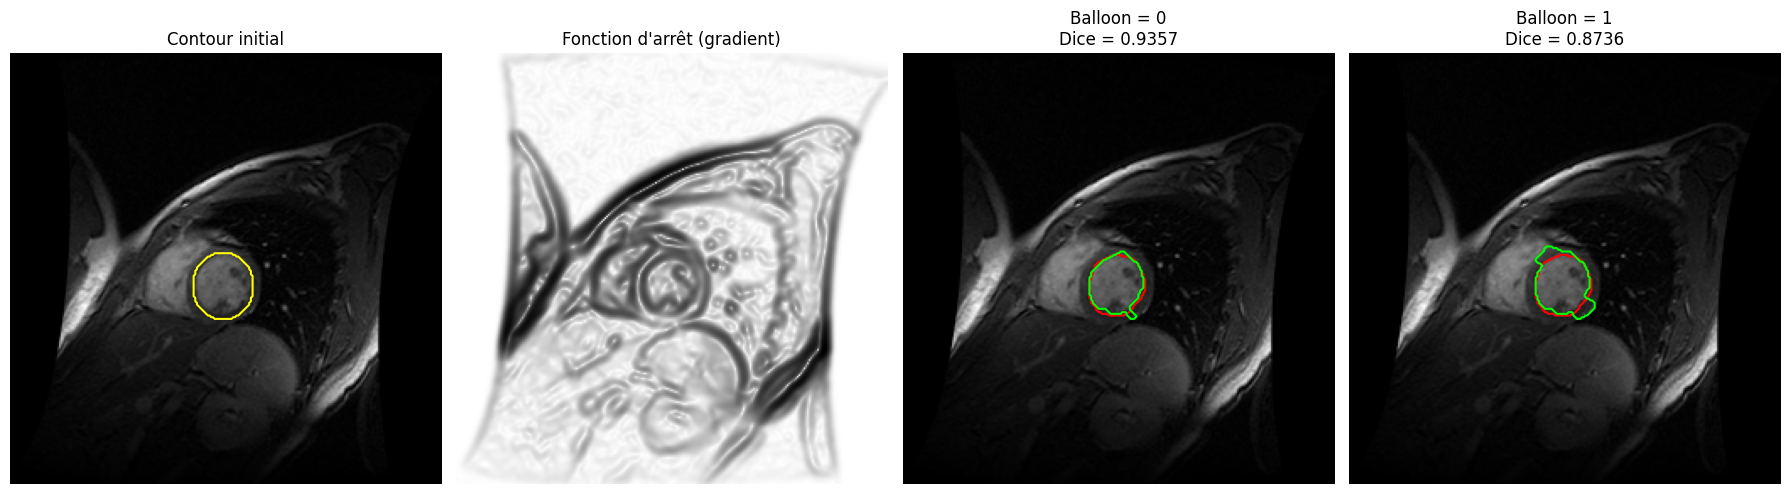

In [33]:


# 1. Normalisation de l'image
image_norm = image_coeur.astype(float) / image_coeur.max()

# 2. Calcul de la fonction d'arrêt basée sur le gradient
gimage_coeur = inverse_gaussian_gradient(
    image_norm,
    alpha=100,
    sigma=2
)

# 3. Initialisation : ellipse proche du ventricule gauche
# On reprend le même centre que pour le Snake classique
init_gac_coeur = np.zeros(image_coeur.shape, dtype=np.int8)

rr, cc = ellipse(
    138, 126, 20, 18,
    shape=image_coeur.shape
)

init_gac_coeur[rr, cc] = 1

# 4. Comparaison de deux valeurs de balloon
balloons = [0, 1]

resultats_gac_coeur = {}

for balloon in balloons:

    masque = morphological_geodesic_active_contour(
        gimage_coeur,
        num_iter=150,
        init_level_set=init_gac_coeur,
        smoothing=1,
        threshold="auto",
        balloon=balloon
    )

    # Calcul du Dice
    dice = calcul_dice(masque, reference_coeur)

    resultats_gac_coeur[balloon] = {
        "masque": masque,
        "dice": dice
    }

    print(f"MorphGAC balloon = {balloon} : Dice = {dice:.4f}")

# 5. Visualisation comparative
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Contour initial
axes[0].imshow(image_coeur, cmap="gray")
axes[0].contour(
    init_gac_coeur,
    levels=[0.5],
    colors="yellow"
)
axes[0].set_title("Contour initial")

# Fonction d'arrêt
axes[1].imshow(gimage_coeur, cmap="gray")
axes[1].set_title("Fonction d'arrêt (gradient)")

# Résultats avec les deux valeurs de balloon
for i, balloon in enumerate(balloons):

    resultat = resultats_gac_coeur[balloon]

    axes[i + 2].imshow(image_coeur, cmap="gray")

    # Référence en rouge
    axes[i + 2].contour(
        reference_coeur,
        levels=[0.5],
        colors="red"
    )

    # Prédiction en vert
    axes[i + 2].contour(
        resultat["masque"],
        levels=[0.5],
        colors="lime"
    )

    axes[i + 2].set_title(
        f"Balloon = {balloon}\nDice = {resultat['dice']:.4f}"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

 Nous avons choisi alpha = 100 pour contrôler la sensibilité aux gradients, sigma = 2 pour réduire le bruit, smoothing = 1 pour lisser le contour et num_iter = 150 pour son évolution. Le seuil de la fonction d'arrêt est calculé automatiquement (threshold = 'auto'). Ces valeurs sont choisies de manière exploratoire. Nous avons ensuite testé balloon = 0 (sans force d'expansion) et balloon = 1 (avec expansion).

Nous observant que avec balloon = 0, nous obtenons un Dice de 0,9357, supérieur au meilleur Snake classique (0,8899). Visuellement, le contour vert suit très bien la référence rouge. En revanche, avec balloon = 1, le contour s'élargit et devient légèrement plus irrégulier, ce qui diminue le Dice à 0,8736.

Dans notre expérience, MorphGAC avec balloon = 0 donne le meilleur résultat jusqu'à présent. On remarque que l'ajout d'une force d'expansion n'améliore pas forcément la segmentation, surtout lorsque le contour initial est déjà proche des frontières du ventricule.

On remarque que l'ajout d'une force d'expansion n'améliore pas forcément la segmentation, surtout lorsque le contour initial est déjà proche des frontières du ventricule.

## Filtre de Vesselness :

Frangi percentile 90 : Dice = 0.0845
Frangi percentile 95 : Dice = 0.0455


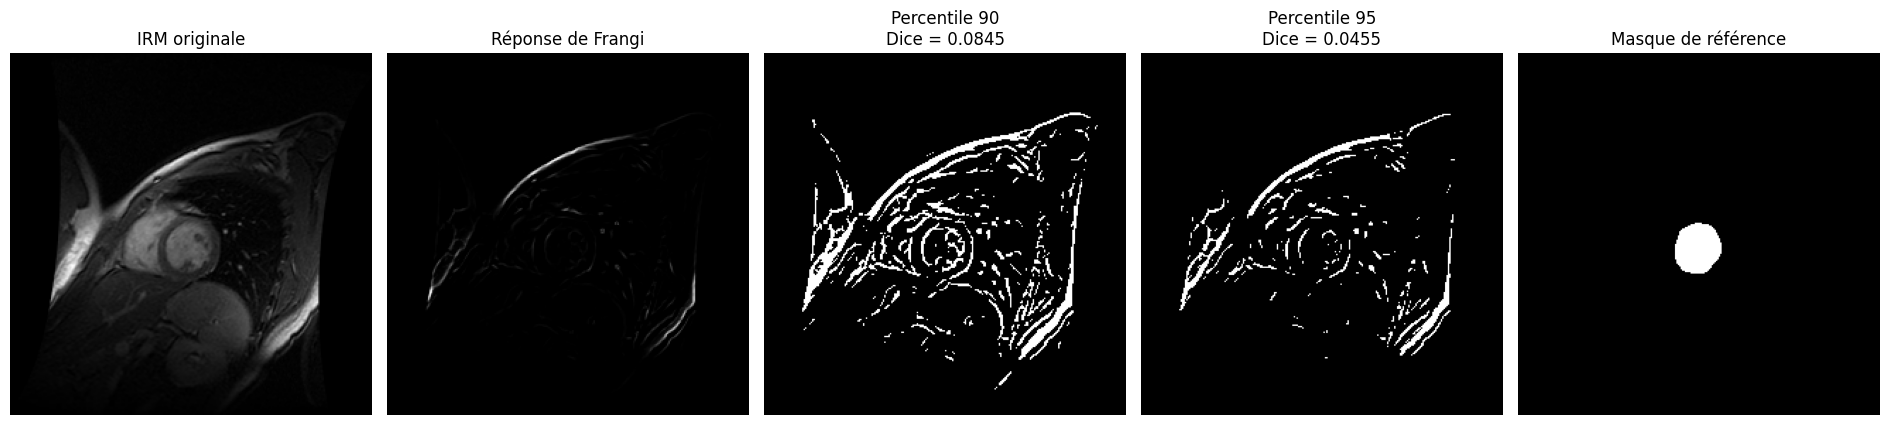

In [34]:

# 1. Normalisation de l'image
image_norm = image_coeur.astype(float) / image_coeur.max()

# 2. Application du filtre de Frangi
image_frangi_coeur = frangi(
    image_norm,
    sigmas=range(1, 6),
    black_ridges=False
)

# 3. Seuillage de la réponse du filtre
reponses = image_frangi_coeur[image_frangi_coeur > 0]

seuil_90 = np.percentile(reponses, 90)
seuil_95 = np.percentile(reponses, 95)

masque_frangi_90_coeur = image_frangi_coeur > seuil_90
masque_frangi_95_coeur = image_frangi_coeur > seuil_95

# 4. Évaluation avec le Dice
dice_frangi_90_coeur = calcul_dice(
    masque_frangi_90_coeur, reference_coeur
)

dice_frangi_95_coeur = calcul_dice(
    masque_frangi_95_coeur, reference_coeur
)

print(f"Frangi percentile 90 : Dice = {dice_frangi_90_coeur:.4f}")
print(f"Frangi percentile 95 : Dice = {dice_frangi_95_coeur:.4f}")

# 5. Visualisation
fig, axes = plt.subplots(1, 5, figsize=(19, 5))

axes[0].imshow(image_coeur, cmap="gray")
axes[0].set_title("IRM originale")

axes[1].imshow(image_frangi_coeur, cmap="gray")
axes[1].set_title("Réponse de Frangi")

axes[2].imshow(masque_frangi_90_coeur, cmap="gray")
axes[2].set_title(f"Percentile 90\nDice = {dice_frangi_90_coeur:.4f}")

axes[3].imshow(masque_frangi_95_coeur, cmap="gray")
axes[3].set_title(f"Percentile 95\nDice = {dice_frangi_95_coeur:.4f}")

axes[4].imshow(reference_coeur, cmap="gray")
axes[4].set_title("Masque de référence")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Nous avons appliqué le filtre de Frangi avec plusieurs échelles (sigmas = 1 à 5) et testé deux seuils exploratoires (percentiles 90 et 95).

*  Le filtre met surtout en évidence les contours et les structures fines de l'image, mais détecte mal l'intérieur de la cavité ventriculaire. Avec le percentile 90, nous obtenons un Dice de **0,0845**. En augmentant le seuil au percentile 95, moins de pixels sont conservés et le Dice diminue à **environ 0,0455**.

*  Frangi donne de faibles résultats car il est principalement conçu pour détecter des structures fines et allongées, alors que nous cherchons ici à segmenter une cavité. Cette méthode semble donc peu adaptée à notre objectif, contrairement aux contours actifs qui ont donné de meilleurs résultats.

## **Segmentation avec un U-Net**

#### Préparer les données du U-Net :

Nombre d'images disponibles : 220
Nombre d'images avec annotations valides : 136
Nombre de masques créés : 136


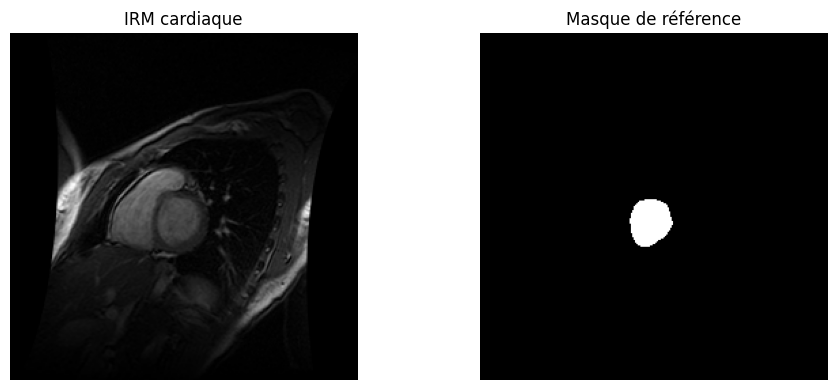

In [35]:

# Stockage des images et masques
images_cardiaques = []
masques_cardiaques = []
instants_cardiaques = []

# Fonction de création du masque par spline
def creer_masque_coeur(points, forme_image):

    # Contour intérieur : points 0 à 31
    pts = np.asarray(points[:32], dtype=float)

    x = pts[:, 0]
    y = pts[:, 1]

    # Interpolation par spline fermée
    tck, u = splprep([x, y], s=0, per=True)

    u_new = np.linspace(0, 1, 300, endpoint=False)

    x_interp, y_interp = splev(u_new, tck)

    # Conversion en masque binaire
    contour = np.column_stack((y_interp, x_interp))

    masque = polygon2mask(forme_image, contour)

    return masque


# Parcours des 11 coupes et des 20 instants
for z in range(data.shape[2]):

    for t in range(data.shape[3]):

        image = data[:, :, z, t]
        points = np.asarray(seg[z, t])

        # Ignorer les annotations absentes ou invalides
        if points.shape != (65, 2):
            continue

        if not np.isfinite(points).all():
            continue

        if not np.allclose(points[32], [0, 0]):
            continue

        # Création du masque intérieur
        try:
            masque = creer_masque_coeur(
                points,
                image.shape
            )
        except (ValueError, TypeError):
            continue

        images_cardiaques.append(image)
        masques_cardiaques.append(masque)
        instants_cardiaques.append(t)


print("Nombre d'images disponibles :", data.shape[2] * data.shape[3])

print("Nombre d'images avec annotations valides :",
      len(images_cardiaques))

print("Nombre de masques créés :",
      len(masques_cardiaques))


# Visualisation d'un exemple
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(images_cardiaques[0], cmap="gray")
axes[0].set_title("IRM cardiaque")

axes[1].imshow(masques_cardiaques[0], cmap="gray")
axes[1].set_title("Masque de référence")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Sur les **220 images cardiaques**, nous avons conservé **136 images avec des annotations valides**. Les 84 autres ont été exclues car elles ne respectent pas nos critères, notamment lorsque le ventricule gauche est absent "annotations peuvent contenir -99999".

Nous avons créé les masques de référence par interpolation afin de préparer les données pour l'entraînement du U-Net.

### Préparation des données d'entraînement et de test pour U-Net

In [36]:
# =====================================================
# EXPÉRIENCE 4.7 : PRÉPARATION DES DONNÉES POUR U-NET
# =====================================================


# 1. Conversion des listes en tableaux NumPy
X = np.stack(images_cardiaques).astype(np.float32)
Y = np.stack(masques_cardiaques).astype(np.float32)

instants = np.array(instants_cardiaques)

# 2. Séparation temporelle
indices_train = instants < 15
indices_test = instants >= 15

X_train = X[indices_train]
Y_train = Y[indices_train]

X_test = X[indices_test]
Y_test = Y[indices_test]

# 3. Normalisation entre 0 et 1
# Échelle calculée sur l'entraînement uniquement
max_train = max(X_train.max(), 1.0)

X_train = X_train / max_train
X_test = X_test / max_train

# 4. Conversion en tenseurs PyTorch
# Format : [nombre_images, canaux, hauteur, largeur]
X_train = torch.from_numpy(X_train).unsqueeze(1)
Y_train = torch.from_numpy(Y_train).unsqueeze(1)

X_test = torch.from_numpy(X_test).unsqueeze(1)
Y_test = torch.from_numpy(Y_test).unsqueeze(1)

# 5. Redimensionnement à 128 x 128
X_train_heart_128 = F.interpolate(
    X_train, size=(128, 128),
    mode="bilinear", align_corners=False
)

Y_train_heart_128 = F.interpolate(
    Y_train, size=(128, 128),
    mode="nearest"
)

X_test_heart_128 = F.interpolate(
    X_test, size=(128, 128),
    mode="bilinear", align_corners=False
)

Y_test_heart_128 = F.interpolate(
    Y_test, size=(128, 128),
    mode="nearest"
)

# 6. Vérification
print("Nombre d'images d'entraînement :", len(X_train))
print("Nombre d'images de test :", len(X_test))

print("\nDimensions des tenseurs :")
print("X_train :", X_train_heart_128.shape)
print("Y_train :", Y_train_heart_128.shape)
print("X_test  :", X_test_heart_128.shape)
print("Y_test  :", Y_test_heart_128.shape)

Nombre d'images d'entraînement : 101
Nombre d'images de test : 35

Dimensions des tenseurs :
X_train : torch.Size([101, 1, 128, 128])
Y_train : torch.Size([101, 1, 128, 128])
X_test  : torch.Size([35, 1, 128, 128])
Y_test  : torch.Size([35, 1, 128, 128])



Ici nous avons séparé les 136 images cardiaques en **101 images pour l'entraînement et 35 pour le test**, selon les instants temporels.

Les images et leurs masques ont été normalisés si nécessaire et redimensionnés à **128 × 128 pixels** pour réduire le coût de calcul.

Les données sont maintenant prêtes pour entraîner notre U-Net et évaluer ses résultats sur les images de test.

### Phase d'entrainement :

Dans cette phase, concernant la fonction de perte, nous utiliseront la**BCE + Dice Loss**, également utilisée pour l'expérience du cerveau.

* La **BCE** mesure les erreurs de prédiction pour chaque pixel, tandis que la **Dice Loss** mesure le recouvrement entre le masque prédit et le masque de référence.

Leur combinaison permet de mieux prendre en compte la petite taille du ventricule gauche par rapport au fond de l'image.

Appareil utilisé : cpu
Epoch 10/60 - Loss : 1.6262
Epoch 20/60 - Loss : 1.1712
Epoch 30/60 - Loss : 1.0548
Epoch 40/60 - Loss : 1.0402
Epoch 50/60 - Loss : 1.0220
Epoch 60/60 - Loss : 0.9865


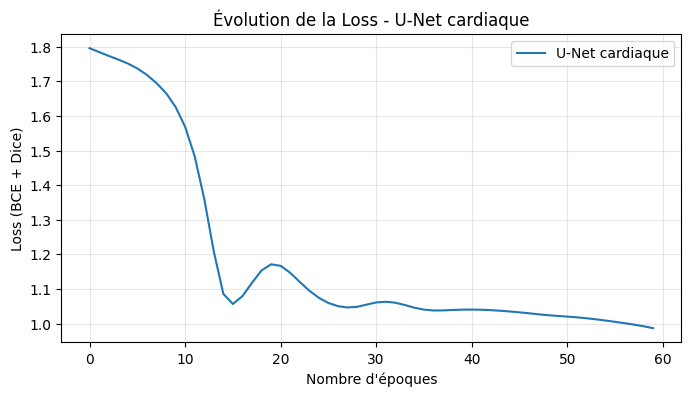

In [37]:

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Appareil utilisé :", device)

# 2. Initialisation d'un nouveau U-Net
modele_coeur = SmallUNet().to(device)

# 3. Données d'entraînement
X = X_train_heart_128.to(device)
Y = Y_train_heart_128.to(device)

# 4. Optimiseur
optimiseur_coeur = torch.optim.Adam(
    modele_coeur.parameters(),
    lr=0.001
)

# 5. Entraînement
nb_epochs = 60
historique_loss_coeur = []

modele_coeur.train()

for epoch in range(nb_epochs):

    optimiseur_coeur.zero_grad()

    # Prédiction
    prediction = modele_coeur(X)

    # Fonction de perte BCE + Dice
    loss = fonction_perte(prediction, Y)

    # Mise à jour des poids
    loss.backward()
    optimiseur_coeur.step()

    historique_loss_coeur.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{nb_epochs} "
            f"- Loss : {loss.item():.4f}"
        )

# 6. Visualisation de la Loss
plt.figure(figsize=(8, 4))

plt.plot(historique_loss_coeur, label="U-Net cardiaque")

plt.xlabel("Nombre d'époques")
plt.ylabel("Loss (BCE + Dice)")
plt.title("Évolution de la Loss - U-Net cardiaque")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

On remarque que la Loss diminue globalement, en passant d'environ 1,79 au début à 0,99 à la fin de l'entraînement. La diminution est assez rapide pendant les 15 premières époques. Ensuite, on observe une petite remontée vers l'époque 18, suivie de quelques variations.

À partir de l'époque 35, la Loss commence à se stabiliser autour de 1,04, puis diminue progressivement jusqu'à 0,9865 à la dernière époque.

Ces résultats montrent que le modèle arrive progressivement à apprendre sur les images d'entraînement. Cependant, la diminution de la Loss ne signifie pas forcément que les segmentations seront bonnes sur de nouvelles images. Il faudra donc évaluer le modèle sur les images de test avec le coefficient Dice pour vérifier ses performances.

### évaluation du U-Net :

===== ÉVALUATION DU U-NET CARDIAQUE =====
Nombre d'images testées : 35
Dice moyen : 0.0
Dice médian : 0.0
Dice minimum : 0.0
Dice maximum : 0.0

Dice pour chaque image :
Image 01 : 0.0000
Image 02 : 0.0000
Image 03 : 0.0000
Image 04 : 0.0000
Image 05 : 0.0000
Image 06 : 0.0000
Image 07 : 0.0000
Image 08 : 0.0000
Image 09 : 0.0000
Image 10 : 0.0000
Image 11 : 0.0000
Image 12 : 0.0000
Image 13 : 0.0000
Image 14 : 0.0000
Image 15 : 0.0000
Image 16 : 0.0000
Image 17 : 0.0000
Image 18 : 0.0000
Image 19 : 0.0000
Image 20 : 0.0000
Image 21 : 0.0000
Image 22 : 0.0000
Image 23 : 0.0000
Image 24 : 0.0000
Image 25 : 0.0000
Image 26 : 0.0000
Image 27 : 0.0000
Image 28 : 0.0000
Image 29 : 0.0000
Image 30 : 0.0000
Image 31 : 0.0000
Image 32 : 0.0000
Image 33 : 0.0000
Image 34 : 0.0000
Image 35 : 0.0000


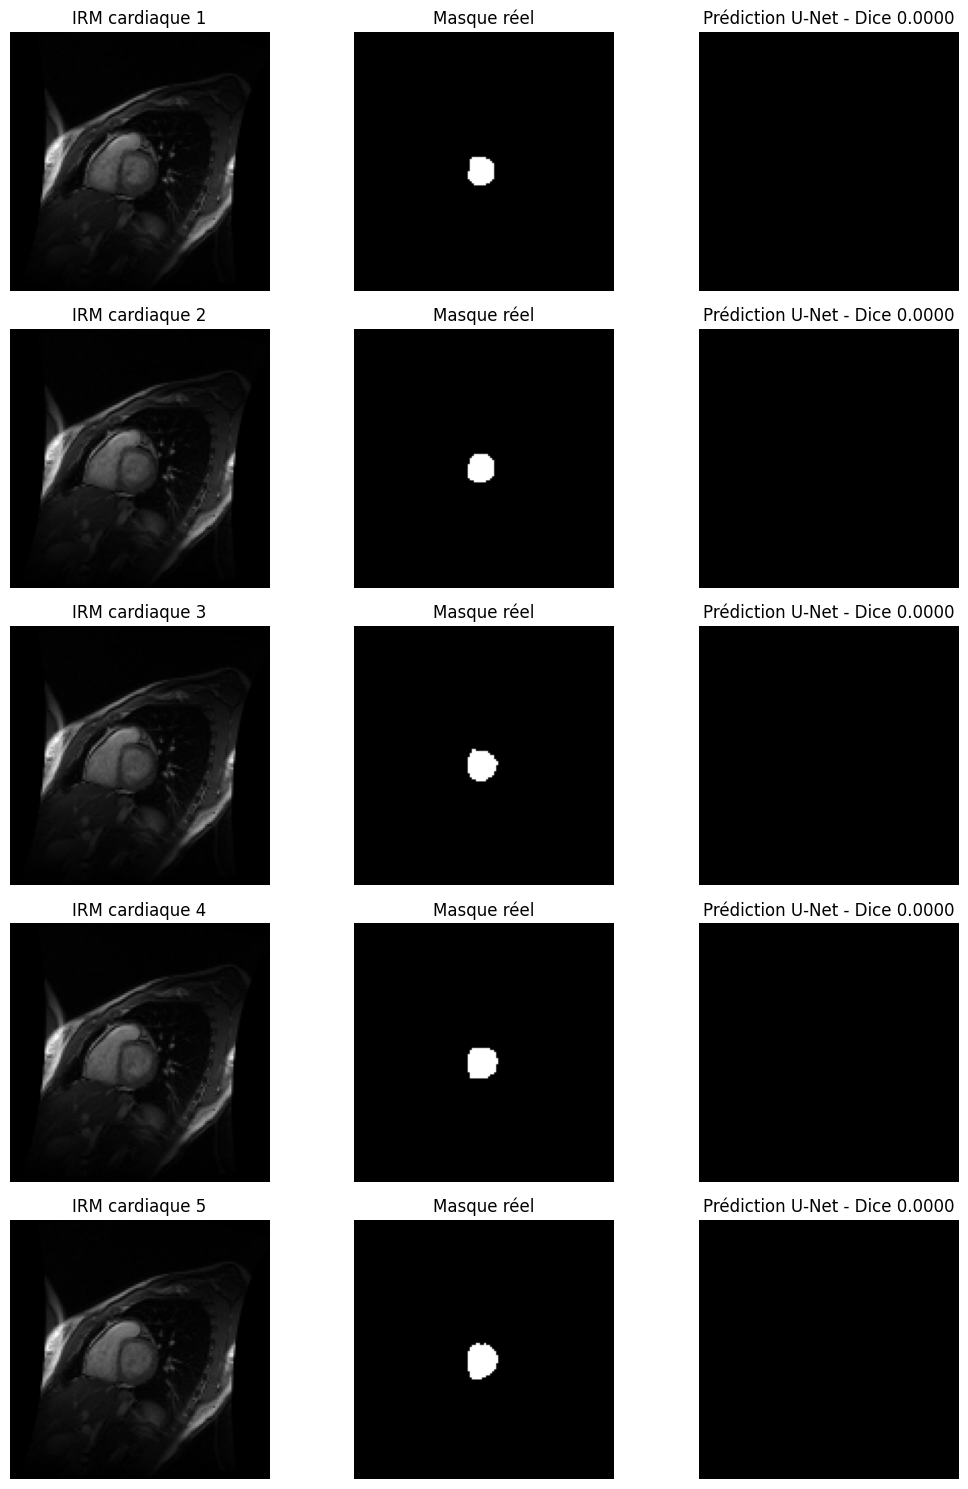

In [38]:


# 1. Passer le modèle en mode évaluation
modele_coeur.eval()

# 2. Préparer les images de test
X_test_coeur = X_test_heart_128.to(device)
Y_test_coeur = Y_test_heart_128.to(device)

# 3. Prédictions sans calcul de gradients
with torch.no_grad():
    logits = modele_coeur(X_test_coeur)
    probabilites = torch.sigmoid(logits)

    # Transformation en masques binaires
    predictions = (probabilites > 0.5).float()

# 4. Calcul du Dice pour chaque image
intersection = (
    predictions * Y_test_coeur
).sum(dim=(1, 2, 3))

total = predictions.sum(dim=(1, 2, 3)) + \
        Y_test_coeur.sum(dim=(1, 2, 3))

dice_scores = torch.where(
    total > 0,
    (2 * intersection) / total.clamp(min=1e-8),
    torch.ones_like(total)
)

dice_scores = dice_scores.cpu().numpy()

# 5. Résultats globaux
print("===== ÉVALUATION DU U-NET CARDIAQUE =====")

print("Nombre d'images testées :", len(dice_scores))
print("Dice moyen :", round(float(np.mean(dice_scores)), 4))
print("Dice médian :", round(float(np.median(dice_scores)), 4))
print("Dice minimum :", round(float(np.min(dice_scores)), 4))
print("Dice maximum :", round(float(np.max(dice_scores)), 4))

print("\nDice pour chaque image :")
for i, score in enumerate(dice_scores):
    print(f"Image {i+1:02d} : {score:.4f}")

# 6. Visualisation de quelques segmentations
images_np = X_test_coeur.cpu().numpy()
masques_np = Y_test_coeur.cpu().numpy()
predictions_np = predictions.cpu().numpy()

nb_images = min(5, len(images_np))

fig, axes = plt.subplots(
    nb_images, 3,
    figsize=(11, 3 * nb_images),
    squeeze=False
)

for i in range(nb_images):

    axes[i, 0].imshow(
        images_np[i, 0], cmap="gray"
    )
    axes[i, 0].set_title(f"IRM cardiaque {i+1}")

    axes[i, 1].imshow(
        masques_np[i, 0], cmap="gray",
        vmin=0, vmax=1
    )
    axes[i, 1].set_title("Masque réel")

    axes[i, 2].imshow(
        predictions_np[i, 0], cmap="gray",
        vmin=0, vmax=1
    )
    axes[i, 2].set_title(
        f"Prédiction U-Net - Dice {dice_scores[i]:.4f}"
    )

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()



- Le Dice de 0 sur les 35 images de test, ce qui montre que notre modèle n'arrive pas à segmenter correctement les régions cardiaques.

- Le nombre limité d'images d'entraînement ne permet peut-être pas au modèle d'apprendre suffisamment cette diversité. Il faudrait donc davantage d'images variées pour améliorer ses performances.

- Le modèle peut aussi avoir tendance à prédire principalement le fond, car la région à segmenter occupe une petite partie de l'image.

- Enfin, l'ajout d'une phase de validation permettrait de mieux suivre l'apprentissage et d'ajuster les paramètres du modèle.

Pour conclure, les résultats obtenus montrent les limites de notre U-Net face à des images cardiaques complexes et hétérogènes. Pour améliorer la segmentation, il faudrait surtout utiliser davantage de données variées et optimiser l'entraînement.

## Comparaison des méthodes de segmentation cardiaque :

In [40]:

# =====================================================
# Comparaison des méthodes de segmentation cardiaque
# Étape 1 : Tableau récapitulatif des scores Dice
# =====================================================

import pandas as pd

# Résultats des méthodes classiques obtenus précédemment
resultats_coeur = {
    "Méthode": [
        "Seuillage T=50",
        "Seuillage T=150",
        "Seuillage T=300",
        "Otsu",
        "Snake beta=1",
        "Snake beta=0.1",
        "MorphGAC balloon=0",
        "MorphGAC balloon=1",
        "Frangi P90",
        "Frangi P95"
    ],

    "Dice": [
        0.0768,
        0.1629,
        0.2610,
        0.2389,
        0.8899,
        0.8797,
        0.9357,
        0.8736,
        0.0845,
        0.0455
    ]
}

# Création du tableau
df_coeur = pd.DataFrame(resultats_coeur)

# Classement selon le score Dice (du plus grand au plus petit)
df_coeur = df_coeur.sort_values(
    by="Dice",
    ascending=False
).reset_index(drop=True)

# Affichage des résultats
print("===== COMPARAISON DES MÉTHODES CLASSIQUES =====")
display(df_coeur.round(4))

# Identification de la meilleure méthode
print("\nMeilleure méthode :", df_coeur.iloc[0]["Méthode"])
print("Score Dice :", df_coeur.iloc[0]["Dice"])

# Résultats U-Net présentés séparément
print("\n===== U-NET CARDIAQUE =====")
print("Nombre d'images de test :", len(dice_scores))
print("Dice moyen :", round(float(dice_scores.mean()), 4))

print("\nRemarque : les méthodes classiques ont été évaluées")
print("sur une image, tandis que le U-Net a été évalué")
print("sur 35 images de test.")


===== COMPARAISON DES MÉTHODES CLASSIQUES =====


,Méthode,Dice
0,MorphGAC balloon=0,0.9357
1,Snake beta=1,0.8899
2,Snake beta=0.1,0.8797
3,MorphGAC balloon=1,0.8736
4,Seuillage T=300,0.2610
5,Otsu,0.2389
6,Seuillage T=150,0.1629
7,Frangi P90,0.0845
8,Seuillage T=50,0.0768
9,Frangi P95,0.0455



Meilleure méthode : MorphGAC balloon=0
Score Dice : 0.9357

===== U-NET CARDIAQUE =====
Nombre d'images de test : 35
Dice moyen : 0.0

Remarque : les méthodes classiques ont été évaluées
sur une image, tandis que le U-Net a été évalué
sur 35 images de test.



- **MorphGAC avec balloon = 0** obtient le meilleur score Dice (0,9357), suivi du Snake avec beta = 1 (0,8899). Ces résultats montrent que les contours actifs sont efficaces sur l'image cardiaque étudiée.

- Les méthodes de seuillage et Otsu donnent des résultats plus faibles, car les structures cardiaques présentent des intensités parfois similaires.

- Le filtre de Frangi obtient de faibles scores, car il est plutôt adapté à la détection des structures allongées comme les vaisseaux.

- Le U-Net obtient un Dice moyen de 0 sur les 35 images de test, ce qui montre ses limites avec notre configuration actuelle.

**Conclusion :** MorphGAC donne le meilleur résultat dans notre expérience, mais cela ne signifie pas qu'il est toujours supérieur aux autres méthodes. Ses performances peuvent dépendre de l'image étudiée, de l'initialisation du contour et des paramètres choisis. De plus, les méthodes classiques ont été évaluées sur une seule image, contrairement au U-Net testé sur 35 images. Il faudrait donc évaluer toutes les méthodes sur plusieurs images dans les mêmes conditions pour pouvoir tirer une conclusion plus générale.

# vessel segmentation ( DRIVE DATASET ) :

### Chargement du dataset :

In [41]:

for root, dirs, files in os.walk(Working_directory):
    if "drive" in os.path.basename(root).lower():
        print("\nDossier trouvé :", root)
        print("Sous-dossiers :", dirs)
        print("Fichiers :", files[:10])



Dossier trouvé : /content/drive/MyDrive/TP medical images analysis/dataTPseg/DRIVE
Sous-dossiers : ['training', 'test']
Fichiers : []


In [42]:

# =====================================================
# DRIVE - Étape 2 : Exploration du dataset
# =====================================================

drive_path = os.path.join(Working_directory, "DRIVE")

for partie in ["training", "test"]:

    dossier = os.path.join(drive_path, partie)

    print(f"\n===== {partie.upper()} =====")

    for root, dirs, files in os.walk(dossier):

        print("\nDossier :", root)
        print("Nombre de fichiers :", len(files))
        print("Exemples :", sorted(files)[:5])



===== TRAINING =====

Dossier : /content/drive/MyDrive/TP medical images analysis/dataTPseg/DRIVE/training
Nombre de fichiers : 0
Exemples : []

Dossier : /content/drive/MyDrive/TP medical images analysis/dataTPseg/DRIVE/training/mask
Nombre de fichiers : 20
Exemples : ['21_training_mask.gif', '22_training_mask.gif', '23_training_mask.gif', '24_training_mask.gif', '25_training_mask.gif']

Dossier : /content/drive/MyDrive/TP medical images analysis/dataTPseg/DRIVE/training/1st_manual
Nombre de fichiers : 20
Exemples : ['21_manual1.gif', '22_manual1.gif', '23_manual1.gif', '24_manual1.gif', '25_manual1.gif']

Dossier : /content/drive/MyDrive/TP medical images analysis/dataTPseg/DRIVE/training/images
Nombre de fichiers : 20
Exemples : ['21_training.tif', '22_training.tif', '23_training.tif', '24_training.tif', '25_training.tif']

===== TEST =====

Dossier : /content/drive/MyDrive/TP medical images analysis/dataTPseg/DRIVE/test
Nombre de fichiers : 0
Exemples : []

Dossier : /content/driv

## Etape 01 : Étude de l'image rétinienne et de son histogramme.

Dimensions : (584, 565, 3)
Type : uint8
Canal Rouge : min=0, max=255, moyenne=138.73
Canal Vert : min=0, max=255, moyenne=82.78
Canal Bleu : min=0, max=168, moyenne=54.38


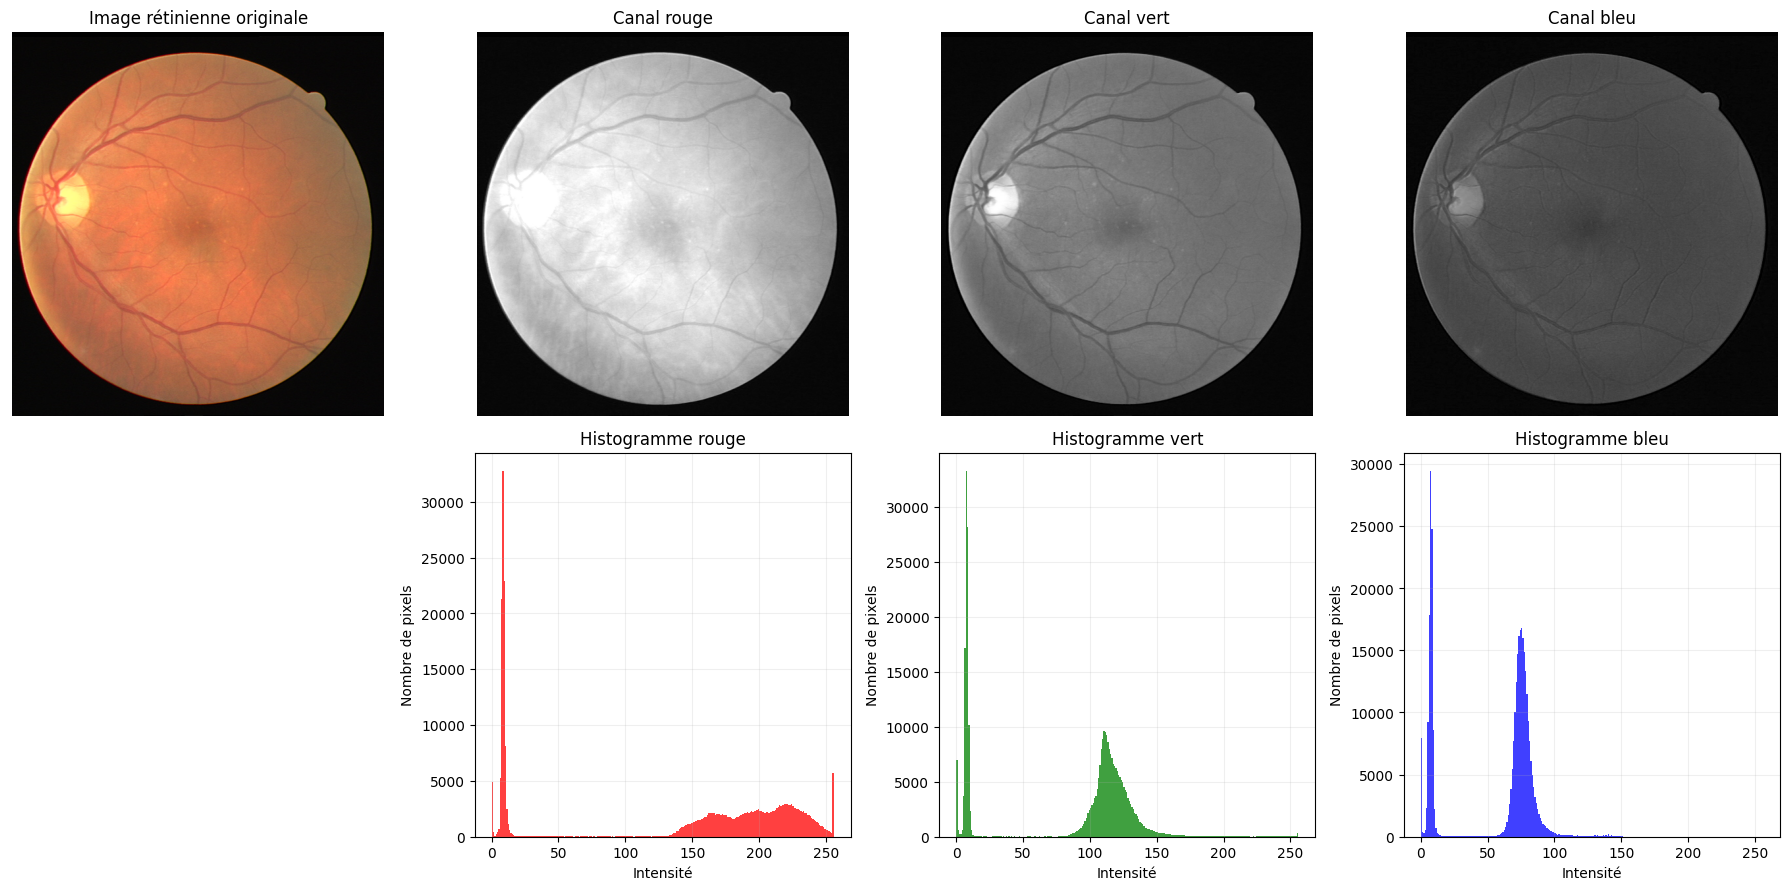

In [55]:


image_path = os.path.join(
    drive_path, "training", "images", "21_training.tif"
)

image_retine = np.array(
    Image.open(image_path).convert("RGB")
)


canal_rouge = image_retine[:, :, 0]
canal_vert = image_retine[:, :, 1]
canal_bleu = image_retine[:, :, 2]

print("Dimensions :", image_retine.shape)
print("Type :", image_retine.dtype)

for nom, canal in [
    ("Rouge", canal_rouge),
    ("Vert", canal_vert),
    ("Bleu", canal_bleu)
]:
    print(
        f"Canal {nom} : "
        f"min={canal.min()}, max={canal.max()}, "
        f"moyenne={canal.mean():.2f}"
    )


fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes[0, 0].imshow(image_retine)
axes[0, 0].set_title("Image rétinienne originale")

axes[0, 1].imshow(canal_rouge, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Canal rouge")

axes[0, 2].imshow(canal_vert, cmap="gray", vmin=0, vmax=255)
axes[0, 2].set_title("Canal vert")

axes[0, 3].imshow(canal_bleu, cmap="gray", vmin=0, vmax=255)
axes[0, 3].set_title("Canal bleu")


canaux = [
    (canal_rouge, "red", "Histogramme rouge"),
    (canal_vert, "green", "Histogramme vert"),
    (canal_bleu, "blue", "Histogramme bleu")
]

axes[1, 0].axis("off")

for ax, (canal, couleur, titre) in zip(
    axes[1, 1:], canaux
):
    ax.hist(
        canal.ravel(),
        bins=256,
        range=(0, 256),
        color=couleur,
        alpha=0.75
    )
    ax.set_title(titre)
    ax.set_xlabel("Intensité")
    ax.set_ylabel("Nombre de pixels")
    ax.grid(alpha=0.2)

for ax in axes[0]:
    ax.axis("off")

plt.tight_layout()
plt.show()


L'image rétinienne présente trois canaux RGB avec des intensités différentes. On remarque que le **canal rouge** est le plus lumineux, tandis que le canal bleu est plus sombre. Le **canal vert offre un meilleur contraste**, ce qui permet de mieux distinguer les vaisseaux sanguins. Les histogrammes montrent également un pic aux faibles intensités, principalement dû au fond noir autour de la rétine. Nous allons donc utiliser le canal vert pour la suite de la segmentation.

## Segmentation par seuillage manuel :

Nous allons utiliser le canal vert, car les vaisseaux sanguins y apparaissent plus sombres que les tissus environnants.

Seuil T=50 : Dice = 0.0002
Seuil T=80 : Dice = 0.0030
Seuil T=110 : Dice = 0.3290


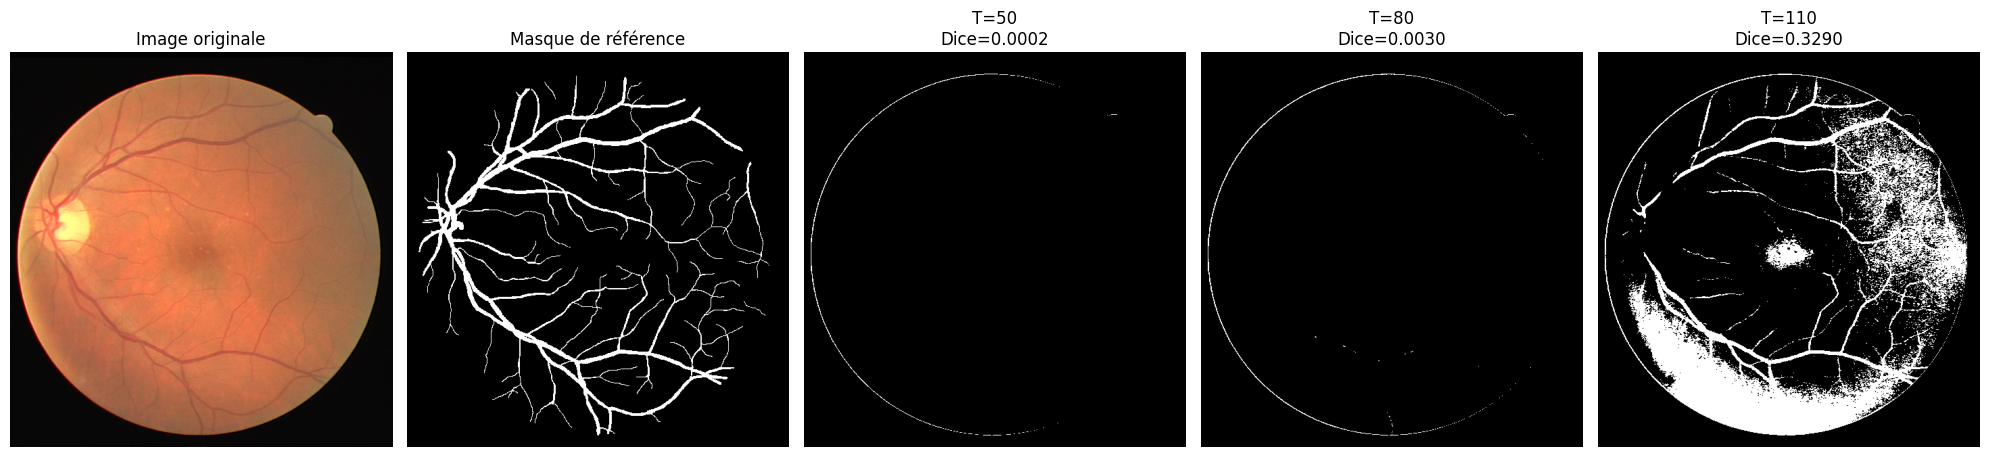

In [58]:

# 1. Chargement de l'annotation manuelle
annotation_path = os.path.join(
    drive_path, "training", "1st_manual",
    "21_manual1.gif"
)

# Masque de la zone rétinienne
masque_path = os.path.join(
    drive_path, "training", "mask",
    "21_training_mask.gif"
)

annotation_vaisseaux = np.array(
    Image.open(annotation_path).convert("L")
) > 0

masque_retine = np.array(
    Image.open(masque_path).convert("L")
) > 0

# Référence limitée à la zone rétinienne
reference = annotation_vaisseaux & masque_retine

# 2. Fonction de calcul du Dice
def dice_drive(prediction, reference):
    intersection = np.logical_and(
        prediction, reference
    ).sum()

    total = prediction.sum() + reference.sum()

    return 2 * intersection / total if total > 0 else 1.0

# 3. Application des seuils
seuils = [50, 80, 110]
predictions = []
scores_dice = []

for seuil in seuils:

    prediction = (canal_vert < seuil) & masque_retine
    dice = dice_drive(prediction, reference)

    predictions.append(prediction)
    scores_dice.append(dice)

    print(f"Seuil T={seuil} : Dice = {dice:.4f}")

# 4. Visualisation des résultats
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

axes[0].imshow(image_retine)
axes[0].set_title("Image originale")

axes[1].imshow(reference, cmap="gray")
axes[1].set_title("Masque de référence")

for i, seuil in enumerate(seuils):
    axes[i + 2].imshow(
        predictions[i], cmap="gray",
        vmin=0, vmax=1
    )
    axes[i + 2].set_title(
        f"T={seuil}\nDice={scores_dice[i]:.4f}"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Nous avons testé trois seuils choisis de manière arbitraire (T=50, 80 et 110) pour segmenter les vaisseaux sanguins à partir du canal vert.

On remarque que les seuils 50 et 80 donnent des Dice presque nuls (0,0002 et 0,0030), car très peu de vaisseaux sont détectés. Le seuil 110 donne un meilleur résultat avec un Dice de 0,3290, mais il détecte également beaucoup de régions qui ne correspondent pas aux vaisseaux.

Ces résultats montrent que le seuillage manuel reste limité à cause des variations d'intensité dans l'image rétinienne. Un seul seuil ne permet pas de distinguer correctement tous les vaisseaux du fond.

## Segmentation automatique par Otsu :

Maintenant, contrairement au seuillage manuel, où nous avons choisi les seuils 50, 80 et 110 de manière arbitraire, la méthode d'Otsu détermine automatiquement un seuil à partir de l'histogramme.

===== SEGMENTATION PAR OTSU - DRIVE =====
Seuil Otsu : 144
Dice Otsu : 0.1992


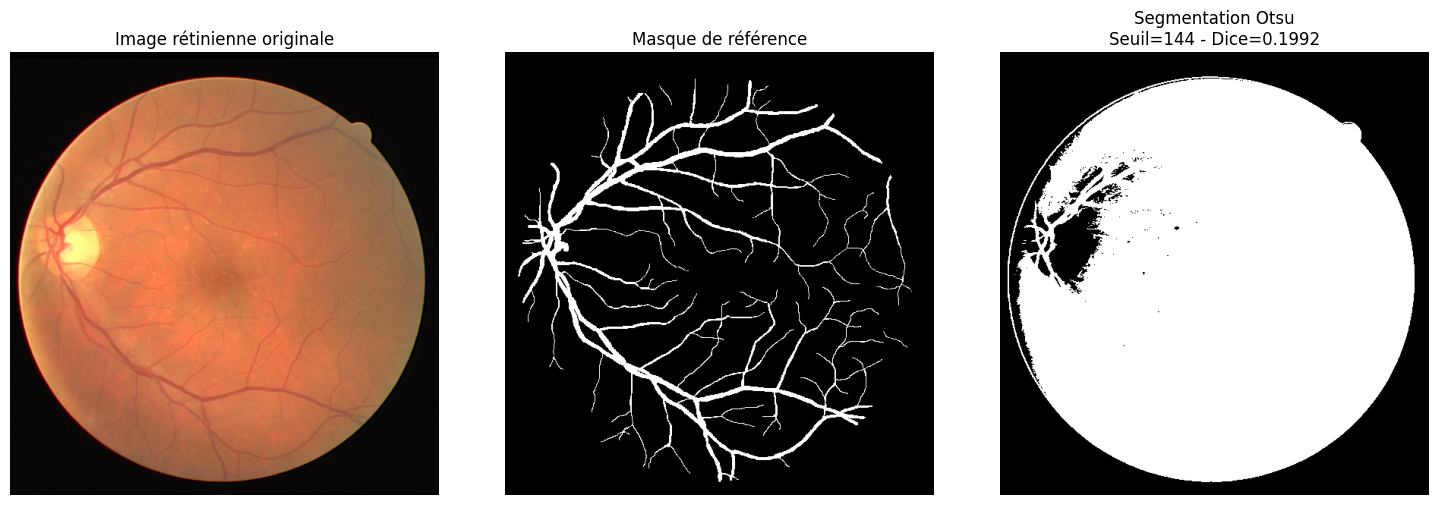

In [59]:


# 1. Calcul du seuil Otsu dans la zone rétinienne
seuil_otsu = threshold_otsu(canal_vert[masque_retine])

# 2. Segmentation des vaisseaux sombres
prediction_otsu = (canal_vert < seuil_otsu) & masque_retine

# 3. Calcul du coefficient Dice
dice_otsu = dice_drive(prediction_otsu, reference)

print("===== SEGMENTATION PAR OTSU - DRIVE =====")
print(f"Seuil Otsu : {seuil_otsu}")
print(f"Dice Otsu : {dice_otsu:.4f}")

# 4. Visualisation des résultats
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_retine)
axes[0].set_title("Image rétinienne originale")

axes[1].imshow(reference, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Masque de référence")

axes[2].imshow(prediction_otsu, cmap="gray", vmin=0, vmax=1)
axes[2].set_title(
    f"Segmentation Otsu\nSeuil={seuil_otsu} - Dice={dice_otsu:.4f}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


On remarque que la segmentation détecte une grande partie du fond rétinien au lieu de sélectionner uniquement les vaisseaux sanguins. Cela s'explique par les variations d'intensité dans l'image et le faible contraste entre certaines structures. Le seuil choisi est donc trop élevé pour isoler correctement les vaisseaux. **Otsu donne ainsi un résultat moins bon que le seuillage manuel à T=110 (Dice = 0,3290).**

Pour la suite, nous allons tester des méthodes de segmentation plus adaptées aux structures fines et allongées des vaisseaux sanguins, afin de voir si nous pouvons obtenir de meilleurs résultats.

## Segmentation avec le filtre de Frangi :

Frangi P90 : seuil=0.003596, Dice=0.6377
Frangi P95 : seuil=0.011400, Dice=0.5005


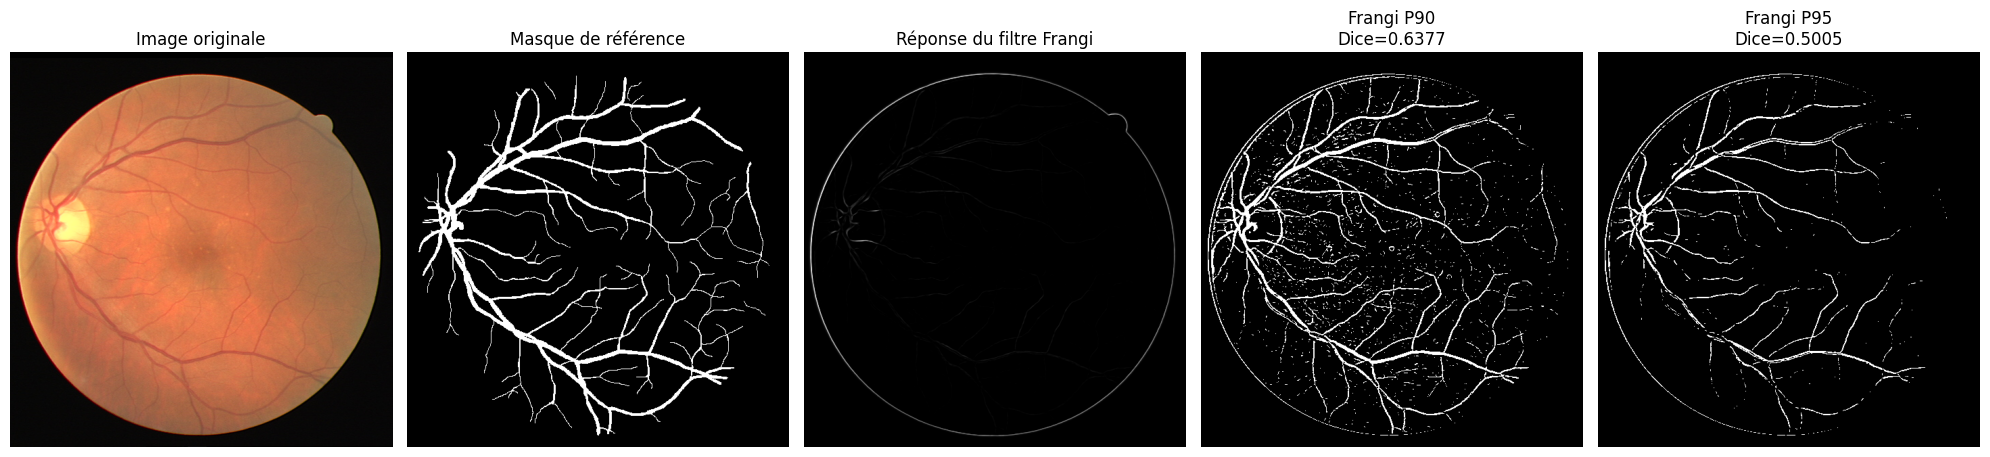

In [60]:

# 1. Normalisation du canal vert entre 0 et 1
image_frangi = canal_vert.astype(np.float32) / 255.0

# 2. Application du filtre de Frangi
# Les vaisseaux sont sombres sur le fond rétinien
reponse_frangi = frangi(
    image_frangi,
    sigmas=np.arange(1, 5, 1),
    black_ridges=True
)

# 3. Calcul des seuils uniquement dans la rétine
percentiles = [90, 95]
predictions_frangi = []
dice_frangi = []

for p in percentiles:

    seuil = np.percentile(
        reponse_frangi[masque_retine], p
    )

    prediction = (
        (reponse_frangi > seuil) & masque_retine
    )

    score = dice_drive(prediction, reference)

    predictions_frangi.append(prediction)
    dice_frangi.append(score)

    print(
        f"Frangi P{p} : seuil={seuil:.6f}, "
        f"Dice={score:.4f}"
    )

# 4. Visualisation des résultats
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

axes[0].imshow(image_retine)
axes[0].set_title("Image originale")

axes[1].imshow(reference, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Masque de référence")

axes[2].imshow(reponse_frangi, cmap="gray")
axes[2].set_title("Réponse du filtre Frangi")

for i, p in enumerate(percentiles):

    axes[i + 3].imshow(
        predictions_frangi[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i + 3].set_title(
        f"Frangi P{p}\nDice={dice_frangi[i]:.4f}"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()



Le filtre de Frangi donne de meilleurs résultats que le seuillage manuel et la méthode d'Otsu. Cela s'explique par le fait qu'il est spécialement adapté à la détection des structures fines et allongées, comme les vaisseaux sanguins. Contrairement aux méthodes précédentes, il prend en compte la forme des structures et pas seulement l'intensité des pixels.

Avec le **percentile 90, nous obtenons un Dice de 0,6377**, ce qui est un résultat plutôt satisfaisant. On remarque que la majorité des gros vaisseaux sont bien détectés, ainsi qu'une partie des vaisseaux plus fins. Cependant, la segmentation contient également du bruit et certaines régions qui ne correspondent pas aux vaisseaux, notamment près des bords de la rétine.

Avec le **percentile 95, le Dice diminue à 0,5005**. En augmentant le seuil, la segmentation devient plus sélective : on élimine une partie du bruit, mais on perd également plusieurs vaisseaux fins et certaines portions des vaisseaux principaux. Cela explique la diminution du Dice malgré une image visuellement plus propre.

Ces résultats montrent qu'il faut trouver un compromis entre la détection des vaisseaux et l'élimination du bruit. Un seuil trop élevé risque de supprimer des structures importantes.

**Conclusion :** Frangi P90 donne le meilleur résultat parmi les méthodes testées jusqu'à présent sur cette image, avec un Dice de 0,6377, contre 0,3290 pour le seuillage manuel et 0,1992 pour Otsu. Cette méthode semble donc mieux adaptée à la segmentation des vaisseaux rétiniens. Cependant, ses performances pourraient encore être améliorées en réduisant le bruit et en limitant les fausses détections près des bords de la rétine.

## Amélioration de Frangi par ouverture morphologique :

===== OUVERTURE MORPHOLOGIQUE - DRIVE =====
Frangi P90 original : Dice = 0.6377
Ouverture rayon=1 : Dice = 0.5521
Ouverture rayon=2 : Dice = 0.2876


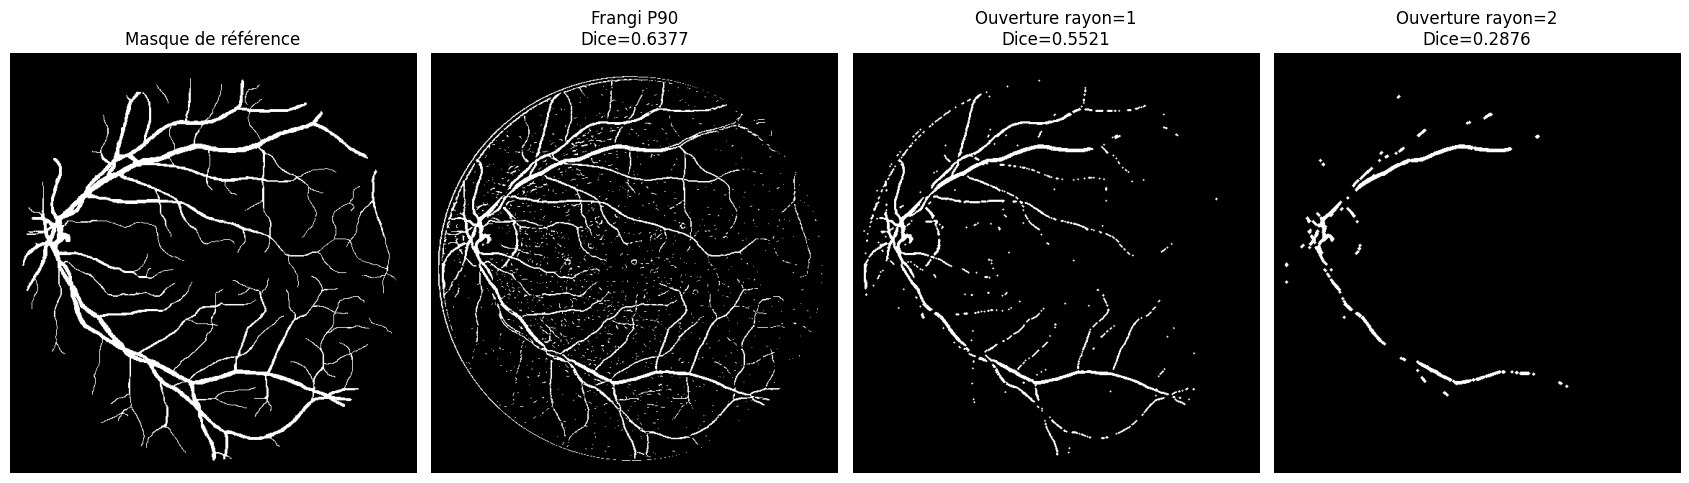

In [61]:

# =====================================================
# DRIVE - Post-traitement par ouverture morphologique
# =====================================================

import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import binary_opening, disk

# 1. Récupération de la segmentation Frangi P90
prediction_p90 = predictions_frangi[0].astype(bool)

# 2. Ouverture morphologique avec différents rayons
rayons = [1, 2]

predictions_ouverture = []
scores_ouverture = []

print("===== OUVERTURE MORPHOLOGIQUE - DRIVE =====")

dice_initial = dice_drive(prediction_p90, reference)
print(f"Frangi P90 original : Dice = {dice_initial:.4f}")

for rayon in rayons:

    # Élément structurant circulaire
    element = disk(rayon)

    # Érosion suivie d'une dilatation
    prediction = binary_opening(
        prediction_p90,
        footprint=element
    )

    # Limiter la segmentation à la zone rétinienne
    prediction = prediction & masque_retine

    # Calcul du Dice
    dice = dice_drive(prediction, reference)

    predictions_ouverture.append(prediction)
    scores_ouverture.append(dice)

    print(
        f"Ouverture rayon={rayon} : Dice = {dice:.4f}"
    )

# 3. Visualisation
fig, axes = plt.subplots(1, 4, figsize=(17, 5))

axes[0].imshow(reference, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Masque de référence")

axes[1].imshow(prediction_p90, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Frangi P90\nDice={dice_initial:.4f}")

for i, rayon in enumerate(rayons):

    axes[i + 2].imshow(
        predictions_ouverture[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i + 2].set_title(
        f"Ouverture rayon={rayon}\n"
        f"Dice={scores_ouverture[i]:.4f}"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()



Nous avons appliqué une **ouverture morphologique** sur la segmentation Frangi P90 afin de réduire le bruit et de supprimer les petits points blancs isolés. Cette méthode consiste à effectuer une érosion suivie d'une dilatation.

Avec un **rayon de 1 pixel**, le Dice diminue de 0,6377 à 0,5521. On remarque que le bruit est réduit, mais que certains vaisseaux fins disparaissent également et que plusieurs contours deviennent discontinus.

Avec un **rayon de 2 pixels**, le Dice chute à 0,2876. L'ouverture devient trop importante et supprime une grande partie des vaisseaux, en conservant principalement les structures les plus épaisses.

Ces résultats montrent que **l'ouverture morphologique permet de réduire le bruit, mais risque aussi de détruire les structures fines** que nous cherchons à segmenter.


Maintenant on va tester la reconstruction morphologique afin de voir si elle permet de réduire le bruit tout en préservant davantage les vaisseaux sanguins et leur continuité.

## Reconstruction morphologique après Frangi :

===== RECONSTRUCTION MORPHOLOGIQUE - DRIVE =====
Frangi P90 original : Dice = 0.6377
Reconstruction rayon=1 : Dice = 0.6526
Reconstruction rayon=2 : Dice = 0.6318


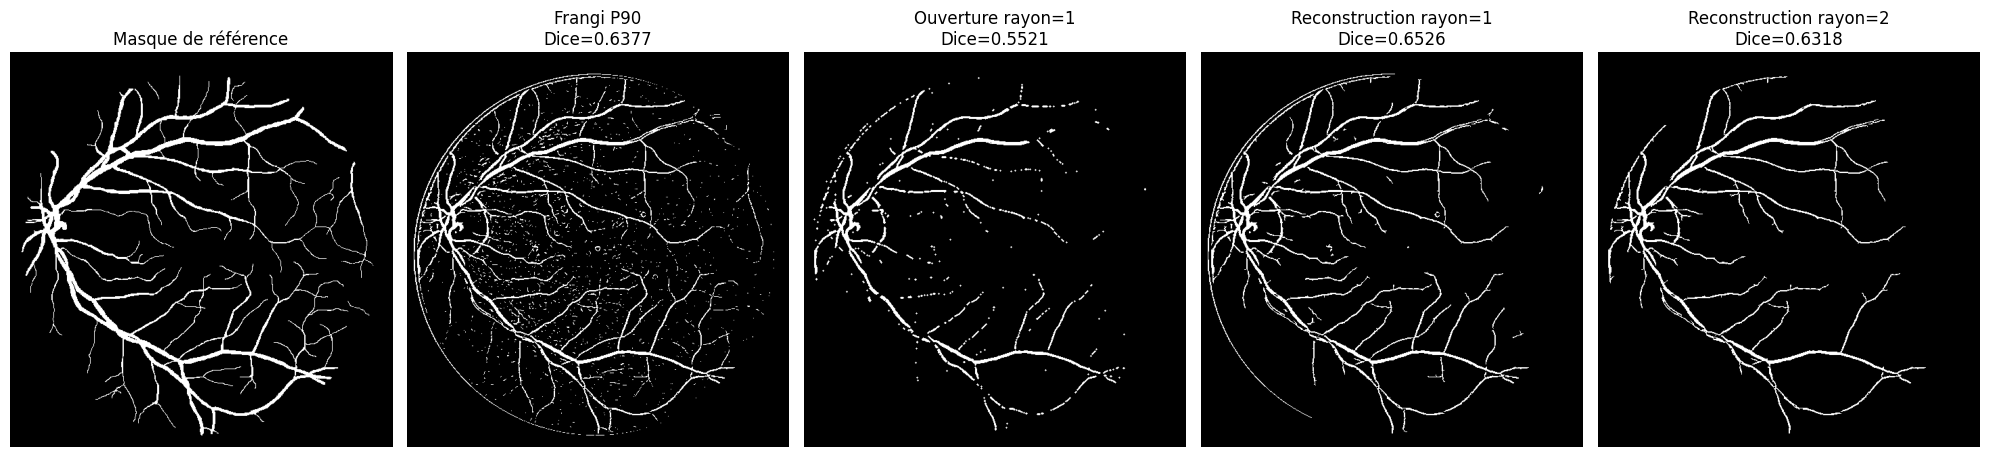

In [62]:

from skimage.morphology import (
    binary_erosion,
    disk,
    reconstruction
)

# 1. Segmentation initiale Frangi P90
prediction_p90 = predictions_frangi[0].astype(bool)

# 2. Reconstruction morphologique
rayons = [1, 2]

predictions_reconstruction = []
scores_reconstruction = []

print("===== RECONSTRUCTION MORPHOLOGIQUE - DRIVE =====")

dice_initial = dice_drive(prediction_p90, reference)

print(f"Frangi P90 original : Dice = {dice_initial:.4f}")

for rayon in rayons:

    # Élément structurant
    element = disk(rayon)

    # Érosion : suppression des petites structures
    marqueur = binary_erosion(
        prediction_p90,
        footprint=element
    )

    # Reconstruction par dilatation sous le masque original
    reconstruction_image = reconstruction(
        marqueur.astype(np.uint8),
        prediction_p90.astype(np.uint8),
        method="dilation"
    )

    # Conversion en masque binaire
    prediction = (reconstruction_image > 0) & masque_retine

    # Calcul du Dice
    dice = dice_drive(prediction, reference)

    predictions_reconstruction.append(prediction)
    scores_reconstruction.append(dice)

    print(
        f"Reconstruction rayon={rayon} : "
        f"Dice = {dice:.4f}"
    )

# 3. Comparaison visuelle
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

axes[0].imshow(reference, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Masque de référence")

axes[1].imshow(prediction_p90, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(
    f"Frangi P90\nDice={dice_initial:.4f}"
)

axes[2].imshow(predictions_ouverture[0], cmap="gray", vmin=0, vmax=1)
axes[2].set_title(
    f"Ouverture rayon=1\nDice={scores_ouverture[0]:.4f}"
)

for i, rayon in enumerate(rayons):

    axes[i + 3].imshow(
        predictions_reconstruction[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i + 3].set_title(
        f"Reconstruction rayon={rayon}\n"
        f"Dice={scores_reconstruction[i]:.4f}"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Nous avons appliqué une **reconstruction morphologique** après le filtre de Frangi P90 afin de réduire le bruit tout en préservant la continuité des vaisseaux sanguins.

Avec un **rayon de 1 pixel**, nous obtenons un Dice de **0,6526**, légèrement supérieur à celui de Frangi seul (0,6377). On remarque que la reconstruction élimine une grande partie des petits points isolés tout en conservant la majorité des vaisseaux, contrairement à l'ouverture classique qui supprimait plusieurs structures fines.

Avec un **rayon de 2 pixels**, le Dice diminue à 0,6318. Même si le résultat est visuellement plus propre, certains vaisseaux fins disparaissent, ce qui entraîne une perte d'informations et une diminution du Dice.

Ces résultats montrent que la reconstruction morphologique permet de mieux préserver les structures connectées tout en réduisant le bruit, mais que son efficacité dépend du rayon choisi.

Maintenant, nous allons appliquer cette méthode sur plusieurs images du dataset afin de voir si l'amélioration observée se confirme et si les résultats restent satisfaisants malgré les différences entre les images rétiniennes.

### Évaluation sur plusieurs images DRIVE :

In [63]:

resultats_drive = []

for numero in range(21, 41):

    # 1. Chargement des données
    image_path = os.path.join(
        drive_path, "training", "images",
        f"{numero}_training.tif"
    )

    annotation_path = os.path.join(
        drive_path, "training", "1st_manual",
        f"{numero}_manual1.gif"
    )

    masque_path = os.path.join(
        drive_path, "training", "mask",
        f"{numero}_training_mask.gif"
    )

    image = np.array(Image.open(image_path).convert("RGB"))

    annotation = np.array(
        Image.open(annotation_path).convert("L")
    ) > 0

    masque = np.array(
        Image.open(masque_path).convert("L")
    ) > 0

    reference_image = annotation & masque

    # 2. Canal vert normalisé
    vert = image[:, :, 1].astype(np.float32) / 255.0

    # 3. Filtre Frangi
    reponse = frangi(
        vert,
        sigmas=np.arange(1, 5, 1),
        black_ridges=True
    )

    # 4. Seuillage au percentile 90
    seuil = np.percentile(reponse[masque], 90)

    prediction_frangi = (reponse > seuil) & masque

    dice_initial = dice_drive(
        prediction_frangi, reference_image
    )

    # 5. Reconstruction morphologique
    marqueur = binary_erosion(
        prediction_frangi,
        footprint=disk(1)
    )

    reconstruction_image = reconstruction(
        marqueur.astype(np.uint8),
        prediction_frangi.astype(np.uint8),
        method="dilation"
    )

    prediction_reconstruction = (
        reconstruction_image > 0
    ) & masque

    dice_reconstruit = dice_drive(
        prediction_reconstruction, reference_image
    )

    # 6. Sauvegarde des résultats
    resultats_drive.append({
        "Image": f"{numero}_training",
        "Dice Frangi P90": dice_initial,
        "Dice Reconstruction": dice_reconstruit
    })

# 7. Tableau récapitulatif
df_drive = pd.DataFrame(resultats_drive)

print("===== EVALUATION SUR 20 IMAGES DRIVE =====")
display(df_drive.round(4))

# 8. Résultats moyens
print("\n===== SCORES MOYENS =====")

print(
    "Dice moyen Frangi P90 :",
    round(df_drive["Dice Frangi P90"].mean(), 4)
)

print(
    "Dice moyen avec reconstruction :",
    round(df_drive["Dice Reconstruction"].mean(), 4)
)

# 9. Nombre d'images améliorées
nb_ameliorations = (
    df_drive["Dice Reconstruction"]
    > df_drive["Dice Frangi P90"]
).sum()

print(
    "\nNombre d'images améliorées :",
    nb_ameliorations,
    "/ 20"
)


===== EVALUATION SUR 20 IMAGES DRIVE =====


,Image,Dice Frangi P90,Dice Reconstruction
0,21_training,0.6377,0.6526
1,22_training,0.6111,0.6005
2,23_training,0.5135,0.5384
3,24_training,0.5786,0.5524
4,25_training,0.5049,0.5031
5,26_training,0.5543,0.5903
6,27_training,0.6060,0.5976
7,28_training,0.6059,0.5923
8,29_training,0.5952,0.6061
9,30_training,0.5401,0.5577



===== SCORES MOYENS =====
Dice moyen Frangi P90 : 0.5908
Dice moyen avec reconstruction : 0.5967

Nombre d'images améliorées : 11 / 20


Nous avons appliqué Frangi P90 avec et sans reconstruction morphologique sur les 20 images DRIVE. Le Dice moyen passe de 0,5908 à 0,5967, avec une amélioration sur 11 images sur 20.

Cette amélioration reste faible, car la reconstruction réduit le bruit, mais peut également supprimer certains vaisseaux fins.

Conclusion : La reconstruction apporte un léger gain, mais son efficacité dépend des images et de leurs caractéristiques.

## Évaluation avec la distance de Hausdorff :

In [64]:

# 1. Fonction de calcul de la distance de Hausdorff
def distance_hausdorff(prediction, reference):

    prediction = prediction.astype(bool)
    reference = reference.astype(bool)

    if not prediction.any() or not reference.any():
        return np.nan

    # Extraction des contours
    contour_pred = prediction & ~binary_erosion(prediction)
    contour_ref = reference & ~binary_erosion(reference)

    # Distance de chaque contour vers l'autre
    dist_ref = distance_transform_edt(~contour_ref)
    dist_pred = distance_transform_edt(~contour_pred)

    d1 = dist_ref[contour_pred].max()
    d2 = dist_pred[contour_ref].max()

    return max(d1, d2)


# 2. Segmentation Frangi P90
prediction_frangi = predictions_frangi[0]

# 3. Segmentation après reconstruction
prediction_recon = predictions_reconstruction[0]

# 4. Calcul des distances
hd_frangi = distance_hausdorff(
    prediction_frangi, reference
)

hd_recon = distance_hausdorff(
    prediction_recon, reference
)

# 5. Affichage des résultats
print("===== DISTANCE DE HAUSDORFF - DRIVE =====")

print(f"Frangi P90 : {hd_frangi:.2f} pixels")
print(f"Frangi + reconstruction : {hd_recon:.2f} pixels")

print("\nRappel des Dice :")
print(f"Frangi P90 : {dice_frangi[0]:.4f}")
print(f"Frangi + reconstruction : {scores_reconstruction[0]:.4f}")


===== DISTANCE DE HAUSDORFF - DRIVE =====
Frangi P90 : 46.87 pixels
Frangi + reconstruction : 89.81 pixels

Rappel des Dice :
Frangi P90 : 0.6377
Frangi + reconstruction : 0.6526


On remarque que la reconstruction améliore légèrement le Dice (de 0,6377 à 0,6526), mais que la distance de Hausdorff augmente de **46,87 à 89,81 pixels**.

Cela peut s'expliquer par la suppression de certains vaisseaux fins ou de petites structures isolées, ce qui augmente l'écart maximal avec le masque de référence.

**Conclusion :** La reconstruction améliore le chevauchement global, mais pas forcément la précision des contours. Cela montre l'intérêt d'utiliser plusieurs métriques pour évaluer une segmentation.

## Évaluation avec le clDice :

Contrairement au Dice classique, qui mesure le chevauchement des pixels, le clDice prend en compte le squelette des structures, c'est-à-dire leur ligne centrale.

===== EVALUATION clDice - DRIVE =====
Frangi P90 : clDice = 0.6254
Frangi + reconstruction : clDice = 0.6595

===== RAPPEL DES SCORES DICE =====
Frangi P90 : Dice = 0.6377
Frangi + reconstruction : Dice = 0.6526


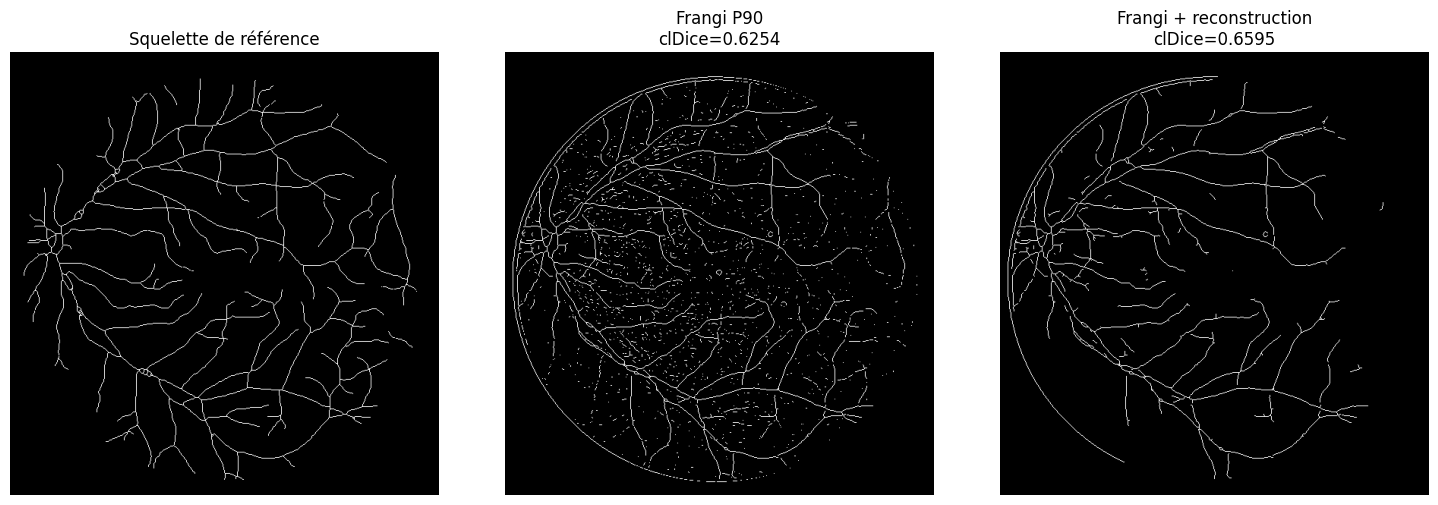

In [65]:


from skimage.morphology import skeletonize

# 1. Fonction de calcul du clDice
def calcul_cldice(prediction, reference):

    prediction = prediction.astype(bool)
    reference = reference.astype(bool)

    # Extraction des squelettes
    squelette_pred = skeletonize(prediction)
    squelette_ref = skeletonize(reference)

    # Précision topologique
    tprec = np.logical_and(
        squelette_pred, reference
    ).sum() / max(squelette_pred.sum(), 1)

    # Sensibilité topologique
    tsens = np.logical_and(
        squelette_ref, prediction
    ).sum() / max(squelette_ref.sum(), 1)

    # Calcul du clDice
    if tprec + tsens == 0:
        return 0.0

    return 2 * tprec * tsens / (tprec + tsens)


# 2. Récupération des segmentations
prediction_frangi = predictions_frangi[0]
prediction_recon = predictions_reconstruction[0]

# 3. Calcul des scores clDice
cldice_frangi = calcul_cldice(
    prediction_frangi, reference
)

cldice_recon = calcul_cldice(
    prediction_recon, reference
)

# 4. Affichage des résultats
print("===== EVALUATION clDice - DRIVE =====")

print(f"Frangi P90 : clDice = {cldice_frangi:.4f}")
print(f"Frangi + reconstruction : clDice = {cldice_recon:.4f}")

print("\n===== RAPPEL DES SCORES DICE =====")
print(f"Frangi P90 : Dice = {dice_frangi[0]:.4f}")
print(f"Frangi + reconstruction : Dice = {scores_reconstruction[0]:.4f}")


# 5. Visualisation des squelettes
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(skeletonize(reference), cmap="gray")
axes[0].set_title("Squelette de référence")

axes[1].imshow(skeletonize(prediction_frangi), cmap="gray")
axes[1].set_title(f"Frangi P90\nclDice={cldice_frangi:.4f}")

axes[2].imshow(skeletonize(prediction_recon), cmap="gray")
axes[2].set_title(
    f"Frangi + reconstruction\nclDice={cldice_recon:.4f}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


On remarque que le clDice passe de **0,6254 avec Frangi P90 à 0,6595 après reconstruction morphologique**. Sur les images, la reconstruction réduit les petits éléments parasites tout en conservant une grande partie des structures principales.

Cette amélioration confirme les résultats obtenus avec le Dice (0,6377 à 0,6526). Cependant, certains vaisseaux fins restent absents et la continuité des structures n'est pas toujours parfaitement respectée.

**Conclusion :** La reconstruction morphologique améliore légèrement la segmentation sur cette image, notamment la correspondance des structures centrales. Le clDice complète donc le Dice classique pour mieux évaluer les structures fines et allongées.

## Évaluation avec l'indice de Tversky :

In [66]:

# =====================================================
# DRIVE - Evaluation avec l'indice de Tversky
# =====================================================

import numpy as np
import pandas as pd

# 1. Fonction de calcul de Tversky
def calcul_tversky(prediction, reference, alpha=0.5, beta=0.5):

    prediction = prediction.astype(bool)
    reference = reference.astype(bool)

    VP = np.logical_and(prediction, reference).sum()
    FP = np.logical_and(prediction, ~reference).sum()
    FN = np.logical_and(~prediction, reference).sum()

    denominateur = VP + alpha * FP + beta * FN

    if denominateur == 0:
        return 1.0

    return VP / denominateur


# 2. Segmentations à comparer
segmentations = {
    "Frangi P90": predictions_frangi[0],
    "Frangi + reconstruction": predictions_reconstruction[0]
}

# 3. Différentes configurations
configurations = [
    ("Equilibrée", 0.5, 0.5),
    ("Pénalisation FN", 0.3, 0.7),
    ("Pénalisation FP", 0.7, 0.3)
]

# 4. Calcul des scores
resultats_tversky = []

for nom, prediction in segmentations.items():

    for configuration, alpha, beta in configurations:

        score = calcul_tversky(
            prediction,
            reference,
            alpha=alpha,
            beta=beta
        )

        resultats_tversky.append({
            "Méthode": nom,
            "Configuration": configuration,
            "Alpha": alpha,
            "Beta": beta,
            "Tversky": score
        })

# 5. Tableau comparatif
df_tversky = pd.DataFrame(resultats_tversky)

print("===== EVALUATION TVERSKY - DRIVE =====")
display(df_tversky.round(4))


===== EVALUATION TVERSKY - DRIVE =====


,Méthode,Configuration,Alpha,Beta,Tversky
0,Frangi P90,Equilibrée,0.5,0.5,0.6377
1,Frangi P90,Pénalisation FN,0.3,0.7,0.6266
2,Frangi P90,Pénalisation FP,0.7,0.3,0.6492
3,Frangi + reconstruction,Equilibrée,0.5,0.5,0.6526
4,Frangi + reconstruction,Pénalisation FN,0.3,0.7,0.6125
5,Frangi + reconstruction,Pénalisation FP,0.7,0.3,0.6982



Nous avons utilisé l'indice de Tversky pour comparer les segmentations en donnant plus d'importance aux faux positifs ou aux faux négatifs.

On remarque que **la reconstruction améliore le score lorsque les FP sont davantage pénalisés**, en passant de 0,6492 à 0,6982. Cela montre qu'elle permet de réduire les fausses détections.

En revanche, lorsque les FN sont davantage pénalisés, le score diminue de 0,6266 à 0,6125. Cela peut s'expliquer par la suppression de certains vaisseaux fins lors du nettoyage.

**Conclusion :** La reconstruction morphologique réduit les faux positifs, mais peut également faire perdre des parties des vaisseaux. Il faut donc trouver un compromis entre la réduction du bruit et la conservation des structures fines.

### Préparation des données pour U-Net :

===== PRÉPARATION U-NET DRIVE =====
Nombre total d'images : 20
Images d'entraînement : 16
Images de validation : 4

Dimensions entraînement : torch.Size([16, 1, 256, 256])
Dimensions validation : torch.Size([4, 1, 256, 256])

Valeurs des annotations : tensor([0., 1.])

Images de validation : ['21_training.tif', '38_training.tif', '36_training.tif', '22_training.tif']


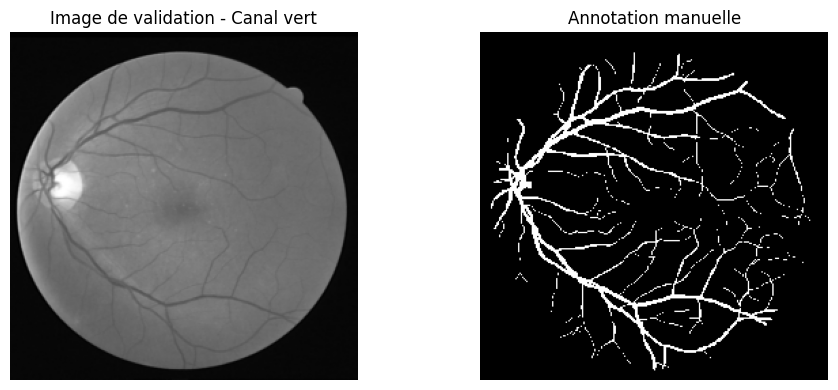

In [68]:

from sklearn.model_selection import train_test_split

taille = (256, 256)

images_drive = []
masques_drive = []

# 2. Chargement des images et des annotations
for numero in range(21, 41):

    image_path = os.path.join(
        drive_path, "training", "images",
        f"{numero}_training.tif"
    )

    annotation_path = os.path.join(
        drive_path, "training", "1st_manual",
        f"{numero}_manual1.gif"
    )

    masque_path = os.path.join(
        drive_path, "training", "mask",
        f"{numero}_training_mask.gif"
    )

    # Image originale : extraction du canal vert
    image = Image.open(image_path).convert("RGB")
    image = np.array(image)[:, :, 1]

    # Redimensionnement et normalisation
    image = Image.fromarray(image)
    image = image.resize(taille, Image.Resampling.BILINEAR)
    image = np.array(image, dtype=np.float32) / 255.0

    # Annotation manuelle des vaisseaux
    annotation = Image.open(annotation_path).convert("L")
    annotation = annotation.resize(taille, Image.Resampling.NEAREST)
    annotation = np.array(annotation) > 0

    # Masque de la région rétinienne
    masque = Image.open(masque_path).convert("L")
    masque = masque.resize(taille, Image.Resampling.NEAREST)
    masque = np.array(masque) > 0

    # Conservation des vaisseaux dans la région rétinienne
    annotation = (annotation & masque).astype(np.float32)

    images_drive.append(image)
    masques_drive.append(annotation)

# 3. Conversion en tableaux NumPy
X_drive = np.array(images_drive)
Y_drive = np.array(masques_drive)

# 4. Séparation : 80 % entraînement, 20 % validation
indices = np.arange(len(X_drive))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

# 5. Conversion en tenseurs PyTorch
X_train_drive = torch.from_numpy(
    X_drive[train_idx, None, :, :]
).float()

Y_train_drive = torch.from_numpy(
    Y_drive[train_idx, None, :, :]
).float()

X_val_drive = torch.from_numpy(
    X_drive[val_idx, None, :, :]
).float()

Y_val_drive = torch.from_numpy(
    Y_drive[val_idx, None, :, :]
).float()

# 6. Vérification
print("===== PRÉPARATION U-NET DRIVE =====")
print("Nombre total d'images :", len(X_drive))
print("Images d'entraînement :", len(X_train_drive))
print("Images de validation :", len(X_val_drive))

print("\nDimensions entraînement :", X_train_drive.shape)
print("Dimensions validation :", X_val_drive.shape)

print("\nValeurs des annotations :", torch.unique(Y_train_drive))

print("\nImages de validation :",
      [f"{i + 21}_training.tif" for i in val_idx])

# 7. Visualisation d'une image de validation
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(X_val_drive[0, 0], cmap="gray")
axes[0].set_title("Image de validation - Canal vert")

axes[1].imshow(Y_val_drive[0, 0], cmap="gray")
axes[1].set_title("Annotation manuelle")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Ici ,nous avons préparé les **20 images du dataset DRIVE** pour l'entraînement du U-Net. Nous avons d'abord extrait le **canal vert**, Les images ont ensuite été redimensionnées à **256 × 256 pixels** puis normalisées entre 0 et 1 pour faciliter l'apprentissage.

Les annotations manuelles ont été transformées en **masques binaires**, avec 0 pour le fond et 1 pour les vaisseaux. Le masque rétinien a permis de limiter les annotations à la zone de la rétine.

Nous avons ensuite séparé les données en **16 images d'entraînement et 4 images de validation**. Cette validation permettra de vérifier si le modèle fonctionne aussi sur des images non utilisées pour apprendre et de repérer un éventuel surapprentissage.

Les dimensions des tenseurs confirment que les données sont correctement préparées pour PyTorch. Aussi, la visualisation montre une bonne correspondance entre l'image rétinienne et son annotation manuelle.

### Construction du modéle :

In [69]:

# 1. Bloc de deux convolutions
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


# 2. Architecture U-Net
class UNetDRIVE(nn.Module):
    def __init__(self):
        super().__init__()

        # Encodeur
        self.enc1 = DoubleConv(1, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)

        self.pool = nn.MaxPool2d(2)

        # Partie centrale
        self.bottleneck = DoubleConv(64, 128)

        # Décodeur
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)

        # Sortie : une probabilité par pixel
        self.final = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):

        # Encodeur
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Partie centrale
        b = self.bottleneck(self.pool(e3))

        # Décodeur avec connexions U-Net
        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.final(d1)


# 3. Création du modèle
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

modele_drive = UNetDRIVE().to(device)

# 4. Vérification avec une image de validation
modele_drive.eval()

with torch.no_grad():
    exemple = X_val_drive[:1].to(device)
    sortie = modele_drive(exemple)
    probabilites = torch.sigmoid(sortie)

# 5. Résultats
print("===== ARCHITECTURE U-NET DRIVE =====")
print("Appareil utilisé :", device)
print("Dimension de l'entrée :", exemple.shape)
print("Dimension de la sortie :", sortie.shape)

nb_parametres = sum(
    p.numel() for p in modele_drive.parameters()
)

print("Nombre de paramètres :", nb_parametres)
print("Probabilité minimale :", probabilites.min().item())
print("Probabilité maximale :", probabilites.max().item())


===== ARCHITECTURE U-NET DRIVE =====
Appareil utilisé : cpu
Dimension de l'entrée : torch.Size([1, 1, 256, 256])
Dimension de la sortie : torch.Size([1, 1, 256, 256])
Nombre de paramètres : 481745
Probabilité minimale : 0.560646653175354
Probabilité maximale : 0.5637171268463135


Nous avons construit un U-Net léger contenant **481 745 params**. Le modèle reçoit une image à un seul canal de taille 256 × 256 et produit une carte de segmentation de même dimension.

Les probabilités obtenues sont comprises entre **0,5606 et 0,5637**. Elles sont presque identiques, car le réseau n'a pas encore été entraîné et ses paramètres sont initialisés aléatoirement.


### Entrainement + Validation de notre U-net :

===== ENTRAÎNEMENT U-NET DRIVE =====
Époque 01/20 | Train Loss : 0.8257 | Val Loss : 0.8174 | Val Dice : 0.1651
Époque 02/20 | Train Loss : 0.8181 | Val Loss : 0.8070 | Val Dice : 0.1651
Époque 03/20 | Train Loss : 0.7963 | Val Loss : 0.7125 | Val Dice : 0.0000
Époque 04/20 | Train Loss : 0.6984 | Val Loss : 0.6264 | Val Dice : 0.0000
Époque 05/20 | Train Loss : 0.6635 | Val Loss : 0.6818 | Val Dice : 0.0000
Époque 06/20 | Train Loss : 0.6488 | Val Loss : 0.6447 | Val Dice : 0.0000
Époque 07/20 | Train Loss : 0.6246 | Val Loss : 0.6125 | Val Dice : 0.0000
Époque 08/20 | Train Loss : 0.6144 | Val Loss : 0.5997 | Val Dice : 0.0000
Époque 09/20 | Train Loss : 0.5965 | Val Loss : 0.5932 | Val Dice : 0.0000
Époque 10/20 | Train Loss : 0.5850 | Val Loss : 0.5829 | Val Dice : 0.0000
Époque 11/20 | Train Loss : 0.5760 | Val Loss : 0.5720 | Val Dice : 0.0000
Époque 12/20 | Train Loss : 0.5714 | Val Loss : 0.5686 | Val Dice : 0.0000
Époque 13/20 | Train Loss : 0.5656 | Val Loss : 0.5644 | Val Di

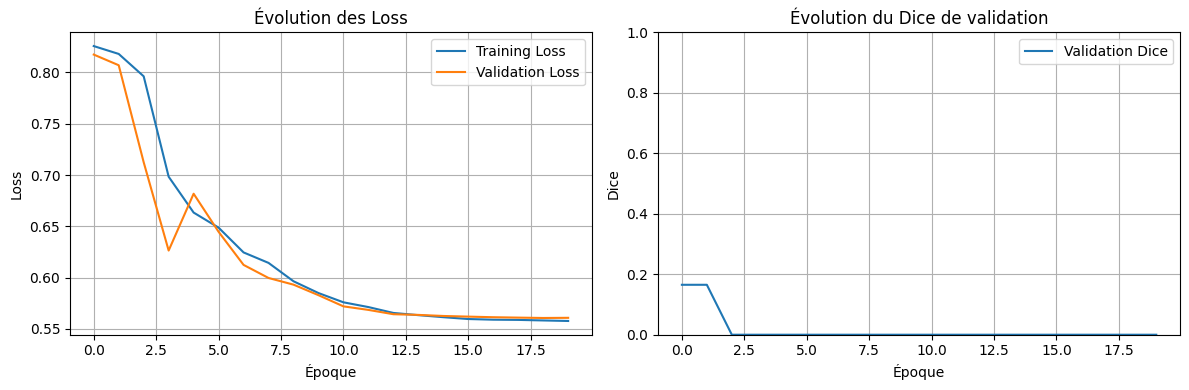

In [70]:

# =====================================================
# DRIVE - Entraînement U-Net avec validation
# =====================================================

from torch.utils.data import TensorDataset, DataLoader
import copy

# 1. Préparation des DataLoaders
train_loader = DataLoader(
    TensorDataset(X_train_drive, Y_train_drive),
    batch_size=4,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_drive, Y_val_drive),
    batch_size=4,
    shuffle=False
)

# 2. Fonction Dice différentiable
def dice_loss(logits, cible, eps=1e-6):
    proba = torch.sigmoid(logits)

    intersection = (proba * cible).sum(dim=(1, 2, 3))
    total = proba.sum(dim=(1, 2, 3)) + cible.sum(dim=(1, 2, 3))

    dice = (2 * intersection + eps) / (total + eps)
    return 1 - dice.mean()

# 3. Fonction de perte combinée
bce = nn.BCEWithLogitsLoss()

def fonction_perte(logits, cible):
    return 0.5 * bce(logits, cible) + 0.5 * dice_loss(logits, cible)

# 4. Optimiseur
optimiseur = torch.optim.Adam(
    modele_drive.parameters(),
    lr=0.001
)

# 5. Fonction Dice pour l'évaluation
def dice_evaluation(logits, cible, eps=1e-6):
    prediction = (torch.sigmoid(logits) > 0.5).float()

    intersection = (prediction * cible).sum(dim=(1, 2, 3))
    total = prediction.sum(dim=(1, 2, 3)) + cible.sum(dim=(1, 2, 3))

    return ((2 * intersection + eps) / (total + eps)).mean().item()

# 6. Entraînement
nombre_epoques = 20

historique_train = []
historique_val = []
historique_dice = []

meilleur_dice = -1
meilleurs_poids = None

print("===== ENTRAÎNEMENT U-NET DRIVE =====")

for epoque in range(nombre_epoques):

    # Phase d'entraînement
    modele_drive.train()
    perte_train = 0

    for images, masques in train_loader:
        images = images.to(device)
        masques = masques.to(device)

        optimiseur.zero_grad()

        sorties = modele_drive(images)
        perte = fonction_perte(sorties, masques)

        perte.backward()
        optimiseur.step()

        perte_train += perte.item() * images.size(0)

    perte_train /= len(train_loader.dataset)

    # Phase de validation
    modele_drive.eval()
    perte_val = 0
    scores_dice = []

    with torch.no_grad():
        for images, masques in val_loader:
            images = images.to(device)
            masques = masques.to(device)

            sorties = modele_drive(images)

            perte = fonction_perte(sorties, masques)
            perte_val += perte.item() * images.size(0)

            scores_dice.append(
                dice_evaluation(sorties, masques)
            )

    perte_val /= len(val_loader.dataset)
    dice_val = np.mean(scores_dice)

    historique_train.append(perte_train)
    historique_val.append(perte_val)
    historique_dice.append(dice_val)

    # Conserver le meilleur modèle selon le Dice de validation
    if dice_val > meilleur_dice:
        meilleur_dice = dice_val
        meilleurs_poids = copy.deepcopy(modele_drive.state_dict())
        meilleure_epoque = epoque + 1

    print(
        f"Époque {epoque+1:02d}/{nombre_epoques} | "
        f"Train Loss : {perte_train:.4f} | "
        f"Val Loss : {perte_val:.4f} | "
        f"Val Dice : {dice_val:.4f}"
    )

# 7. Restaurer le meilleur modèle
modele_drive.load_state_dict(meilleurs_poids)

print("\n===== MEILLEUR RÉSULTAT =====")
print("Meilleure époque :", meilleure_epoque)
print(f"Meilleur Dice de validation : {meilleur_dice:.4f}")

# 8. Visualisation des courbes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(historique_train, label="Training Loss")
axes[0].plot(historique_val, label="Validation Loss")
axes[0].set_title("Évolution des Loss")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(historique_dice, label="Validation Dice")
axes[1].set_title("Évolution du Dice de validation")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Dice")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


Les Loss d'entraînement et de validation diminuent progressivement de **0,82 à 0,56**, mais le Dice de validation devient nul dès la troisième époque. Cela montre que le U-Net réduit ses erreurs sans réussir à segmenter les vaisseaux.

Ce résultat peut s'expliquer par le **déséquilibre entre les classes**, car les pixels du fond sont beaucoup plus nombreux que ceux des vaisseaux. Le modèle semble donc privilégier le fond.

Nous allons visualiser les prédictions pour vérifier cette hypothèse avant d'améliorer l'entraînement.

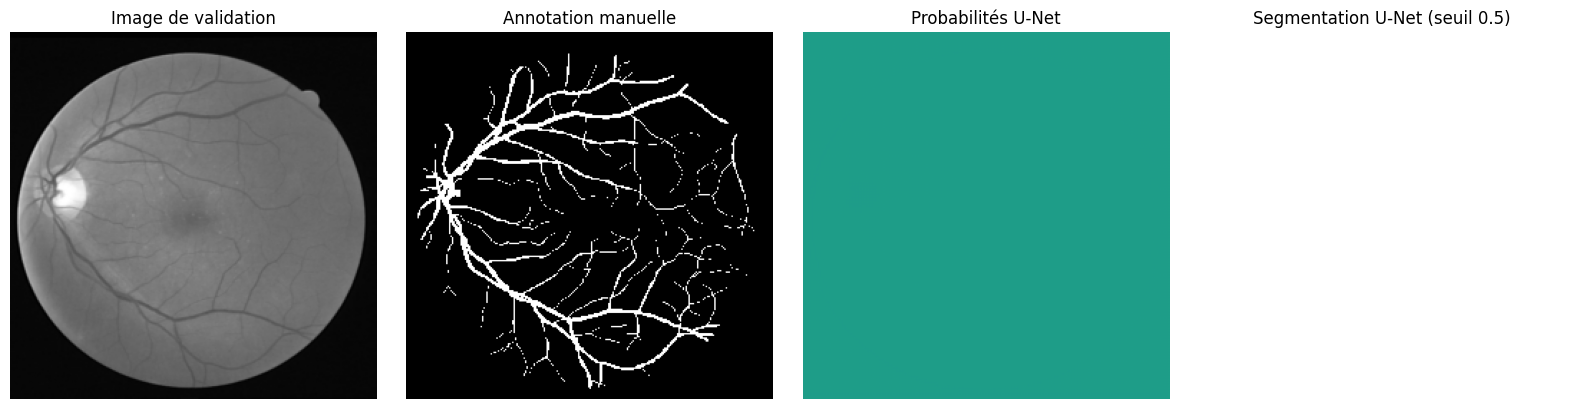

===== ANALYSE DES PRÉDICTIONS =====
Probabilité minimale : 0.5541
Probabilité maximale : 0.5590
Probabilité moyenne : 0.5549

Pixels de vaisseaux dans l'annotation : 7.50 %
Pixels prédits comme vaisseaux : 100.00 %


In [71]:

# Le meilleur modèle a été restauré après l'entraînement
modele_drive.eval()

with torch.no_grad():
    # Première image de validation
    image = X_val_drive[0:1].to(device)

    # Prédiction du modèle
    logits = modele_drive(image)
    probabilites = torch.sigmoid(logits)

    # Segmentation binaire avec un seuil de 0.5
    prediction = (probabilites > 0.5).float()

# Conversion en NumPy pour l'affichage
image_np = image[0, 0].cpu().numpy()
reference_np = Y_val_drive[0, 0].cpu().numpy()
proba_np = probabilites[0, 0].cpu().numpy()
prediction_np = prediction[0, 0].cpu().numpy()

# Visualisation
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(image_np, cmap="gray")
axes[0].set_title("Image de validation")

axes[1].imshow(reference_np, cmap="gray")
axes[1].set_title("Annotation manuelle")

axes[2].imshow(proba_np, cmap="viridis", vmin=0, vmax=1)
axes[2].set_title("Probabilités U-Net")

axes[3].imshow(prediction_np, cmap="gray", vmin=0, vmax=1)
axes[3].set_title("Segmentation U-Net (seuil 0.5)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Statistiques des prédictions
print("===== ANALYSE DES PRÉDICTIONS =====")

print(f"Probabilité minimale : {proba_np.min():.4f}")
print(f"Probabilité maximale : {proba_np.max():.4f}")
print(f"Probabilité moyenne : {proba_np.mean():.4f}")

print(f"\nPixels de vaisseaux dans l'annotation : {reference_np.mean()*100:.2f} %")
print(f"Pixels prédits comme vaisseaux : {prediction_np.mean()*100:.2f} %")

La visualisation montre que le U-Net ne distingue pas encore les vaisseaux du fond. Les probabilités sont presque constantes, entre **0,5541 et 0,5590**. Comme elles dépassent toutes le seuil de 0,5, le modèle classe **100 % des pixels comme des vaisseaux**, alors que ceux-ci représentent seulement **7,5 % de l'annotation**.

Ce résultat correspond au modèle de la première époque, conservé car il avait obtenu le meilleur Dice de validation (0,1651). Le modèle n'a donc pas encore appris à reconnaître les structures vasculaires. Nous allons améliorer son entraînement en tenant davantage compte du déséquilibre entre les classes.

### Amélioration du U-Net avec une BCE pondérée :

===== RÉPARTITION DES CLASSES =====
Pixels de vaisseaux : 8.55 %
Poids des vaisseaux : 10.70

===== ENTRAÎNEMENT U-NET PONDÉRÉ =====
Époque 01/20 | Train Loss : 1.0622 | Val Loss : 1.0734 | Val Dice : 0.0000
Époque 02/20 | Train Loss : 1.0580 | Val Loss : 1.0662 | Val Dice : 0.0000
Époque 03/20 | Train Loss : 1.0499 | Val Loss : 1.0509 | Val Dice : 0.2326
Époque 04/20 | Train Loss : 1.0321 | Val Loss : 1.0238 | Val Dice : 0.2339
Époque 05/20 | Train Loss : 1.0040 | Val Loss : 0.9825 | Val Dice : 0.2342
Époque 06/20 | Train Loss : 0.9587 | Val Loss : 0.9430 | Val Dice : 0.2342
Époque 07/20 | Train Loss : 0.9191 | Val Loss : 0.9137 | Val Dice : 0.2358
Époque 08/20 | Train Loss : 0.9108 | Val Loss : 0.9144 | Val Dice : 0.2351
Époque 09/20 | Train Loss : 0.9083 | Val Loss : 0.9158 | Val Dice : 0.2333
Époque 10/20 | Train Loss : 0.9076 | Val Loss : 0.9117 | Val Dice : 0.2348
Époque 11/20 | Train Loss : 0.9060 | Val Loss : 0.9112 | Val Dice : 0.2351
Époque 12/20 | Train Loss : 0.9059 | Val L

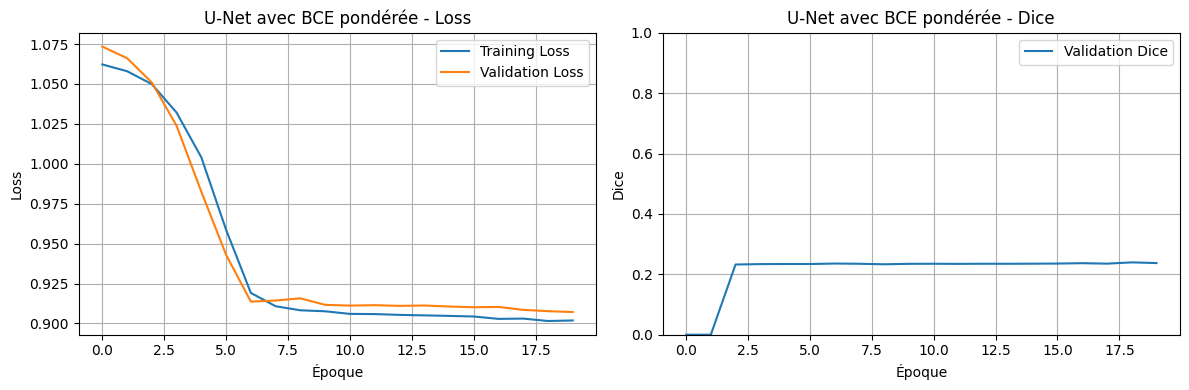

In [72]:

import copy
from torch.utils.data import TensorDataset, DataLoader

# 1. Réinitialiser le modèle
modele_drive_pondere = UNetDRIVE().to(device)

# 2. Calculer le déséquilibre à partir de l'entraînement
nb_vaisseaux = Y_train_drive.sum().item()
nb_fond = Y_train_drive.numel() - nb_vaisseaux

poids_vaisseaux = nb_fond / nb_vaisseaux

print("===== RÉPARTITION DES CLASSES =====")
print(f"Pixels de vaisseaux : {100 * nb_vaisseaux / Y_train_drive.numel():.2f} %")
print(f"Poids des vaisseaux : {poids_vaisseaux:.2f}")

# 3. BCE pondérée + Dice Loss
bce_ponderee = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [poids_vaisseaux],
        dtype=torch.float32,
        device=device
    )
)

def perte_ponderee(logits, cible):
    return (
        0.5 * bce_ponderee(logits, cible)
        + 0.5 * dice_loss(logits, cible)
    )

# 4. DataLoaders
train_loader = DataLoader(
    TensorDataset(X_train_drive, Y_train_drive),
    batch_size=4,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_drive, Y_val_drive),
    batch_size=4,
    shuffle=False
)

# 5. Optimiseur
optimiseur = torch.optim.Adam(
    modele_drive_pondere.parameters(),
    lr=0.001
)

# 6. Entraînement et validation
nombre_epoques = 20

train_loss_ponderee = []
val_loss_ponderee = []
val_dice_pondere = []

meilleur_dice_pondere = -1
meilleurs_poids_ponderes = None
meilleure_epoque_ponderee = 0

print("\n===== ENTRAÎNEMENT U-NET PONDÉRÉ =====")

for epoque in range(nombre_epoques):

    # Entraînement
    modele_drive_pondere.train()
    total_train = 0.0

    for images, masques in train_loader:
        images = images.to(device)
        masques = masques.to(device)

        optimiseur.zero_grad()

        sorties = modele_drive_pondere(images)
        perte = perte_ponderee(sorties, masques)

        perte.backward()
        optimiseur.step()

        total_train += perte.item() * images.size(0)

    moyenne_train = total_train / len(train_loader.dataset)

    # Validation
    modele_drive_pondere.eval()
    total_val = 0.0
    somme_dice = 0.0
    nb_images_val = 0

    with torch.no_grad():
        for images, masques in val_loader:
            images = images.to(device)
            masques = masques.to(device)

            sorties = modele_drive_pondere(images)
            perte = perte_ponderee(sorties, masques)

            total_val += perte.item() * images.size(0)

            dice_batch = dice_evaluation(sorties, masques)
            somme_dice += dice_batch * images.size(0)
            nb_images_val += images.size(0)

    moyenne_val = total_val / len(val_loader.dataset)
    moyenne_dice = somme_dice / nb_images_val

    train_loss_ponderee.append(moyenne_train)
    val_loss_ponderee.append(moyenne_val)
    val_dice_pondere.append(moyenne_dice)

    if moyenne_dice > meilleur_dice_pondere:
        meilleur_dice_pondere = moyenne_dice
        meilleure_epoque_ponderee = epoque + 1
        meilleurs_poids_ponderes = copy.deepcopy(
            modele_drive_pondere.state_dict()
        )

    print(
        f"Époque {epoque+1:02d}/{nombre_epoques} | "
        f"Train Loss : {moyenne_train:.4f} | "
        f"Val Loss : {moyenne_val:.4f} | "
        f"Val Dice : {moyenne_dice:.4f}"
    )

# 7. Restaurer le meilleur modèle
modele_drive_pondere.load_state_dict(
    meilleurs_poids_ponderes
)

print("\n===== MEILLEUR RÉSULTAT =====")
print("Meilleure époque :", meilleure_epoque_ponderee)
print(f"Meilleur Dice de validation : {meilleur_dice_pondere:.4f}")

# 8. Courbes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_loss_ponderee, label="Training Loss")
axes[0].plot(val_loss_ponderee, label="Validation Loss")
axes[0].set_title("U-Net avec BCE pondérée - Loss")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(val_dice_pondere, label="Validation Dice")
axes[1].set_title("U-Net avec BCE pondérée - Dice")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Dice")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


Avec la **BCE pondérée**, les Loss d'entraînement et de validation diminuent progressivement, passant d'environ **1,06 à 0,90**. Le poids des vaisseaux, fixé à **10,70**, permet de donner plus d'importance à cette classe minoritaire, qui représente seulement 8,55 % des pixels d'entraînement.

Le meilleur Dice de validation atteint **0,2396 à l'époque 19**, contre 0,1651 avec le premier U-Net. La pondération apporte donc une amélioration, même si les performances restent faibles.

Nous allons maintenant visualiser les nouvelles segmentations pour vérifier si le modèle détecte mieux les vaisseaux sanguins.

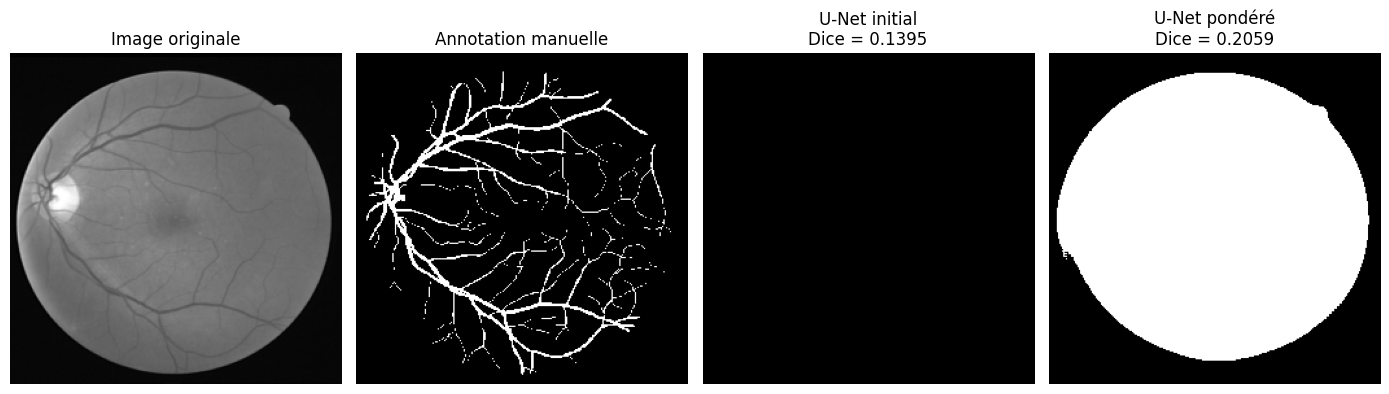

In [73]:

image = X_val_drive[0:1].to(device)
reference = Y_val_drive[0, 0].numpy()

modele_drive.eval()
modele_drive_pondere.eval()

with torch.no_grad():
    pred_initiale = (torch.sigmoid(modele_drive(image)) > 0.5)[0, 0].cpu().numpy()
    pred_ponderee = (torch.sigmoid(modele_drive_pondere(image)) > 0.5)[0, 0].cpu().numpy()

# Calcul du Dice
def dice(pred, ref):
    return 2 * (pred & ref.astype(bool)).sum() / max(pred.sum() + ref.sum(), 1)

# Affichage
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

images = [image[0, 0].cpu().numpy(), reference, pred_initiale, pred_ponderee]
titres = [
    "Image originale",
    "Annotation manuelle",
    f"U-Net initial\nDice = {dice(pred_initiale, reference):.4f}",
    f"U-Net pondéré\nDice = {dice(pred_ponderee, reference):.4f}"
]

for ax, img, titre in zip(axes, images, titres):
    ax.imshow(img, cmap="gray")
    ax.set_title(titre)
    ax.axis("off")

plt.tight_layout()
plt.show()

La comparaison montre que le **U-Net initial prédit presque uniquement du fond**, tandis que le **U-Net avec BCE pondérée considère presque toute la rétine comme des vaisseaux**.

Le Dice passe de **0,1395 à 0,2059**, mais cette amélioration est insuffisante, car les vaisseaux ne sont pas correctement distingués. La BCE pondérée augmente donc la détection des pixels positifs, mais entraîne ici de nombreuses fausses détections.

Nous allons chercher à améliorer l'apprentissage pour que le modèle reconnaisse réellement les structures vasculaires, plutôt que de privilégier une seule classe.

### Améliorer U-Net avec la Dice Loss :

Époque 01/20 | Dice Loss : 0.8527 | Validation Dice : 0.1651
Époque 02/20 | Dice Loss : 0.8516 | Validation Dice : 0.1651
Époque 03/20 | Dice Loss : 0.8495 | Validation Dice : 0.1651
Époque 04/20 | Dice Loss : 0.8441 | Validation Dice : 0.1651
Époque 05/20 | Dice Loss : 0.8378 | Validation Dice : 0.1651
Époque 06/20 | Dice Loss : 0.8339 | Validation Dice : 0.1651
Époque 07/20 | Dice Loss : 0.8254 | Validation Dice : 0.2029
Époque 08/20 | Dice Loss : 0.8169 | Validation Dice : 0.2238
Époque 09/20 | Dice Loss : 0.8145 | Validation Dice : 0.2276
Époque 10/20 | Dice Loss : 0.8082 | Validation Dice : 0.2346
Époque 11/20 | Dice Loss : 0.8002 | Validation Dice : 0.2352
Époque 12/20 | Dice Loss : 0.7791 | Validation Dice : 0.2323
Époque 13/20 | Dice Loss : 0.7797 | Validation Dice : 0.2328
Époque 14/20 | Dice Loss : 0.7762 | Validation Dice : 0.2398
Époque 15/20 | Dice Loss : 0.7670 | Validation Dice : 0.2351
Époque 16/20 | Dice Loss : 0.7721 | Validation Dice : 0.2378
Époque 17/20 | Dice Loss

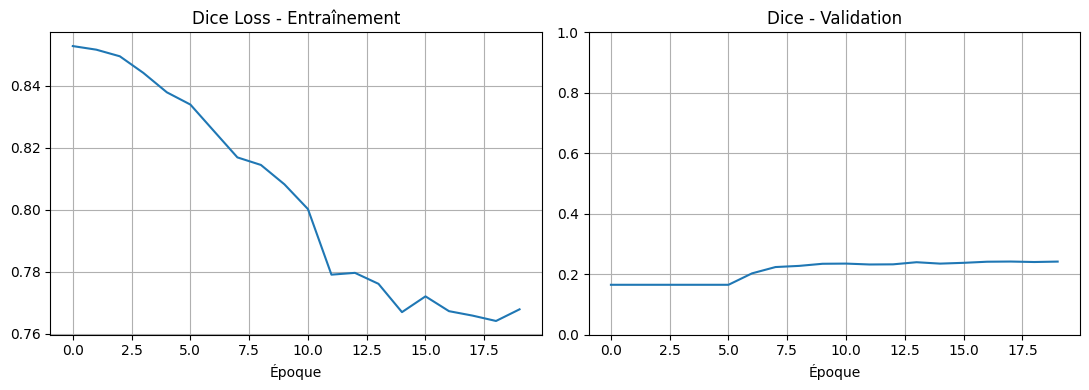

In [74]:

# =====================================================
# DRIVE - U-Net avec Dice Loss uniquement
# =====================================================

import copy

# Nouveau U-Net avec les mêmes données
modele_dice = UNetDRIVE().to(device)
optimiseur = torch.optim.Adam(modele_dice.parameters(), lr=0.001)

historique_dice_loss = []
historique_dice_val = []

meilleur_dice = -1

for epoque in range(20):

    # Entraînement
    modele_dice.train()
    pertes = []

    for images, masques in train_loader:
        images, masques = images.to(device), masques.to(device)

        optimiseur.zero_grad()
        sortie = modele_dice(images)
        perte = dice_loss(sortie, masques)
        perte.backward()
        optimiseur.step()

        pertes.append(perte.item())

    # Validation
    modele_dice.eval()
    scores = []

    with torch.no_grad():
        for images, masques in val_loader:
            images, masques = images.to(device), masques.to(device)
            sortie = modele_dice(images)
            scores.append(dice_evaluation(sortie, masques))

    score_val = np.mean(scores)
    historique_dice_loss.append(np.mean(pertes))
    historique_dice_val.append(score_val)

    if score_val > meilleur_dice:
        meilleur_dice = score_val
        meilleure_epoque = epoque + 1
        meilleurs_poids = copy.deepcopy(modele_dice.state_dict())

    print(f"Époque {epoque+1:02d}/20 | "
          f"Dice Loss : {np.mean(pertes):.4f} | "
          f"Validation Dice : {score_val:.4f}")

# Restaurer le meilleur modèle
modele_dice.load_state_dict(meilleurs_poids)

print(f"\nMeilleur Dice de validation : {meilleur_dice:.4f}")
print(f"Meilleure époque : {meilleure_epoque}")

# Courbes
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(historique_dice_loss)
axes[0].set_title("Dice Loss - Entraînement")
axes[0].set_xlabel("Époque")
axes[0].grid(True)

axes[1].plot(historique_dice_val)
axes[1].set_title("Dice - Validation")
axes[1].set_xlabel("Époque")
axes[1].set_ylim(0, 1)
axes[1].grid(True)

plt.tight_layout()
plt.show()


Avec la **Dice Loss seule**, la perte d'entraînement diminue progressivement de **0,8527 à 0,7679**, ce qui montre que le modèle améliore son apprentissage.

Le meilleur Dice de validation atteint **0,2420 à l'époque 18**, contre 0,2396 avec la BCE pondérée et 0,1651 avec le U-Net initial.

La Dice Loss donne donc le meilleur résultat parmi les trois méthodes, mais l'amélioration par rapport à la BCE pondérée reste très faible. Les performances restent insuffisantes pour obtenir une segmentation précise des vaisseaux.



### Comparaison visuelle des trois U-Net :

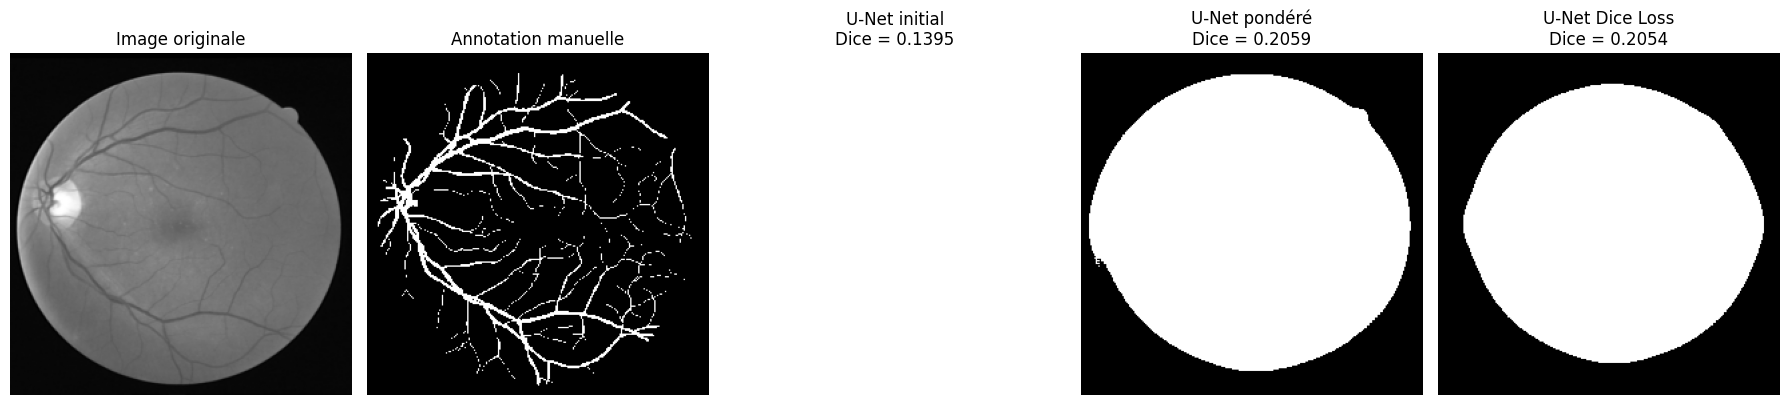

In [75]:
# Comparaison des trois U-Net sur une image de validation

image = X_val_drive[0:1].to(device)
reference = Y_val_drive[0, 0].cpu().numpy().astype(bool)

modeles = [modele_drive, modele_drive_pondere, modele_dice]
noms = ["U-Net initial", "U-Net pondéré", "U-Net Dice Loss"]

def calcul_dice(pred, ref):
    return 2 * (pred & ref).sum() / max(pred.sum() + ref.sum(), 1)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

axes[0].imshow(image[0, 0].cpu().numpy(), cmap="gray")
axes[0].set_title("Image originale")

axes[1].imshow(reference, cmap="gray")
axes[1].set_title("Annotation manuelle")

for i, (modele, nom) in enumerate(zip(modeles, noms)):
    modele.eval()

    with torch.no_grad():
        proba = torch.sigmoid(modele(image))
        pred = (proba > 0.5)[0, 0].cpu().numpy()

    score = calcul_dice(pred, reference)

    axes[i + 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[i + 2].set_title(f"{nom}\nDice = {score:.4f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

La comparaison montre que les trois U-Net ne parviennent pas encore à segmenter correctement les vaisseaux sanguins.

Le **U-Net initial** prédit presque uniquement du fond, avec un Dice de **0,1395**. En revanche, le **U-Net pondéré** et le **U-Net avec Dice Loss** détectent presque toute la région rétinienne comme des vaisseaux, avec des Dice respectifs de **0,2059 et 0,2054**.

Même si les scores augmentent légèrement, les deux derniers modèles produisent beaucoup de faux positifs et ne reproduisent pas les structures vasculaires.

## Comparaison des méthodes classiques avec le U-net :

In [76]:
# Comparaison Frangi / U-Net sur les 4 images de validation

from skimage.filters import frangi
from skimage.morphology import binary_erosion, reconstruction, disk

modeles = {
    "U-Net initial": modele_drive,
    "U-Net pondéré": modele_drive_pondere,
    "U-Net Dice Loss": modele_dice
}

scores = {"Frangi P90": [], "Frangi + reconstruction": []}
scores.update({nom: [] for nom in modeles})

def dice_score(pred, ref):
    pred, ref = pred.astype(bool), ref.astype(bool)
    return 2 * (pred & ref).sum() / max(pred.sum() + ref.sum(), 1)

for i in range(len(X_val_drive)):
    image = X_val_drive[i, 0].numpy()
    ref = Y_val_drive[i, 0].numpy().astype(bool)

    # Frangi P90 : seuil calculé dans la région rétinienne
    reponse = frangi(image, sigmas=np.arange(1, 5), black_ridges=True)
    masque = image > 0  # approximation du champ rétinien
    seuil = np.percentile(reponse[masque], 90)
    pred_frangi = (reponse > seuil) & masque

    # Reconstruction morphologique
    marqueur = binary_erosion(pred_frangi, footprint=disk(1))
    pred_recon = reconstruction(
        marqueur.astype(np.uint8),
        pred_frangi.astype(np.uint8),
        method="dilation"
    ) > 0

    scores["Frangi P90"].append(dice_score(pred_frangi, ref))
    scores["Frangi + reconstruction"].append(dice_score(pred_recon, ref))

    # Prédictions des trois U-Net
    entree = X_val_drive[i:i+1].to(device)

    for nom, modele in modeles.items():
        modele.eval()
        with torch.no_grad():
            pred = (torch.sigmoid(modele(entree)) > 0.5)[0, 0].cpu().numpy()
        scores[nom].append(dice_score(pred, ref))

# Résultats
print("===== COMPARAISON SUR LES 4 IMAGES DE VALIDATION =====")

for nom, valeurs in scores.items():
    print(f"{nom:26s} : Dice moyen = {np.mean(valeurs):.4f}")

===== COMPARAISON SUR LES 4 IMAGES DE VALIDATION =====
Frangi P90                 : Dice moyen = 0.5116
Frangi + reconstruction    : Dice moyen = 0.4587
U-Net initial              : Dice moyen = 0.1651
U-Net pondéré              : Dice moyen = 0.2396
U-Net Dice Loss            : Dice moyen = 0.2420


La comparaison sur les 4 images de validation montre que **Frangi P90 obtient le meilleur Dice moyen (0,5116)**, suivi de Frangi avec reconstruction morphologique (0,4587).

Les trois U-Net obtiennent des scores plus faibles, entre **0,1651 et 0,2420**. La BCE pondérée et la Dice Loss améliorent légèrement les résultats du U-Net initial, mais les segmentations restent peu précises.

La reconstruction morphologique diminue ici le Dice de Frangi, ce qui peut s'expliquer par la suppression de certains vaisseaux fins.

Dans nos expériences, Frangi P90 donne les meilleurs résultats. Les U-Net nécessiteraient davantage de données et un entraînement mieux adapté pour reconnaître correctement les vaisseaux sanguins.


# Conclusion générale

À travers ce TP, nous avons constaté qu'**il n'existe pas une méthode de segmentation qui soit la meilleure pour toutes les images médicales**. Le choix de la méthode dépend principalement de la forme de la structure recherchée, de son contraste avec les tissus voisins et de la qualité des images.

Les contours actifs ont été particulièrement intéressants pour les structures délimitées par des contours, comme le ventricule gauche, tandis que le filtre de Frangi a donné de meilleurs résultats pour les vaisseaux sanguins. À l'inverse, les méthodes fondées uniquement sur les intensités ont souvent sélectionné des régions qui ne correspondaient pas à la structure recherchée.

Les expériences avec U-Net nous ont également permis de comprendre que **la diminution de la Loss ne garantit pas une bonne segmentation**. La quantité de données, le déséquilibre entre les classes, la résolution et la fonction de perte influencent fortement l'apprentissage. L'ajout d'une validation et l'utilisation de fonctions de perte adaptées ont apporté des améliorations sur DRIVE, mais celles-ci sont restées limitées.

Enfin, nous avons compris l'importance de **combiner l'évaluation quantitative et l'observation visuelle**. Le Dice permet de mesurer le recouvrement global, mais d'autres métriques sont utiles pour analyser les contours, les structures fines et les erreurs de segmentation.

**Pour conclure, ce TP nous a permis de mieux comprendre les avantages et les limites des différentes méthodes de segmentation médicale.** Il montre surtout qu'obtenir un bon résultat nécessite non seulement de choisir un algorithme adapté, mais aussi de préparer correctement les données, de régler les paramètres et d'évaluer les segmentations avec plusieurs critères.